# NB02 CPU — Benchmark canónico H0-H3

- **Estatus:** canónico  
- **Objetivo:** ejecutar el benchmark oficial del paper sobre GARCH y LSTM bajo el esquema temporal `t+1` definido en NB01.  
- **Inputs mínimos:** `data/processed/wti_volatilidad_MODEL_BASE.csv`, `config/config_estudio_FINAL.json` y, cuando existen, artefactos complementarios de NB03A y NB03B.  
- **Outputs principales:** predicciones CSV, figuras comparativas, modelos/scalers serializados y actualización canónica de `nb02_results` + `nb02_metadata`.  
- **Config / gobernanza:** este notebook actualiza la capa canónica del benchmark CPU; no incorpora ni sustituye resultados GPU/Optuna.  
- **No inferir de este notebook:** las extensiones híbridas y la ablación de EarlyStopping son análisis complementarios; el benchmark canónico H0-H3 sigue definido por la tabla maestra CPU.
- **Contrato de config (runtime Colab):** NB02 CPU usa `BASE_PATH/config_estudio_FINAL.json` como ruta real de runtime. El archivo del repo `config/config_estudio_FINAL.json` es un espejo sincronizado después de la corrida.  
- **Orden oficial:** `NB01 -> NB03A (si aprobado) -> NB03B (si aprobado) -> NB02 CPU -> NB02 GPU opcional`. El flujo canónico mínimo sigue siendo `NB01 -> NB02 CPU`.  
- **Rol del writer:** este notebook consolida `nb02_results` y `nb02_metadata`, preserva `nb02_experiments`, `nb03` y `nb03b`, y es la única fuente oficial H0-H3.


## 0.1 IMPORTAR LIBRERÍAS Y VERIFICAR ENTORNO

In [1]:
import os

#  Modo de ejecución — editar aquí antes de cada corrida
# 'canonical_cpu' : corrida oficial (TF_DETERMINISTIC_OPS=1, WRITE_CONFIG=True)
# 'gpu_optuna'    : exploración GPU/Optuna (WRITE_CONFIG=False, resultados PROVISIONAL)
RUN_MODE = 'canonical_cpu'   # ← default para corrida de cierre canónico

# Propagar al entorno para herramientas externas y para WRITE_CONFIG de celda 85
os.environ['NB02_RUN_MODE'] = RUN_MODE
print(f"[CONFIG] NB02_RUN_MODE = {RUN_MODE}")

[CONFIG] NB02_RUN_MODE = canonical_cpu


In [2]:
#  Instalación arch con recompilación forzada ─
# Evita el error "numpy.dtype size changed" de wheels precompiladas.
# Guard autosuficiente: detecta Colab sin depender de IN_COLAB (aún no definido).
import subprocess
try:
    import google.colab as _gc
    _IN_COLAB_INSTALL = True
except ImportError:
    _IN_COLAB_INSTALL = False

if _IN_COLAB_INSTALL:
    subprocess.run(
        ['pip', 'install', 'arch', '--no-binary', 'arch', '-q'],
        check=True
    )
else:
    try:
        import arch as _arch_test
        print(f"arch ya instalado: {_arch_test.__version__}")
    except ImportError:
        print("WARN: arch no instalado. Ejecutar manualmente: pip install arch --no-binary arch")

# Limpiar módulo cacheado si ya estaba importado en esta sesión
import sys
for mod in list(sys.modules.keys()):
    if 'arch' in mod:
        del sys.modules[mod]

# Importar y verificar
import arch
import numpy as np

print(f"arch version  : {arch.__version__}")
print(f"numpy version : {np.__version__}")
assert int(arch.__version__.split('.')[0]) >= 5, \
    f"Versión insuficiente: {arch.__version__}. Se requiere >= 5.x"
print("arch OK ✓")

arch version  : 8.0.0
numpy version : 2.0.2
arch OK ✓


In [3]:
#  Backend inline: garantiza figuras embebidas en cell outputs (Colab + Jupyter)
# Debe ejecutarse ANTES de cualquier import de matplotlib.
%matplotlib inline
import matplotlib
matplotlib.rcParams["figure.max_open_warning"] = 40


In [4]:
#  0.2 Imports y patrón Colab
import json, random, warnings, pickle
#import sys
from datetime import datetime
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch
import matplotlib.patches as mpatches
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
import seaborn as sns
import scipy
import scipy.stats as stats
from scipy.stats import norm
# Sklearn
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    f1_score, roc_auc_score, precision_score, recall_score,
    confusion_matrix, roc_curve, precision_recall_curve,
    average_precision_score
)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import TimeSeriesSplit

# Imbalanced-learn
# from imblearn.over_sampling import SMOTE
# SMOTE prohibido: rompe estructura temporal. Usar class_weight.

# GARCH (arch package)
from arch import arch_model
from statsmodels.stats.diagnostic import het_arch, acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
import statsmodels.api as sm

# TensorFlow / Keras —
# Modo de ejecución:
# - canonical_cpu: benchmark canónico, reproducible, CPU-only (por defecto)
# - gpu_optuna:    runtime GPU dedicado para acelerar PARTE VIII
import os
RUN_MODE      = os.environ.get('NB02_RUN_MODE', 'canonical_cpu')
PART_VIII_GPU = (RUN_MODE == 'gpu_optuna')
if PART_VIII_GPU:
    os.environ.pop('CUDA_VISIBLE_DEVICES', None)
    os.environ['TF_DETERMINISTIC_OPS'] = '0'
else:
    os.environ['CUDA_VISIBLE_DEVICES'] = ''
    os.environ['TF_DETERMINISTIC_OPS'] = '1'
import tensorflow as tf
from tensorflow import keras
print(f"TF version     : {tf.__version__}")
print(f"Fecha ejecución: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

TF version     : 2.19.0
Fecha ejecución: 2026-03-29 15:50:54


In [5]:
#  0.3 Seeds de reproducibilidad (TODAS las fuentes)
import sys as _sys
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)
os.environ['PYTHONHASHSEED'] = str(RANDOM_SEED)
_gpus = tf.config.list_physical_devices("GPU")
_det = "N/A"
if PART_VIII_GPU:
    for gpu in _gpus:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except Exception:
            pass
    print(f'[ACELERACIÓN] GPUs visibles: {len(_gpus)} (esperado: >=1 en runtime GPU)')
    assert len(_gpus) >= 1, (
        'RUN_MODE=gpu_optuna, pero TensorFlow no detecta GPU. '
        'Reinicia el runtime con T4 antes de ejecutar el notebook.'
    )
else:
    print(f'[REPRODUCIBILIDAD] GPUs visibles: {len(_gpus)} (esperado: 0 — CPU-only)')
    assert len(_gpus) == 0, (
        'GPU detectada. Reiniciar runtime con CUDA_VISIBLE_DEVICES= antes de '
        'importar TF para garantizar reproducibilidad bit-a-bit.'
    )
    try:
        tf.config.experimental.enable_op_determinism()
        _det = "ON"
    except Exception:
        _det = "OFF (TF < 2.9)"
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option('display.float_format', '{:.6f}'.format)
print(f"RANDOM_SEED={RANDOM_SEED} | TF={tf.__version__} | "
      f"Python={_sys.version.split()[0]} | GPUs={len(_gpus)} | "
      f"determinism={_det} | RUN_MODE={RUN_MODE}")


[REPRODUCIBILIDAD] GPUs visibles: 0 (esperado: 0 — CPU-only)
RANDOM_SEED=42 | TF=2.19.0 | Python=3.12.13 | GPUs=0 | determinism=ON | RUN_MODE=canonical_cpu


> **Nota de reproducibilidad CPU vs GPU**
>
> Este notebook (`canonical_cpu`) es la referencia oficial del benchmark H0-H3 y la única corrida notebook que actualiza la capa canónica `nb02_results` / `nb02_metadata`.
>
> La variante GPU/Optuna vive en NB02 GPU, se documenta por separado en `nb02_experiments` y no redefine el benchmark CPU.
>
> La ablación EarlyStopping se conserva como análisis complementario interno y no redefine el benchmark canónico H0-H3.
>
> Aunque CPU y GPU comparten seeds, splits, features, umbrales y reglas anti-leakage, pueden aparecer diferencias numéricas menores por no determinismo de kernels GPU; por eso la referencia oficial para el cierre de tesis sigue siendo la corrida CPU canónica.

In [6]:
#  0.4 Versiones del entorno (reproducibilidad)
print("  ENTORNO DE EJECUCIÓN — NB02 WTI Benchmark")
print(f" \nPython          : {sys.version.split()[0]}")
print(f"  numpy           : {np.__version__}")
print(f"  pandas          : {pd.__version__}")
print(f"  tensorflow      : {tf.__version__}")
print(f"  arch            : {arch.__version__}")
print(f"  scikit-learn    : {sklearn.__version__}")
print(f"  statsmodels     : {sm.__version__}")
print(f"  scipy           : {scipy.__version__}")
print(f"  matplotlib      : {mpl.__version__}")
print(f"  seaborn         : {sns.__version__}")

  ENTORNO DE EJECUCIÓN — NB02 WTI Benchmark
 
Python          : 3.12.13
  numpy           : 2.0.2
  pandas          : 2.2.2
  tensorflow      : 2.19.0
  arch            : 8.0.0
  scikit-learn    : 1.6.1
  statsmodels     : 0.14.6
  scipy           : 1.16.3
  matplotlib      : 3.10.0
  seaborn         : 0.13.2


In [7]:
#  0.5 Rutas, detección de entorno y guards de integridad

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print(f"IN_COLAB : {IN_COLAB}")

if IN_COLAB:
    try:
        drive.mount('/content/drive', force_remount=False)
    except Exception as e:
        print(f"Drive ya montado o error: {e}")
    BASE_PATH   = "/content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos"
    NB02_PATH = "/content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB02_Benchmark"
    OUTPUT_PATH = NB02_PATH
    FIG_PATH    = f"{NB02_PATH}/Fig_NB02"
else:
    BASE_PATH   = "."
    OUTPUT_PATH = "."
    NB02_PATH   = "."
    FIG_PATH    = "./Fig_NB02"

CONFIG_RUNTIME_PATH = f"{BASE_PATH}/config_estudio_FINAL.json"
CONFIG_REPO_MIRROR = "config/config_estudio_FINAL.json"
CONFIG_PATH   = CONFIG_RUNTIME_PATH
CSV_PATH      = f"{BASE_PATH}/NB01_EDA/wti_volatilidad_MODEL_BASE.csv"
MARKET_SIGNALS_CSV = f"{BASE_PATH}/NB03B_MarketSignals/wti_market_signals.csv"
# FINBERT_CSV y MARKET_SIGNALS_CSV son las rutas canónicas (definidas en celdas 5.2 y aqui)

# Crear directorios necesarios
for _dir in [FIG_PATH,                            # figuras del benchmark
             f"{NB02_PATH}/predicciones_nb02",    # CSVs de predicciones por modelo
             f"{NB02_PATH}/modelos_nb02"]:        # Modelos Keras y scalers
    Path(_dir).mkdir(parents=True, exist_ok=True)
    print(f"  dir OK : {_dir}")

print(f"  config runtime : {CONFIG_RUNTIME_PATH}")
print(f"  espejo repo    : {CONFIG_REPO_MIRROR}")
print(f"  CSV            : {CSV_PATH}")
print("  flujo oficial  : NB01 -> NB03A (opt-in) -> NB03B (opt-in) -> NB02 CPU -> NB02 GPU opcional")
print("  flujo mínimo   : NB01 -> NB02 CPU")

IN_COLAB : True
Mounted at /content/drive
  dir OK : /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB02_Benchmark/Fig_NB02
  dir OK : /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB02_Benchmark/predicciones_nb02
  dir OK : /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB02_Benchmark/modelos_nb02
  config runtime : /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/config_estudio_FINAL.json
  espejo repo    : config/config_estudio_FINAL.json
  CSV            : /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA/wti_volatilidad_MODEL_BASE.csv
  flujo oficial  : NB01 -> NB03A (opt-in) -> NB03B (opt-in) -> NB02 CPU -> NB02 GPU opcional
  flujo mínimo   : NB01 -> NB02 CPU


In [8]:
# FIGURE_UTILS — Celda universal de importación v2.3
#  Rutas candidatas (Colab → local)
for _p in [
    '/content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/utils',
    os.path.abspath('./utils'),
    os.path.abspath('../utils'),
]:
    if os.path.isdir(_p) and _p not in sys.path:
        sys.path.insert(0, _p)

try:
    from figure_utils import (
        fig_size, save_fig, apply_thesis_style, add_top_legend,
        # Splits y clases
        SPLIT_COLORS, COLOR_NORMAL, COLOR_EXTREMO,
        # Series principales
        COLOR_PRECIO, COLOR_VOL, COLOR_CLEAN, COLOR_VAR, COLOR_DYN,
        # Percentiles y modelos
        COLORS_P, COLORES_MODELOS, COLORES_B,
        # NB03A y NB03B
        COLORS_SENT, COLORS_SIGNALS,
    )
    mpl.rcParams.update(mpl.rcParamsDefault)
    apply_thesis_style('A4')
    print("[OK] figure_utils v2.3 cargado desde utils/")

except Exception as e:
    warnings.warn(
        "[figure_utils] utils/ no disponible o falló import — activando fallback inline.\n"
        f"  Detalle: {type(e).__name__}: {e}",
        UserWarning, stacklevel=2
    )

    #  Fallback inline (espejo exacto de v2.3)
    def fig_size(layout='full', fmt='A4', aspect=0.618):
        tw, th = (6.11, 9.73) if fmt == 'A4' else (6.34, 9.04)
        opts = {
            'full': (tw, tw*aspect), 'half': (tw/2, (tw/2)*aspect),
            'wide': (tw, tw*0.45),   '2x1':  (tw, tw*0.50),
            '2x2':  (tw, tw*0.75),   '3x1':  (tw, tw*0.38),
            'square': (tw, tw),      'tall': (tw, min(tw*1.40, th*0.85)),
            'page': (tw, th*0.90),
            'nb03_ts':   (tw, min(tw*1.45, th*0.92)),
            'nb03_dist': (tw, tw*0.62),
            'nb03_corr': (tw, tw*0.95),
        }
        result = opts.get(layout)
        if result is None:
            warnings.warn(f"Layout '{layout}' no reconocido. Usando 'full'.", UserWarning)
            result = opts['full']
        return tuple(round(x, 4) for x in result)

    def save_fig(fig_or_none=None, filename='', output_path='.', dpi=300,
                 fmt='png', fmt_page='A4', warn=True, **kwargs):
        if not filename or not filename.strip():
            raise ValueError("filename no puede estar vacío en save_fig().")
        fig = fig_or_none if fig_or_none is not None else plt.gcf()
        os.makedirs(output_path, exist_ok=True)
        path = os.path.join(output_path,
                            f"{filename.replace(' ','_').replace('/','_')}.{fmt}")
        fig.savefig(path, dpi=dpi, bbox_inches='tight', pad_inches=0.04,
                    facecolor='white', edgecolor='none', **kwargs)
        w, h = fig.get_size_inches()
        print(f"  [OK] {path}  [{w:.1f}\"×{h:.1f}\" @ {dpi}dpi]")
        return path

    def add_top_legend(handles, labels=None, ax=None, fig=None,
                       ncol=4, y=0.98, fontsize=8.5, frameon=True):
        if fig is None and ax is None:
            raise ValueError("Debes pasar ax o fig.")
        kw = dict(ncol=ncol, fontsize=fontsize, frameon=frameon,
                  columnspacing=1.2, handletextpad=0.6)
        if fig is not None:
            return fig.legend(handles=handles, labels=labels,
                              loc='upper center', bbox_to_anchor=(0.5, y), **kw)
        return ax.legend(handles=handles, labels=labels,
                         loc='lower center', bbox_to_anchor=(0.5, 1.02), **kw)

    #  Paletas canónicas v2.3
    # Splits y clases
    SPLIT_COLORS  = {'train': '#2166ac', 'validation': '#f4a582',
                     'val': '#f4a582',   'test': '#d6604d'}
    COLOR_NORMAL  = '#2166ac'
    COLOR_EXTREMO = '#d73027'
    # Series principales
    COLOR_PRECIO  = '#253494'
    COLOR_VOL     = '#2c7bb6'
    COLOR_CLEAN   = '#4575b4'
    COLOR_VAR     = '#74add1'
    COLOR_DYN     = '#f4a582'
    # Percentiles
    COLORS_P      = {90: '#fdae61', 95: '#d73027', 99: '#7b2d8b'}
    # Modelos benchmark NB02
    COLORES_MODELOS = {
        'GARCH':             '#7b2d8b',
        'LSTM-Simple-Uni':   '#74add1',
        'LSTM-Simple-Multi': '#4575b4',
        'BiDir-LSTM-Uni':    '#d73027',
        'BiDir-LSTM-Multi':  '#f46d43',
        'Hybrid-Sent':       '#fdae61',
        'Hybrid-MktSignals': '#fee090',
        'Baseline-B1':       '#aaaaaa',
        'Baseline-B5':       '#555555',
    }
    # Baselines NB01
    COLORES_B     = ['#aaaaaa', '#2166ac', '#f4a582',
                     '#4575b4', '#d6604d', '#7b2d8b']
    # Sentimiento NB03A
    COLORS_SENT   = {'positive': '#1a9641', 'negative': '#d7191c', 'neutral': '#b0b0b0'}
    # Señales mercado NB03B
    COLORS_SIGNALS = {'OVX': '#d73027', 'VIX': '#4575b4',
                      'DXY': '#1a9641',  'EIA': '#7b2d8b'}

    #  Estilo IEEE fallback ─
    mpl.rcParams.update(mpl.rcParamsDefault)
    try:
        plt.style.use('seaborn-v0_8-whitegrid')
    except Exception:
        pass
    plt.rcParams.update({
        'font.family': 'serif',
        'font.serif': ['Times New Roman', 'Computer Modern', 'DejaVu Serif'],
        'font.size': 10,
        'axes.titlesize': 11, 'axes.titleweight': 'bold',
        'axes.titlelocation': 'center', 'axes.titlepad': 10,
        'axes.labelsize': 11, 'xtick.labelsize': 9, 'ytick.labelsize': 9,
        'xtick.major.pad': 3.5, 'ytick.major.pad': 3.5,
        'legend.fontsize': 9, 'legend.frameon': False,
        'legend.framealpha': 0.85, 'legend.edgecolor': 'gray',
        'figure.dpi': 150, 'savefig.dpi': 300,
        'figure.facecolor': 'white', 'axes.facecolor': 'white',
        'axes.grid': True, 'grid.alpha': 0.25, 'grid.linestyle': ':',
        'axes.edgecolor': 'black', 'axes.linewidth': 0.8,
        'lines.linewidth': 1.5, 'lines.markersize': 4,
    })
    print("[OK] figure_utils fallback inline activo (v2.3)")

#  NOTA: NO definir colores adicionales después de este bloque
# Todas las variables canónicas ya están importadas o definidas en el fallback.
# Variables legacy eliminadas:
#   split_colors, COLORES_SPLIT, colores, COLOR_NORMAL_NB01, COLOR_EXTREMO_NB01
#   COLOR_CLEAN='#27ae60', COLOR_VAR='#8B2020', COLOR_DYN='darkorange'

[IEEE v2.3] Estilo aplicado — A4: 6.11"×9.73" (15.5×24.7 cm)
  Layouts (figsize):
    fig_size('full     ') -> (6.11, 3.78)"
    fig_size('half     ') -> (3.06, 1.89)"
    fig_size('wide     ') -> (6.11, 2.75)"
    fig_size('2x1      ') -> (6.11, 3.06)"
    fig_size('2x2      ') -> (6.11, 4.58)"
    fig_size('3x1      ') -> (6.11, 2.32)"
    fig_size('tall     ') -> (6.11, 8.27)"
    fig_size('page     ') -> (6.11, 8.76)"
    fig_size('nb03_ts  ') -> (6.11, 8.86)"
    fig_size('nb03_dist') -> (6.11, 3.79)"
    fig_size('nb03_corr') -> (6.11, 5.80)"
[OK] figure_utils v2.3 cargado desde utils/


In [9]:
with open(CONFIG_PATH, 'r', encoding='utf-8') as f:
    config = json.load(f)

nb02_cfg = config['nb02']

#  Parámetros fijos (NO recalcular — fuente: config_estudio_FINAL.json)
UMBRAL_CLASIFICACION = nb02_cfg['umbral_clasificacion']
VENTANA_VOL          = nb02_cfg['ventana_vol']            # 21

# Estándar mínimo — baseline ingenuo (B1, regla de 1 variable)
F1_MINIMO  = nb02_cfg['baseline_ingenuo']['f1_minimo']
AUC_MINIMO = nb02_cfg['baseline_ingenuo']['auc_minimo']

# Referencia cuantitativa — B5 Christoffersen (1998), evaluado val + test
F1_CUANT      = nb02_cfg['baseline_cuantitativo']['f1_val']
AUC_CUANT     = nb02_cfg['baseline_cuantitativo']['auc_val']
F1_CUANT_TEST = nb02_cfg['baseline_cuantitativo']['f1_test']
AUC_CUANT_TEST= nb02_cfg['baseline_cuantitativo']['auc_test']

TRAIN_END  = config['fechas']['train_end']
VAL_START  = config['fechas']['val_start']
VAL_END    = config['fechas']['val_end']
TEST_START = config['fechas']['test_start']

#  Guardia de integridad
_UMBRAL_ESPERADO = 0.04299581565948056
assert abs(UMBRAL_CLASIFICACION - _UMBRAL_ESPERADO) < 1e-10, (
    f"UMBRAL_CLASIFICACION={UMBRAL_CLASIFICACION:.14f} no coincide con "
    f"valor esperado={_UMBRAL_ESPERADO:.14f}\n"
    f"  → Regenerar config ejecutando NB01 completo"
)

print(f"\nUmbral clasificación : {UMBRAL_CLASIFICACION:.14f}")
print(f"Ventana vol          : {VENTANA_VOL}")
print(f"Estándar mínimo (B1) : F1>{F1_MINIMO:.4f} | AUC>{AUC_MINIMO:.4f}")
print(f"Ref. cuantitativa B5 : F1_val={F1_CUANT:.4f} | AUC_val={AUC_CUANT:.4f}")
print(f"                       F1_test={F1_CUANT_TEST:.4f} | AUC_test={AUC_CUANT_TEST:.4f}")
print(f"Splits               : train ≤ {TRAIN_END} | "
      f"val {VAL_START}–{VAL_END} | test ≥ {TEST_START}")
print(f"Base path            : {BASE_PATH}")
print("config cargado")



Umbral clasificación : 0.04299581565948
Ventana vol          : 21
Estándar mínimo (B1) : F1>0.4872 | AUC>0.8241
Ref. cuantitativa B5 : F1_val=0.7416 | AUC_val=0.9805
                       F1_test=0.5474 | AUC_test=0.9983
Splits               : train ≤ 2018-12-31 | val 2019-01-02–2020-12-31 | test ≥ 2021-01-02
Base path            : /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos
config cargado


In [10]:
# 0.6 Carga de MODEL_BASE y verificacion de integridad
df = pd.read_csv(CSV_PATH, index_col='Date', parse_dates=True)
df = df.sort_index()

if 'calendar_pos' not in df.columns:
    raise ValueError("MODEL_BASE.csv debe incluir 'calendar_pos'. Regenera NB01 antes de continuar.")

df['calendar_pos'] = df['calendar_pos'].astype(int)
expected_calendar = np.arange(len(df), dtype=int)
if not np.array_equal(df['calendar_pos'].to_numpy(), expected_calendar):
    raise ValueError("calendar_pos debe ser consecutivo y preservar el orden canonico del calendario.")

print(f"Shape total: {df.shape}")
print(f"Rango fechas: {df.index.min().date()} -> {df.index.max().date()}")
print(f"MODEL_BASE detectado: bad_vol21 preservados = {int(df['bad_vol21'].sum())}")
print()

print("Shapes por split")
for s in ['train', 'validation', 'test']:
    sub = df[df['split'] == s]
    n_valid = sub['is_extreme_clean'].notna().sum()
    n_ext = int(sub['is_extreme_clean'].fillna(0).sum())
    n_bad = int(sub['bad_vol21'].sum())
    rate = n_ext / n_valid if n_valid > 0 else 0
    print(f"  {s:12s}: {len(sub):5,} filas | {n_valid:5,} validas | {n_ext:3d} extremos ({rate:.1%}) | {n_bad} bad_vol21")

print()
print("Distribucion is_extreme_clean")
print(df['is_extreme_clean'].value_counts(dropna=False))

key_cols = [
    'vol21', 'vol21_clean', 'returns', 'is_extreme_clean',
    'var_rolling_252', 'hl_spread', 'co_spread',
    'ma_cross', 'bad_vol21', 'calendar_pos'
]
print()
print("NaN por columna clave")
print(df[key_cols].isna().sum())

p95_train = df.loc[df['split'] == 'train', 'vol21_clean'].quantile(0.95)
print()
print("Verificacion umbral P95")
print(f"  P95 calculado en train  : {p95_train:.14f}")
print(f"  P95 desde config (NB01) : {UMBRAL_CLASIFICACION:.14f}")
print(f"  Diferencia              : {abs(p95_train - UMBRAL_CLASIFICACION):.2e}")

NUEVAS_COLS = [
    'returns_zscore_clean', 'outlier_zscore_clean',
    'p95_vol21_rolling_252', 'is_extreme_dynamic'
]
cols_presentes = [c for c in NUEVAS_COLS if c in df.columns]
cols_faltantes = [c for c in NUEVAS_COLS if c not in df.columns]
print(f"\nColumnas nuevas de NB01 actualizado: {len(cols_presentes)}/{len(NUEVAS_COLS)} presentes")
for c in cols_presentes:
    print(f"  OK {c}")
for c in cols_faltantes:
    print(f"  FALTA {c}  <- regenerar NB01 y re-exportar MODEL_BASE")
if cols_faltantes:
    print("  ADVERTENCIA: faltan columnas auxiliares. El contrato temporal usa MODEL_BASE como backbone canonico.")

Shape total: (6385, 32)
Rango fechas: 2000-09-22 -> 2026-02-27
MODEL_BASE detectado: bad_vol21 preservados = 22

Shapes por split
  train       : 4,584 filas | 4,584 validas | 230 extremos (5.0%) | 0 bad_vol21
  validation  :   505 filas |   483 validas |  39 extremos (8.1%) | 22 bad_vol21
  test        : 1,296 filas | 1,296 validas |  27 extremos (2.1%) | 0 bad_vol21

Distribucion is_extreme_clean
is_extreme_clean
0.000000    6067
1.000000     296
NaN           22
Name: count, dtype: int64

NaN por columna clave
vol21                 0
vol21_clean          22
returns               0
is_extreme_clean     22
var_rolling_252     125
hl_spread             2
co_spread             0
ma_cross             22
bad_vol21             0
calendar_pos          0
dtype: int64

Verificacion umbral P95
  P95 calculado en train  : 0.04299581565948
  P95 desde config (NB01) : 0.04299581565948
  Diferencia              : 5.55e-17

Columnas nuevas de NB01 actualizado: 4/4 presentes
  OK returns_zscore_clea

In [11]:
#  0.7 Funciones helper (portadas de NB01)

#  evaluar_baseline (NB01 original)
def evaluar_baseline(nombre, y_true, y_pred, y_score=None, split='val'):
    """Evalúa métricas de clasificación binaria. Portada de NB01.
    NOTA: accuracy EXCLUIDA — desinformativa con ratio 1:47 test.
    Con 1,241 TN y 27 positivos, accuracy ≈ 97.9% para un modelo
    que no predice ningún extremo. Se reporta F1, AUC-ROC y AUC-PR.
    """
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    f1        = f1_score(y_true, y_pred, zero_division=0)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall    = recall_score(y_true, y_pred, zero_division=0)
    # accuracy — EXCLUIDA (igual que en NB01)
    try:
        auc = roc_auc_score(y_true, y_score) if y_score is not None else np.nan
    except ValueError:
        auc = np.nan
    try:
        auc_pr = average_precision_score(y_true, y_score) if y_score is not None else np.nan
    except ValueError:
        auc_pr = np.nan
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel() if cm.shape == (2,2) else (0,0,0,0)
    return {
        'nombre': nombre, 'split': split,
        'f1': f1, 'auc': auc, 'auc_pr': auc_pr,
        'precision': precision, 'recall': recall,
        'tp': int(tp), 'fp': int(fp), 'fn': int(fn), 'tn': int(tn)
    }

#  safe_float (NB01 original)
def safe_float(x):
    return float(x) if x is not None and not (isinstance(x, float) and np.isnan(x)) else None

#  Zonas de crisis (NB01 original)
CRISIS = [
    ("2008-09-01", "2009-06-30", "Crisis\n2008",   "#d4a574"),
    ("2014-06-01", "2016-03-31", "Petróleo\n2014", "#b8a038"),
    ("2020-02-01", "2020-06-30", "COVID-19",         "#e74c3c"),
]

def add_crisis_zones(ax, eventos=CRISIS, xlim=None):
    """Añade zonas sombreadas de crisis. Portada de NB01."""
    for ini, fin, label, col in eventos:
        t0, t1 = pd.Timestamp(ini), pd.Timestamp(fin)
        if xlim:
            t0 = max(t0, xlim[0])
            t1 = min(t1, xlim[1])
            if t0 >= t1:
                continue
        ax.axvspan(t0, t1, alpha=0.15, color=col, zorder=0)
        mid  = t0 + (t1 - t0) / 2
        ymax = ax.get_ylim()[1]
        ax.text(mid, ymax * 0.92, label, ha='center', va='top',
                fontsize=7, color='white',
                bbox=dict(facecolor=col, alpha=0.85, pad=1.5,
                          boxstyle='round,pad=0.3', edgecolor='none'))

print("Helper functions cargadas")
print("  • evaluar_baseline()  [accuracy excluida — igual que NB01]")
print("  • safe_float()")
print("  • add_crisis_zones()")


Helper functions cargadas
  • evaluar_baseline()  [accuracy excluida — igual que NB01]
  • safe_float()
  • add_crisis_zones()


In [12]:
# Registros globales de resultados
RESULTS_REGISTRY = []
SIGMA_PREDS = {}
Y_SCORES = {}
OPTIMAL_THRESHOLDS = {}
MODEL_OUTPUTS = {}

print("Registros inicializados:")
print(f"  RESULTS_REGISTRY   : {type(RESULTS_REGISTRY)}")
print(f"  SIGMA_PREDS        : {type(SIGMA_PREDS)}")
print(f"  Y_SCORES           : {type(Y_SCORES)}")
print(f"  OPTIMAL_THRESHOLDS : {type(OPTIMAL_THRESHOLDS)}")
print(f"  MODEL_OUTPUTS      : {type(MODEL_OUTPUTS)}")

Registros inicializados:
  RESULTS_REGISTRY   : <class 'list'>
  SIGMA_PREDS        : <class 'dict'>
  Y_SCORES           : <class 'dict'>
  OPTIMAL_THRESHOLDS : <class 'dict'>
  MODEL_OUTPUTS      : <class 'dict'>


# Parámetros clave

- **Objetivo del notebook:** ejecutar y documentar el benchmark canónico H0-H3 para la predicción de `y_tp1`.
- **Fuente(s) principal(es):** `data/processed/wti_volatilidad_MODEL_BASE.csv`, `config/config_estudio_FINAL.json` y, cuando están disponibles, los artefactos exógenos de NB03A y NB03B.
- **Configuración metodológica fija:** `RANDOM_SEED = 42`, `LOOKBACK = 21`, target a horizonte `t+1`, y splits `train <= 2018-12-31`, `validation = 2019-01-02 -> 2020-12-31`, `test >= 2021-01-02`.
- **Supuestos/restricciones relevantes:** el benchmark usa normalización `fit` solo en train, selección de umbral solo en validation y `shuffle=False`; la ablación EarlyStopping se conserva como análisis complementario interno y no redefine el benchmark canónico H0-H3.
- **Artefactos de salida principales:** modelos y scalers serializados, predicciones CSV, figuras comparativas y actualización canónica de `nb02_results` + `nb02_metadata`.
- **Notas de reproducibilidad:** los híbridos y la capa GPU/Optuna se documentan aparte; este notebook mantiene la referencia oficial del benchmark CPU.

In [13]:
# 1.1 Contrato temporal explicito
# X(t) -> y(t+1) debe construirse sobre MODEL_BASE, nunca sobre CLEAN.
df['decision_date'] = df.index
df['target_date'] = df.index.to_series().shift(-1)
df['target_split'] = df['split'].shift(-1)
df['y_tp1'] = df['is_extreme_clean'].shift(-1)
df['pair_ok'] = (
    df['target_date'].notna()
    & df['target_split'].notna()
    & df['split'].eq(df['target_split'])
)

cross_split_mask = df['target_date'].notna() & (~df['split'].eq(df['target_split']))

print("Contrato temporal MODEL_BASE -> y_tp1")
print(f"  Total filas              : {len(df):,}")
print(f"  pair_ok estructural      : {int(df['pair_ok'].sum()):,}")
print(f"  y_tp1 no-NaN             : {int(df['y_tp1'].notna().sum()):,}")
print(f"  y_tp1 positivos (1)      : {int(df['y_tp1'].fillna(0).sum()):,}")
print(f"  Fronteras cross-split    : {int(cross_split_mask.sum()):,}")
if cross_split_mask.any():
    print("  Fechas purgadas por cambio de split:")
    for dt in df.index[cross_split_mask]:
        print(f"    {dt.date()} -> {df.loc[dt, 'target_date'].date()}")

Contrato temporal MODEL_BASE -> y_tp1
  Total filas              : 6,385
  pair_ok estructural      : 6,382
  y_tp1 no-NaN             : 6,362
  y_tp1 positivos (1)      : 296
  Fronteras cross-split    : 2
  Fechas purgadas por cambio de split:
    2018-12-31 -> 2019-01-02
    2020-12-31 -> 2021-01-04


In [14]:
#  1.2 Verificación de features del CSV
# Todas las features vienen precalculadas de NB01 via wti_volatilidad_CLEAN.csv
# NB02 solo consume — NO recalcula features.

#  Verificación: ma_cross coherente con bad_vol21
# En NB01 (Feb 2026+), ma_cross tiene NaN en los 22 días bad_vol21.
n_nan_ma    = df['ma_cross'].isna().sum()
n_bad_vol21 = df['bad_vol21'].sum()
assert n_nan_ma == n_bad_vol21, (
    f"ma_cross tiene {n_nan_ma} NaN pero bad_vol21 tiene {n_bad_vol21} dias. "
    "Solución: regenerar wti_volatilidad_CLEAN.csv con NB01 >= Feb 2026."
)
print(f"ma_cross: {n_nan_ma} NaN = {n_bad_vol21} días bad_vol21")
print("Features pre-calculadas en NB01 — verificación completa en celda siguiente.")


ma_cross: 22 NaN = 22 días bad_vol21
Features pre-calculadas en NB01 — verificación completa en celda siguiente.


In [15]:
# Features cargadas desde config (fuente única de verdad)
FEATURES_UNI   = config['nb02']['features']['FEATURES_UNI']
FEATURES_MULTI = config['nb02']['features']['FEATURES_MULTI']
LOOKBACK       = config['nb02']['features']['LOOKBACK']

# GARCH usa retornos crudos (sin escalar); se escalan a % para estabilidad numérica
GARCH_FEATURE = 'returns'

print(f"FEATURES_UNI   : {FEATURES_UNI}")
print(f"FEATURES_MULTI : {FEATURES_MULTI} ({len(FEATURES_MULTI)} features)")
print(f"LOOKBACK       : {LOOKBACK}")
print(f"GARCH_FEATURE  : {GARCH_FEATURE}")
print()

# Verificar que todas las features existen en el DataFrame
for f in FEATURES_UNI + FEATURES_MULTI:
    assert f in df.columns, f"Feature '{f}' no encontrada en el CSV"
print("Todas las features encontradas en el DataFrame")

FEATURES_UNI   : ['vol21_clean']
FEATURES_MULTI : ['vol21_clean', 'returns', 'ret_abs_lag1', 'hl_spread', 'co_spread', 'var_rolling_252_lag1', 'ma_cross', 'volumen_ratio_21'] (8 features)
LOOKBACK       : 21
GARCH_FEATURE  : returns

Todas las features encontradas en el DataFrame


In [16]:
# 1.4 Splits y universos por familia
clean_obs = df['pair_ok'] & df['y_tp1'].notna() & (~df['bad_vol21'])

train_mask = df['split'].eq('train') & clean_obs
val_mask = df['split'].eq('validation') & clean_obs
test_mask = df['split'].eq('test') & clean_obs

def build_family_mask(dataframe, required_cols):
    required_cols = list(dict.fromkeys(required_cols))
    mask = dataframe['pair_ok'] & dataframe['y_tp1'].notna() & (~dataframe['bad_vol21'])
    if required_cols:
        mask &= dataframe[required_cols].notna().all(axis=1)
    return mask

def build_family_frame(dataframe, required_cols, family_name):
    family_mask = build_family_mask(dataframe, required_cols)
    family_df = dataframe.loc[family_mask].copy()
    gap = family_df['calendar_pos'].diff().ne(1).fillna(True)
    split_change = family_df['split'].ne(family_df['split'].shift()).fillna(True)
    family_df['segment_break'] = gap | split_change
    family_df['segment_id'] = family_df['segment_break'].cumsum().astype(int)
    family_df['family'] = family_name
    return family_df, family_mask

def split_family_frame(family_df):
    df_train_local = family_df[family_df['split'].eq('train')].copy()
    df_val_local = family_df[family_df['split'].eq('validation')].copy()
    df_test_local = family_df[family_df['split'].eq('test')].copy()
    if (not df_train_local.empty) and (not df_val_local.empty):
        assert df_train_local['calendar_pos'].max() < df_val_local['calendar_pos'].min(), "LEAKAGE DETECTADO: train y val se solapan"
    if (not df_val_local.empty) and (not df_test_local.empty):
        assert df_val_local['calendar_pos'].max() < df_test_local['calendar_pos'].min(), "LEAKAGE DETECTADO: val y test se solapan"
    return df_train_local, df_val_local, df_test_local

df_garch_family, mask_garch = build_family_frame(df, [GARCH_FEATURE], 'garch')
df_uni_family, mask_uni = build_family_frame(df, FEATURES_UNI, 'uni')
df_multi_family, mask_multi = build_family_frame(df, FEATURES_MULTI, 'multi')

mask_xgb = pd.Series(False, index=df.index, dtype=bool)
mask_hybrid_sent = pd.Series(False, index=df.index, dtype=bool)
mask_hybrid_mkt = pd.Series(False, index=df.index, dtype=bool)

df_garch_train, df_garch_val, df_garch_test = split_family_frame(df_garch_family)
df_uni_train, df_uni_val, df_uni_test = split_family_frame(df_uni_family)
df_multi_train, df_multi_val, df_multi_test = split_family_frame(df_multi_family)

# Alias de compatibilidad: el universo canonico por defecto en el flujo legacy es el multivariado.
df_train = df_multi_train.copy()
df_val = df_multi_val.copy()
df_test = df_multi_test.copy()

print("Splits limpios y purgados")
print(f"  clean_obs estructural : {int(clean_obs.sum()):,}")
print(f"  cross-split purgados  : {int(cross_split_mask.sum()):,}")
for family_name, family_df in [('garch', df_garch_family), ('uni', df_uni_family), ('multi', df_multi_family)]:
    counts = family_df['split'].value_counts().to_dict()
    print(f"  {family_name:6s}: train={counts.get('train', 0):5,} | val={counts.get('validation', 0):5,} | test={counts.get('test', 0):5,} | segmentos={family_df['segment_id'].nunique():,}")

Splits limpios y purgados
  clean_obs estructural : 6,359
  cross-split purgados  : 2
  garch : train=4,583 | val=  481 | test=1,295 | segmentos=4
  uni   : train=4,583 | val=  481 | test=1,295 | segmentos=4
  multi : train=4,455 | val=  481 | test=1,289 | segmentos=10


In [17]:
print("Universos efectivos por familia")
for family_name, family_df in [('garch', df_garch_family), ('uni', df_uni_family), ('multi', df_multi_family)]:
    print(f"  {family_name:6s}: filas={len(family_df):5,} | segmentos={family_df['segment_id'].nunique():,} | y_tp1 positivos={int(family_df['y_tp1'].sum()):,}")

Universos efectivos por familia
  garch : filas=6,359 | segmentos=4 | y_tp1 positivos=295
  uni   : filas=6,359 | segmentos=4 | y_tp1 positivos=295
  multi : filas=6,225 | segmentos=10 | y_tp1 positivos=295


In [18]:
print("NaN por feature requerida (train)")
for family_name, family_df, features in [
    ('garch', df_garch_train, [GARCH_FEATURE]),
    ('uni', df_uni_train, FEATURES_UNI),
    ('multi', df_multi_train, FEATURES_MULTI),
]:
    nan_total = int(family_df[features].isna().sum().sum())
    print(f"  {family_name:6s}: {nan_total} NaN")
print("Dropna global desactivado: las mascaras por familia ya filtran features requeridas.")

NaN por feature requerida (train)
  garch : 0 NaN
  uni   : 0 NaN
  multi : 0 NaN
Dropna global desactivado: las mascaras por familia ya filtran features requeridas.


In [19]:
print("Validacion temporal por familia")
for family_name, family_df in [('garch', df_garch_family), ('uni', df_uni_family), ('multi', df_multi_family)]:
    contiguous = bool((family_df.groupby('segment_id')['calendar_pos'].diff().dropna() == 1).all()) if family_df['segment_id'].nunique() else True
    print(f"  {family_name:6s}: contiguedad interna = {contiguous}")

Validacion temporal por familia
  garch : contiguedad interna = True
  uni   : contiguedad interna = True
  multi : contiguedad interna = True


In [20]:
# 1.5 StandardScaler - fit SOLO en train por familia
scaler_multi = StandardScaler()
scaler_multi.fit(df_multi_train[FEATURES_MULTI])

X_train_multi = scaler_multi.transform(df_multi_train[FEATURES_MULTI]).astype(np.float32)
X_val_multi = scaler_multi.transform(df_multi_val[FEATURES_MULTI]).astype(np.float32)
X_test_multi = scaler_multi.transform(df_multi_test[FEATURES_MULTI]).astype(np.float32)

scaler_uni = StandardScaler()
scaler_uni.fit(df_uni_train[FEATURES_UNI])

X_train_uni = scaler_uni.transform(df_uni_train[FEATURES_UNI]).astype(np.float32)
X_val_uni = scaler_uni.transform(df_uni_val[FEATURES_UNI]).astype(np.float32)
X_test_uni = scaler_uni.transform(df_uni_test[FEATURES_UNI]).astype(np.float32)

y_train_multi = df_multi_train['y_tp1'].values.astype(np.int32)
y_val_multi = df_multi_val['y_tp1'].values.astype(np.int32)
y_test_multi = df_multi_test['y_tp1'].values.astype(np.int32)

y_train_uni = df_uni_train['y_tp1'].values.astype(np.int32)
y_val_uni = df_uni_val['y_tp1'].values.astype(np.int32)
y_test_uni = df_uni_test['y_tp1'].values.astype(np.int32)

meta_train_uni = df_uni_train[['decision_date', 'target_date', 'segment_id', 'split']].copy()
meta_val_uni = df_uni_val[['decision_date', 'target_date', 'segment_id', 'split']].copy()
meta_test_uni = df_uni_test[['decision_date', 'target_date', 'segment_id', 'split']].copy()

meta_train_multi = df_multi_train[['decision_date', 'target_date', 'segment_id', 'split']].copy()
meta_val_multi = df_multi_val[['decision_date', 'target_date', 'segment_id', 'split']].copy()
meta_test_multi = df_multi_test[['decision_date', 'target_date', 'segment_id', 'split']].copy()

# Alias legacy: class_weight y Optuna base siguen leyendo el universo multivariado.
y_train = y_train_multi
y_val = y_val_multi
y_test = y_test_multi
meta_train = meta_train_multi.copy()
meta_val = meta_val_multi.copy()
meta_test = meta_test_multi.copy()

print("StandardScaler aplicado")
print(f"  X_train_multi : {X_train_multi.shape}")
print(f"  X_val_multi   : {X_val_multi.shape}")
print(f"  X_test_multi  : {X_test_multi.shape}")
print(f"  X_train_uni   : {X_train_uni.shape}")
print(f"  y_train_multi : {Counter(y_train_multi)}")
print(f"  y_train_uni   : {Counter(y_train_uni)}")
print(f"  Scaler multi mean[:3]  : {scaler_multi.mean_[:3].round(4)}")
print(f"  Scaler multi scale[:3] : {scaler_multi.scale_[:3].round(4)}")

StandardScaler aplicado
  X_train_multi : (4455, 8)
  X_val_multi   : (481, 8)
  X_test_multi  : (1289, 8)
  X_train_uni   : (4583, 1)
  y_train_multi : Counter({np.int32(0): 4225, np.int32(1): 230})
  y_train_uni   : Counter({np.int32(0): 4353, np.int32(1): 230})
  Scaler multi mean[:3]  : [0.0213 0.0001 0.017 ]
  Scaler multi scale[:3] : [0.01   0.0236 0.0164]


In [21]:
# También verifica Inf que el scaler no detecta
for name, arr in [("X_train", X_train_multi), ("X_val", X_val_multi), ("X_test", X_test_multi)]:
    print(f"  {name} → NaN: {np.isnan(arr).sum()}, Inf: {np.isinf(arr).sum()}")

  X_train → NaN: 0, Inf: 0
  X_val → NaN: 0, Inf: 0
  X_test → NaN: 0, Inf: 0


In [22]:
# 1.6 Helpers temporales y de outputs
OUTPUT_COLUMNS = [
    'decision_date', 'target_date', 'y_true', 'y_score',
    'y_pred', 'threshold', 'model_name', 'split'
]

def windowed_dataset(X, y, index, lookback=21, target_index=None, segment_id=None):
    index = pd.DatetimeIndex(index)
    y = np.asarray(y)
    if target_index is None:
        target_index = pd.DatetimeIndex(pd.Series(index, index=np.arange(len(index))).shift(-1))
    else:
        target_index = pd.DatetimeIndex(target_index)
    if segment_id is None:
        segment_id = np.zeros(len(index), dtype=int)
    else:
        segment_id = np.asarray(segment_id)

    assert len(X) == len(y) == len(index) == len(target_index) == len(segment_id), "X, y, index, target_index y segment_id deben tener la misma longitud"
    assert X.ndim == 2, f"X debe ser 2D, recibido ndim={X.ndim}"

    X_blocks = []
    y_blocks = []
    decision_dates = []
    target_dates = []

    for seg in pd.unique(segment_id):
        seg_mask = segment_id == seg
        X_seg = X[seg_mask]
        y_seg = y[seg_mask]
        idx_seg = index[seg_mask]
        tgt_seg = target_index[seg_mask]
        n_seg = len(y_seg)
        if n_seg < lookback:  # n_seg < lookback: 0 ventanas; n_seg == lookback: 1 ventana valida
            continue
        for i in range(n_seg - lookback + 1):  # ventanas = n_seg - lookback + 1; horizonte t+1 no cambia
            end = i + lookback - 1
            X_blocks.append(X_seg[i:i + lookback])
            y_blocks.append(y_seg[end])
            decision_dates.append(idx_seg[end])
            target_dates.append(tgt_seg[end])

    if not X_blocks:
        raise ValueError(f"No hay ventanas validas para lookback={lookback}")

    X_win = np.stack(X_blocks).astype(np.float32)
    y_win = np.asarray(y_blocks, dtype=np.float32)
    decision_idx = pd.DatetimeIndex(decision_dates, name='decision_date')
    target_idx = pd.DatetimeIndex(target_dates, name='target_date')
    assert not target_idx.isna().any(), "target_date no puede contener NaT en ventanas validas"
    return X_win, y_win, decision_idx, target_idx

def build_long_output_frame(model_name, split, decision_date, target_date, y_true, y_score, threshold, rule='>='):
    decision_date = pd.DatetimeIndex(decision_date)
    target_date = pd.DatetimeIndex(target_date)
    y_true = np.asarray(y_true).astype(int)
    y_score = np.asarray(y_score, dtype=float)
    if rule == '>':
        y_pred = (y_score > float(threshold)).astype(int)
    else:
        y_pred = (y_score >= float(threshold)).astype(int)
    if not (len(decision_date) == len(target_date) == len(y_true) == len(y_score)):
        raise ValueError(f"Longitudes incompatibles para {model_name}/{split}")
    frame = pd.DataFrame({
        'decision_date': decision_date,
        'target_date': target_date,
        'y_true': y_true,
        'y_score': y_score,
        'y_pred': y_pred,
        'threshold': float(threshold),
        'model_name': model_name,
        'split': split,
    })
    return frame.sort_values(['target_date', 'decision_date']).reset_index(drop=True)

def register_model_output(store, model_name, split, decision_date, target_date, y_true, y_score, threshold, rule='>='):
    frame = build_long_output_frame(
        model_name=model_name,
        split=split,
        decision_date=decision_date,
        target_date=target_date,
        y_true=y_true,
        y_score=y_score,
        threshold=threshold,
        rule=rule,
    )
    store[f"{model_name}__{split}"] = frame
    return frame

def get_model_output(model_name, split='test', stores=None):
    if stores is None:
        stores = [globals().get('MODEL_OUTPUTS', {}), globals().get('MODEL_OUTPUTS_COMPL', {})]
    key = f"{model_name}__{split}"
    for store in stores:
        if key in store:
            return store[key].copy()
    return pd.DataFrame(columns=OUTPUT_COLUMNS)

def collect_model_outputs(stores=None):
    if stores is None:
        stores = [globals().get('MODEL_OUTPUTS', {}), globals().get('MODEL_OUTPUTS_COMPL', {})]
    frames = []
    for store in stores:
        if isinstance(store, dict) and store:
            frames.extend([frame.copy() for frame in store.values()])
    if not frames:
        return pd.DataFrame(columns=OUTPUT_COLUMNS)
    return pd.concat(frames, ignore_index=True).sort_values(['target_date', 'model_name', 'split']).reset_index(drop=True)

def build_output_counts(stores=None):
    long_df = collect_model_outputs(stores=stores)
    if long_df.empty:
        return pd.DataFrame(columns=['model_name', 'split', 'n_eval'])
    return (
        long_df.groupby(['model_name', 'split'])
        .size()
        .reset_index(name='n_eval')
    )

def align_model_outputs(model_name_left, model_name_right, split='test', stores=None):
    left = get_model_output(model_name_left, split=split, stores=stores)
    right = get_model_output(model_name_right, split=split, stores=stores)
    if left.empty or right.empty:
        return pd.DataFrame()
    merged = left.merge(right, on='target_date', suffixes=('_left', '_right'))
    if merged.empty:
        return merged
    if not np.array_equal(merged['y_true_left'].astype(int).values, merged['y_true_right'].astype(int).values):
        raise ValueError(f"y_true desalineado entre {model_name_left} y {model_name_right}")
    merged['y_true'] = merged['y_true_left'].astype(int)
    return merged.sort_values('target_date').reset_index(drop=True)

def normalize_scores_minmax(y_score):
    y_score = np.asarray(y_score, dtype=float)
    mn, mx = np.nanmin(y_score), np.nanmax(y_score)
    if mx - mn < 1e-12:
        return np.full_like(y_score, 0.5, dtype=float)
    return (y_score - mn) / (mx - mn)

print("Helpers temporales definidos")
print(f"  OUTPUT_COLUMNS : {OUTPUT_COLUMNS}")
print(f"  Lookback       : {LOOKBACK}")

Helpers temporales definidos
  OUTPUT_COLUMNS : ['decision_date', 'target_date', 'y_true', 'y_score', 'y_pred', 'threshold', 'model_name', 'split']
  Lookback       : 21


In [23]:
# 1.7 Construir secuencias por contiguedad temporal
Xw_train_uni, yw_train_uni, idx_train_uni, target_idx_train_uni = windowed_dataset(
    X_train_uni, y_train_uni, df_uni_train.index,
    lookback=LOOKBACK,
    target_index=df_uni_train['target_date'],
    segment_id=df_uni_train['segment_id'],
)
Xw_val_uni, yw_val_uni, idx_val_uni, target_idx_val_uni = windowed_dataset(
    X_val_uni, y_val_uni, df_uni_val.index,
    lookback=LOOKBACK,
    target_index=df_uni_val['target_date'],
    segment_id=df_uni_val['segment_id'],
)
Xw_test_uni, yw_test_uni, idx_test_uni, target_idx_test_uni = windowed_dataset(
    X_test_uni, y_test_uni, df_uni_test.index,
    lookback=LOOKBACK,
    target_index=df_uni_test['target_date'],
    segment_id=df_uni_test['segment_id'],
)

Xw_train_multi, yw_train_multi, idx_train_multi, target_idx_train_multi = windowed_dataset(
    X_train_multi, y_train_multi, df_multi_train.index,
    lookback=LOOKBACK,
    target_index=df_multi_train['target_date'],
    segment_id=df_multi_train['segment_id'],
)
Xw_val_multi, yw_val_multi, idx_val_multi, target_idx_val_multi = windowed_dataset(
    X_val_multi, y_val_multi, df_multi_val.index,
    lookback=LOOKBACK,
    target_index=df_multi_val['target_date'],
    segment_id=df_multi_val['segment_id'],
)
Xw_test_multi, yw_test_multi, idx_test_multi, target_idx_test_multi = windowed_dataset(
    X_test_multi, y_test_multi, df_multi_test.index,
    lookback=LOOKBACK,
    target_index=df_multi_test['target_date'],
    segment_id=df_multi_test['segment_id'],
)

print("Shapes de secuencias")
print(f"  Univariado   - train: {Xw_train_uni.shape} | val: {Xw_val_uni.shape} | test: {Xw_test_uni.shape}")
print(f"  Multivariado - train: {Xw_train_multi.shape} | val: {Xw_val_multi.shape} | test: {Xw_test_multi.shape}")
print(f"  Labels train (uni) : {Counter(yw_train_uni.astype(int))}")
print(f"  Labels val   (uni) : {Counter(yw_val_uni.astype(int))}")
print(f"  Labels train (multi): {Counter(yw_train_multi.astype(int))}")
assert (target_idx_val_uni > idx_val_uni).all(), "target_date uni debe ser posterior a decision_date"
assert (target_idx_val_multi > idx_val_multi).all(), "target_date multi debe ser posterior a decision_date"

Shapes de secuencias
  Univariado   - train: (4563, 21, 1) | val: (441, 21, 1) | test: (1275, 21, 1)
  Multivariado - train: (4415, 21, 8) | val: (441, 21, 8) | test: (1180, 21, 8)
  Labels train (uni) : Counter({np.int64(0): 4333, np.int64(1): 230})
  Labels val   (uni) : Counter({np.int64(0): 412, np.int64(1): 29})
  Labels train (multi): Counter({np.int64(0): 4200, np.int64(1): 215})


In [24]:
#  1.8 CLASS_WEIGHTS (estrategia principal para desbalanceo) ─
# Preferido sobre SMOTE para datos temporales: no crea muestras sintéticas
# que podrían romper dependencias secuenciales.

cw = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_train)
CLASS_WEIGHTS = {0: float(cw[0]), 1: float(cw[1])}

imbalance_ratio = Counter(y_train)[0] / Counter(y_train)[1]
print(" Desbalanceo en train ─")
print(f"  Clase 0 (normal)  : {Counter(y_train)[0]:,}")
print(f"  Clase 1 (extremo) : {Counter(y_train)[1]:,}")
print(f"  Ratio             : {imbalance_ratio:.1f}:1")
print()
print(" class_weight para Keras ─")
print(f"  Peso clase 0: {CLASS_WEIGHTS[0]:.4f}")
print(f"  Peso clase 1: {CLASS_WEIGHTS[1]:.4f}")
print(f"  (Ratio pesos): {CLASS_WEIGHTS[1]/CLASS_WEIGHTS[0]:.1f}x más peso al evento extremo)")


 Desbalanceo en train ─
  Clase 0 (normal)  : 4,225
  Clase 1 (extremo) : 230
  Ratio             : 18.4:1

 class_weight para Keras ─
  Peso clase 0: 0.5272
  Peso clase 1: 9.6848
  (Ratio pesos): 18.4x más peso al evento extremo)


### Nota metodológica: SMOTE vs class_weight para LSTM

Se eligió **`class_weight`** como estrategia principal por las siguientes razones:

| Criterio | `class_weight` ✅ | SMOTE ⚠️ |
|---|---|---|
| Preserva orden temporal | Sí | No (SMOTE mezcla) |
| Crea muestras sintéticas | No | Sí |
| Afecta función de pérdida | Sí (penalización) | No (aumenta N) |
| Complejidad | Mínima | Alta (reshape 3D→2D→3D) |
| Riesgo de leakage | Ninguno | Bajo si se aplica post-split |

**Si se desea usar SMOTE**: aplicar EXCLUSIVAMENTE sobre el train aplanado `(N, L×F)`, nunca antes de la división temporal:

```python
# SMOTE (alternativa — NO ejecutar por defecto)
# X_flat = Xw_train_multi.reshape(len(Xw_train_multi), LOOKBACK * len(FEATURES_MULTI))
# sm = SMOTE(random_state=RANDOM_SEED)
# X_flat_sm, y_sm = sm.fit_resample(X_flat, yw_train_multi)
# Xw_train_multi_sm = X_flat_sm.reshape(-1, LOOKBACK, len(FEATURES_MULTI))
```


---
## PARTE II — Modelo GARCH (Baseline Econométrico)

Los modelos GARCH capturan **heterocedasticidad condicional** (clustering de volatilidad),
fenómeno confirmado en NB01 (ARCH-LM stat=1253.8, p<0.001).

Se evalúan 4 especificaciones:
- **GARCH(1,1)-Normal**: baseline simétrico estándar
- **GARCH(1,1)-t**: colas pesadas (leptocurtosis documentada en WTI)
- **EGARCH(1,1)-t**: efecto leverage (caídas amplifican volatilidad más que subidas)
- **GJR-GARCH(1,1)-t**: asimetría mediante indicador de signo negativo

Selección: **AIC/BIC** sobre train. Forecast: **rolling expanding window** (metodología rigurosa).


In [25]:
#  2.1 Ajuste de 4 especificaciones GARCH sobre train ─
# Convención: returns * 100 para estabilidad numérica (arch recomienda escala ~1%)
returns_train_pct = df_garch_train[GARCH_FEATURE].dropna() * 100

print(f"Serie de entrenamiento: {len(returns_train_pct)} obs "
      f"({returns_train_pct.index.min().date()} → {returns_train_pct.index.max().date()})")
print(f"Media: {returns_train_pct.mean():.4f}%  |  Std: {returns_train_pct.std():.4f}%")
print()

# Especificaciones a comparar
garch_specs = {
    'GARCH(1,1)-Normal' : dict(vol='Garch',  p=1, q=1, o=0, dist='normal'),
    'GARCH(1,1)-t'      : dict(vol='Garch',  p=1, q=1, o=0, dist='t'),
    'EGARCH(1,1)-t'     : dict(vol='EGarch', p=1, q=1, o=0, dist='t'),
    'GJR-GARCH(1,1)-t'  : dict(vol='Garch',  p=1, q=1, o=1, dist='t'),
}

garch_results = {}
aic_bic_rows  = []

for name, spec in garch_specs.items():
    dist_name = spec.pop('dist')
    try:
        am = arch_model(
            returns_train_pct, mean='Constant', rescale=False, **spec)
        spec['dist'] = dist_name  # restaurar
        res = am.fit(disp='off', show_warning=False,
                     options={'maxiter': 500, 'ftol': 1e-9})
        garch_results[name] = res
        aic_bic_rows.append({
            'Modelo': name, 'AIC': res.aic, 'BIC': res.bic,
            'LogL': res.loglikelihood, 'Convergió': True
        })
        print(f"  {name:25s}  AIC={res.aic:10.2f}  BIC={res.bic:10.2f}  "
              f"LogL={res.loglikelihood:10.2f} ")
    except Exception as e:
        spec['dist'] = dist_name
        print(f"  {name:25s}  ERROR: {e}")
        aic_bic_rows.append({'Modelo': name, 'AIC': np.nan, 'BIC': np.nan,
                             'LogL': np.nan, 'Convergió': False})

aic_bic_df = (pd.DataFrame(aic_bic_rows)
              .sort_values('AIC')
              .reset_index(drop=True))

print()
print(" Tabla AIC/BIC ─")
print(aic_bic_df.to_string(index=False))

BEST_GARCH_NAME = aic_bic_df.loc[aic_bic_df['AIC'].idxmin(), 'Modelo']
print()
print(f"Mejor modelo (AIC mínimo): {BEST_GARCH_NAME}")


Serie de entrenamiento: 4583 obs (2000-09-22 → 2018-12-28)
Media: 0.0063%  |  Std: 2.3705%

  GARCH(1,1)-Normal          AIC=  19815.33  BIC=  19841.05  LogL=  -9903.67 
  GARCH(1,1)-t               AIC=  19815.33  BIC=  19841.05  LogL=  -9903.67 
  EGARCH(1,1)-t              AIC=  19814.54  BIC=  19840.27  LogL=  -9903.27 
  GJR-GARCH(1,1)-t           AIC=  19770.66  BIC=  19802.81  LogL=  -9880.33 

 Tabla AIC/BIC ─
           Modelo          AIC          BIC         LogL  Convergió
 GJR-GARCH(1,1)-t 19770.657217 19802.807762 -9880.328608       True
    EGARCH(1,1)-t 19814.545000 19840.265436 -9903.272500       True
     GARCH(1,1)-t 19815.332855 19841.053292 -9903.666428       True
GARCH(1,1)-Normal 19815.332855 19841.053292 -9903.666428       True

Mejor modelo (AIC mínimo): GJR-GARCH(1,1)-t


In [26]:
#  2.2 Diagnóstico del mejor modelo GARCH
best_res   = garch_results[BEST_GARCH_NAME]
std_resid  = best_res.std_resid.dropna()

print(f"Diagnóstico: {BEST_GARCH_NAME}")
print()

#  Estadísticos de residuos estandarizados
from scipy.stats import skew, kurtosis, jarque_bera
print(" Residuos estandarizados ─")
print(f"  Media     : {std_resid.mean():.4f}  (ideal ~ 0)")
print(f"  Std       : {std_resid.std():.4f}  (ideal ~ 1)")
print(f"  Skewness  : {skew(std_resid):.4f}")
print(f"  Kurtosis  : {kurtosis(std_resid):.4f}")

jb_stat, jb_p = jarque_bera(std_resid)
print(f"  Jarque-Bera: stat={jb_stat:.2f}, p={jb_p:.4e}")
print()

#  Ljung-Box sobre residuos²
lb_sq = acorr_ljungbox(std_resid**2, lags=[5, 10, 20], return_df=True)
print(" Ljung-Box sobre residuos² ─")
print("  H0: no autocorrelación en residuos² (sin efectos ARCH residuales)")
print(lb_sq.to_string())
print()

#  ARCH-LM sobre residuos
lm_stat, lm_p, f_stat, f_p = het_arch(std_resid, nlags=10)
print(" ARCH-LM (10 lags) ")
print(f"  LM stat={lm_stat:.4f}, p={lm_p:.4e}")
if lm_p > 0.05:
    print("  → No efectos ARCH residuales (modelo adecuado)")
else:
    print(f"  → Efectos ARCH residuales detectados (p={lm_p:.4e}) — considerar orden mayor")


Diagnóstico: GJR-GARCH(1,1)-t

 Residuos estandarizados ─
  Media     : -0.0043  (ideal ~ 0)
  Std       : 1.0003  (ideal ~ 1)
  Skewness  : -0.2639
  Kurtosis  : 1.4563
  Jarque-Bera: stat=458.17, p=3.2365e-100

 Ljung-Box sobre residuos² ─
  H0: no autocorrelación en residuos² (sin efectos ARCH residuales)
     lb_stat  lb_pvalue
5   3.131052   0.679790
10 10.048829   0.436220
20 18.857718   0.531091

 ARCH-LM (10 lags) 
  LM stat=10.1652, p=4.2612e-01
  → No efectos ARCH residuales (modelo adecuado)


  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB02_Benchmark/Fig_NB02/fig_garch_diagnosticos.png  [12.0"×4.0" @ 300dpi]


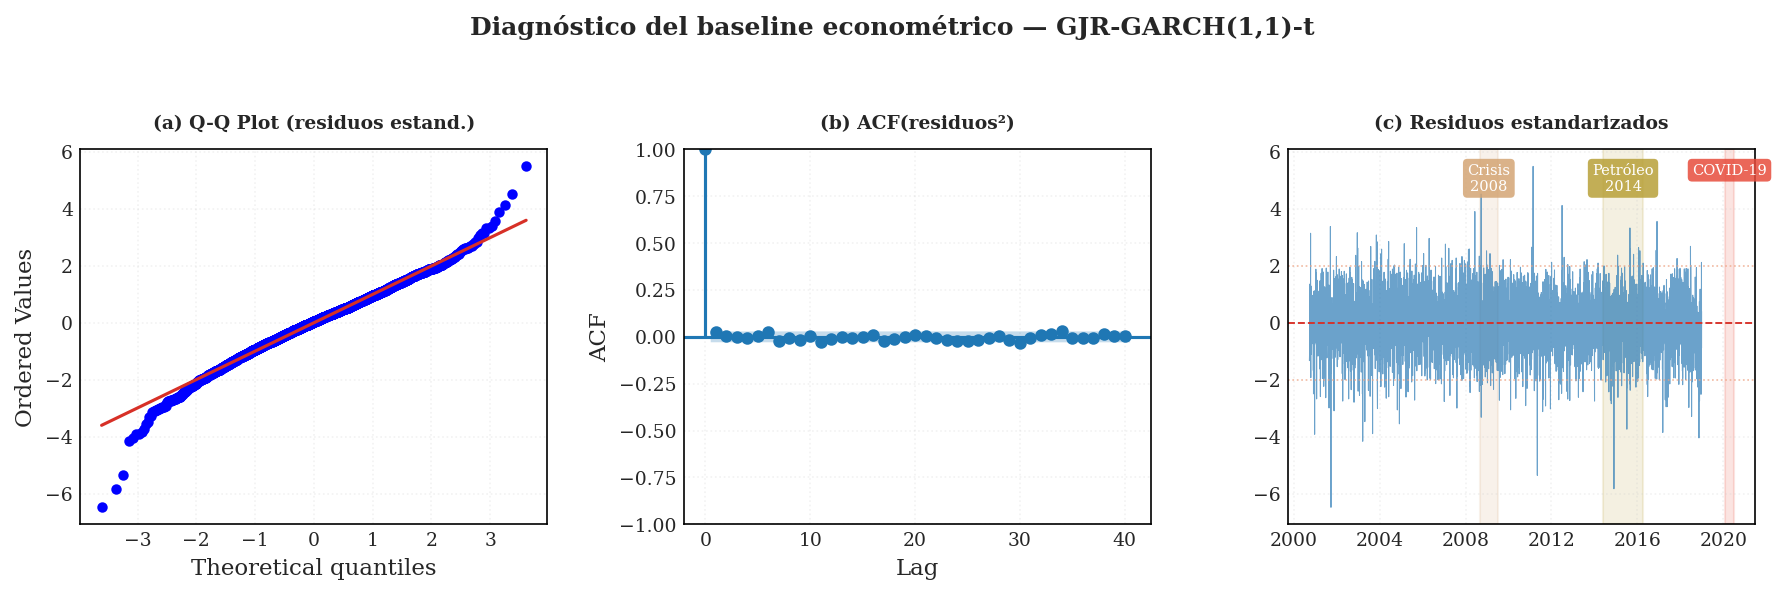

Figura guardada: fig_garch_diagnosticos.png


In [27]:
#  2.3 Gráficas diagnóstico
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
fig.suptitle(f'Diagnóstico del baseline econométrico — {BEST_GARCH_NAME}', fontweight='bold')

from scipy.stats import probplot
probplot(std_resid.values, dist="norm", plot=axes[0])
axes[0].set_title('(a) Q-Q Plot (residuos estand.)', fontweight='bold', fontsize=9)
axes[0].get_lines()[1].set(color=COLOR_EXTREMO, lw=1.5)

plot_acf(std_resid.values**2, lags=40, ax=axes[1], alpha=0.05,
         title='(b) ACF(residuos²)')
axes[1].set_xlabel('Lag')
axes[1].set_ylabel('ACF')
axes[1].set_title('(b) ACF(residuos²)', fontweight='bold', fontsize=9)

axes[2].plot(std_resid.index, std_resid.values, lw=0.5, color=COLOR_VOL, alpha=0.7)
axes[2].axhline(0, color=COLOR_EXTREMO, lw=0.9, ls='--')
axes[2].axhline( 2, color=COLOR_DYN, lw=0.8, ls=':', alpha=0.7)
axes[2].axhline(-2, color=COLOR_DYN, lw=0.8, ls=':', alpha=0.7)
axes[2].set_title('(c) Residuos estandarizados', fontweight='bold', fontsize=9)
add_crisis_zones(axes[2])

plt.tight_layout(rect=[0, 0, 1, 0.93], w_pad=2.0)
save_fig(fig, 'fig_garch_diagnosticos', output_path=FIG_PATH, dpi=300)
plt.show()
plt.close()
print("Figura guardada: fig_garch_diagnosticos.png")


Esta figura resume tres diagnósticos clásicos del modelo **GJR-GARCH(1,1)-t** seleccionado como mejor baseline econométrico. En conjunto, permite evaluar si la dinámica condicional de volatilidad fue razonablemente capturada y qué limitaciones permanecen en los residuos.

Se construye a partir de los **residuos estandarizados** del modelo ajustado sobre la serie histórica de retornos. El panel (a) compara sus cuantiles con los de una distribución de referencia; el panel (b) examina autocorrelación en los residuos al cuadrado; y el panel (c) muestra la trayectoria temporal de los residuos estandarizados con contexto de crisis relevantes.

- **Q-Q Plot**: los extremos se desvían de la línea de referencia, lo que indica que incluso con innovaciones t persisten colas más pesadas de lo ideal. Esto es coherente con la presencia de shocks extremos en el mercado petrolero.  
- **ACF de residuos²**: fuera del lag 0, la autocorrelación remanente es baja. Esto sugiere que el modelo captura una parte importante del clustering de volatilidad, aunque no constituye por sí solo una prueba definitiva de especificación perfecta.  
- **Residuos estandarizados**: se observan episodios extremos, especialmente alrededor de crisis conocidas. Esto indica que el modelo absorbe buena parte de la heterocedasticidad condicional, pero no elimina completamente el impacto de shocks severos.

La figura ayuda a sostener una conclusión central del benchmark: el baseline GARCH puede ser econométricamente razonable y ofrecer buen ordenamiento del riesgo relativo, pero aun así fallar operativamente en clasificación a umbral fijo cuando cambia el régimen o la prevalencia de eventos extremos entre validation y test.


### Diagnóstico interpretativo adicional — GJR-GARCH

Este bloque añade verificaciones explícitas de persistencia práctica y una **Curva de Impacto de Noticias (News Impact Curve, NIC)** para el ajuste GJR-GARCH. Su propósito es mejorar la interpretabilidad econométrica; **no modifica el benchmark, ni el ajuste del modelo, ni la selección de métricas**.


In [28]:
#  2.3b Chequeo estándar de persistencia (tipo GARCH)
gjr_name = next((n for n in garch_results if 'GJR-GARCH' in n), None)
if gjr_name is None:
    print('[SKIP] No hay ajuste GJR-GARCH disponible para el chequeo de persistencia.')
else:
    gjr_res = garch_results[gjr_name]
    params = gjr_res.params
    alpha_key = next((k for k in params.index if str(k).startswith('alpha[')), None)
    beta_key  = next((k for k in params.index if str(k).startswith('beta[')), None)
    gamma_key = next((k for k in params.index if str(k).startswith('gamma[')), None)
    alpha = float(params[alpha_key]) if alpha_key is not None else np.nan
    beta  = float(params[beta_key])  if beta_key  is not None else np.nan
    gamma = float(params[gamma_key]) if gamma_key is not None else 0.0
    alpha_beta = alpha + beta
    print('Chequeo estándar tipo GARCH sobre el ajuste GJR-GARCH')
    print(f'  Fórmula   : alpha + beta < 1')
    print(f'  Valor     : {alpha_beta:.6f}')
    print('  Veredicto : ' + ('cumple' if alpha_beta < 1 else 'no cumple'))


Chequeo estándar tipo GARCH sobre el ajuste GJR-GARCH
  Fórmula   : alpha + beta < 1
  Valor     : 0.964015
  Veredicto : cumple


In [29]:
#  2.3c Chequeo práctico GJR-GARCH(1,1) ─
if gjr_name is not None:
    gjr_persistence = alpha + gamma / 2.0 + beta
    print('Chequeo práctico GJR-GARCH(1,1)')
    print('  Fórmula   : alpha + gamma/2 + beta < 1')
    print(f'  Valor     : {gjr_persistence:.6f}')
    print('  Veredicto : ' + ('cumple' if gjr_persistence < 1 else 'no cumple'))
    print('  Nota      : aproxima la persistencia media bajo asimetría; es un diagnóstico interpretativo.')


Chequeo práctico GJR-GARCH(1,1)
  Fórmula   : alpha + gamma/2 + beta < 1
  Valor     : 0.994803
  Veredicto : cumple
  Nota      : aproxima la persistencia media bajo asimetría; es un diagnóstico interpretativo.


  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB02_Benchmark/Fig_NB02/fig_gjr_news_impact_curve.png  [6.1"×3.4" @ 300dpi]


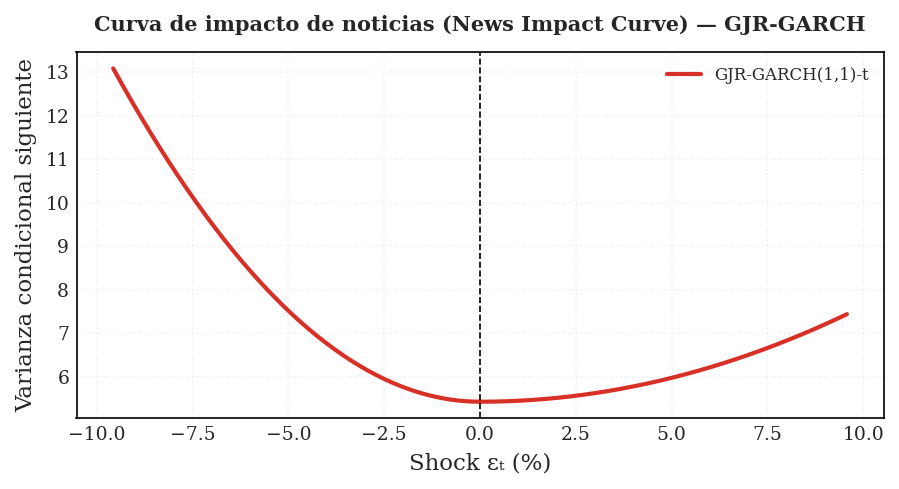

Figura guardada: fig_gjr_news_impact_curve.png


In [30]:
#  2.3d Curva de Impacto de Noticias (News Impact Curve, NIC)
if gjr_name is not None:
    omega = float(params['omega']) if 'omega' in params.index else np.nan
    sigma2_bar = float(np.nanmean((gjr_res.conditional_volatility.dropna().values) ** 2))
    z_grid = np.linspace(-4, 4, 401)
    eps_grid = z_grid * np.sqrt(sigma2_bar)
    sigma2_next = omega + (alpha + gamma * (eps_grid < 0).astype(float)) * (eps_grid ** 2) + beta * sigma2_bar
    fig, ax = plt.subplots(figsize=fig_size('full', aspect=0.55))
    ax.plot(eps_grid, sigma2_next, color=COLOR_EXTREMO, lw=2, label=gjr_name)
    ax.axvline(0, color='black', lw=0.8, ls='--')
    ax.set_title(
    'Curva de impacto de noticias (News Impact Curve) — GJR-GARCH',
    fontweight='bold', fontsize=10)
    ax.set_xlabel('Shock εₜ (%)'); ax.set_ylabel('Varianza condicional siguiente'); ax.legend(fontsize=8,frameon=False); ax.grid(alpha=0.3)
    plt.tight_layout(); save_fig(fig, 'fig_gjr_news_impact_curve', output_path=FIG_PATH, dpi=300); plt.show(); plt.close(); print('Figura guardada: fig_gjr_news_impact_curve.png')

Esta figura presenta la **News Impact Curve (NIC)** del modelo `GJR-GARCH(1,1)-t`, es decir, la relación entre un shock contemporáneo en los retornos y la varianza condicional esperada para el siguiente periodo.

La curva se calcula evaluando la ecuación de varianza condicional del modelo para una rejilla de shocks positivos y negativos, manteniendo fija una varianza de referencia. Esto permite visualizar cómo cambia la respuesta del modelo ante perturbaciones de distinto signo e intensidad.

La curva es asimétrica: los **shocks negativos** incrementan más la varianza futura que los positivos de magnitud comparable. Este patrón es coherente con la especificación GJR-GARCH y sugiere que el modelo captura una respuesta no simétrica de la volatilidad frente a noticias adversas.

La figura aporta interpretación económica al baseline GARCH. No demuestra capacidad predictiva por sí sola, pero sí ayuda a justificar por qué el modelo puede ofrecer un ordenamiento razonable del riesgo aun cuando su desempeño operativo a umbral fijo sea limitado en test.

In [31]:
# En corrida canónica siempre regenerar (garantiza reproducibilidad).
FORCE_REGENERATE_GARCH = (RUN_MODE == 'canonical_cpu')

safe_name  = BEST_GARCH_NAME.replace(' ', '_').replace('(', '').replace(')', '')
CACHE_FILE = f"{OUTPUT_PATH}/garch_rolling_{safe_name}.pkl"
cache_path = Path(CACHE_FILE)

if FORCE_REGENERATE_GARCH and cache_path.exists():
    os.remove(cache_path)
    print(f"Cache eliminado para regeneración: {CACHE_FILE}")
    print("Motivo: fix C-01 — distribución t-Student en rolling forecast")

elif cache_path.exists():
    print(f"Cache existente detectado: {CACHE_FILE}")
    print("→ Se reutilizará para evitar recomputación.")

else:
    print("No existe cache previo.")
    print("→ Se generará rolling forecast desde cero.")

Cache eliminado para regeneración: /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB02_Benchmark/garch_rolling_GJR-GARCH1,1-t.pkl
Motivo: fix C-01 — distribución t-Student en rolling forecast


In [32]:
# Rolling GARCH con ventana expanding:
# para cada fecha t, el modelo se reestima usando solo retornos anteriores a t
# y produce un forecast a 1 paso de la volatilidad condicional (sigma).
#
# 'spec' contiene la estructura del modelo (GARCH/EGARCH, p, q, o, etc.),
# mientras que 'dist_name' define la distribución de errores (por ejemplo, t).
# Se extrae 'dist' de spec con pop() para evitar pasar ese argumento dos veces
# a arch_model(...), lo que generaría conflicto.
#
# Este diseño respeta la causalidad temporal, evita data leakage y hace que
# la predicción sea comparable con un escenario real de forecasting diario.

In [33]:
#  2.4 Rolling expanding window — forecast GARCH ─
def garch_rolling_forecast(full_returns_pct, forecast_index,
                            spec, verbose_every=100):
    """
    Expanding window diario: para cada día t en forecast_index,
    ajustar GARCH con todos los retornos ANTERIORES a t y producir
    la predicción de sigma en t (forecast 1-paso).

    Parámetros
    ----------
    full_returns_pct : pd.Series — retornos × 100, historia completa
    forecast_index   : pd.DatetimeIndex — días a forecastear (val + test)
    spec             : dict — kwargs para arch_model (sin 'dist')
    verbose_every    : int — imprimir progreso cada N iteraciones

    Retorna
    -------
    pd.Series con sigma (no sigma²) indexada por forecast_index
    NOTA: se extrae 'dist' del spec para pasarlo explícitamente a arch_model.
    Esto evita que arch use su default 'normal' ignorando la distribución
    seleccionada por AIC/BIC en Cell 24 (GJR-GARCH(1,1)-t → dist='t').
    """
    sigmas       = {}
    last_result  = None
    n_total      = len(forecast_index)
    n_errors     = 0

    dist_name = spec.pop('dist', 't')

    for i, t in enumerate(forecast_index):
        # Historia estrictamente anterior a t
        history = full_returns_pct[full_returns_pct.index < t]
        if len(history) < 50:
            sigmas[t] = np.nan
            continue

        try:    # dist=dist_name pasa t-Student al modelo
           am = arch_model(history, mean='Constant',rescale=False, dist=dist_name, **spec)
           res = am.fit(disp='off', show_warning=False,
                         options={'maxiter': 400, 'ftol': 1e-8})
           last_result = res
        except Exception:
            n_errors += 1
            if last_result is None:
                sigmas[t] = np.nan
                continue

        fc     = last_result.forecast(horizon=1, reindex=False)
        var_t  = float(fc.variance.values[-1, 0])
        sigmas[t] = np.sqrt(max(var_t, 0))  # sigma = sqrt(varianza)

        if (i + 1) % verbose_every == 0:
            print(f"  [{i+1:4d}/{n_total}] {t.date()} | sigma={sigmas[t]:.4f}%")

    spec['dist'] = dist_name  # restaurar
    print(f"  Completado. Distribución usada: {dist_name}")
    print(f"  Errores de convergencia: {n_errors}/{n_total}")
    return pd.Series(sigmas, name='sigma_garch')


# Ejecución con cache
CACHE_FILE = f"{OUTPUT_PATH}/garch_rolling_{BEST_GARCH_NAME.replace(' ','_').replace('(','').replace(')','')}.pkl"

forecast_idx = df_garch_val.index.union(df_garch_test.index).sort_values()

if Path(CACHE_FILE).exists():
    with open(CACHE_FILE, 'rb') as fh:
        sigma_rolling = pickle.load(fh)
    print(f"Cache cargado: {CACHE_FILE}")
    print(f"  Forecasts: {len(sigma_rolling)} | NaN: {sigma_rolling.isna().sum()}")
else:
    print("No existe cache previo.")
    print("→ Se generará rolling forecast desde cero.")

    spec_copy = garch_specs[BEST_GARCH_NAME].copy()
    full_ret = df[GARCH_FEATURE].where(~df['bad_return']).dropna() * 100
    #Se excluyen los retornos producidos por el clipping del precio negativo.
    print(f"  Historia GARCH: {len(full_ret)} obs (excluidos {df['bad_return'].sum()} bad_return)")

    sigma_rolling = garch_rolling_forecast(
        full_returns_pct = full_ret,
        forecast_index   = forecast_idx,
        spec             = spec_copy,
        verbose_every    = 100
    )
    with open(CACHE_FILE, 'wb') as fh:
        pickle.dump(sigma_rolling, fh)
    print(f"Cache guardado: {CACHE_FILE}")

sigma_val_garch  = sigma_rolling[sigma_rolling.index.isin(df_garch_val.index)].reindex(df_garch_val.index)
sigma_test_garch = sigma_rolling[sigma_rolling.index.isin(df_garch_test.index)].reindex(df_garch_test.index)

SIGMA_PREDS['GARCH_val']  = sigma_val_garch
SIGMA_PREDS['GARCH_test'] = sigma_test_garch

print()
print(f"sigma_val_garch  : {len(sigma_val_garch)} obs  |  NaN: {sigma_val_garch.isna().sum()}")
print(f"sigma_test_garch : {len(sigma_test_garch)} obs  |  NaN: {sigma_test_garch.isna().sum()}")

No existe cache previo.
→ Se generará rolling forecast desde cero.
  Historia GARCH: 6383 obs (excluidos 2 bad_return)
  [ 100/1776] 2019-05-24 | sigma=2.1650%
  [ 200/1776] 2019-10-16 | sigma=2.4124%
  [ 300/1776] 2020-03-11 | sigma=8.5871%
  [ 400/1776] 2020-09-03 | sigma=1.7234%
  [ 500/1776] 2021-01-29 | sigma=1.5272%
  [ 600/1776] 2021-06-23 | sigma=1.5116%
  [ 700/1776] 2021-11-12 | sigma=2.0982%
  [ 800/1776] 2022-04-07 | sigma=4.5603%
  [ 900/1776] 2022-08-31 | sigma=3.0815%
  [1000/1776] 2023-01-25 | sigma=2.0287%
  [1100/1776] 2023-06-20 | sigma=2.4665%
  [1200/1776] 2023-11-09 | sigma=2.7837%
  [1300/1776] 2024-04-05 | sigma=1.4204%
  [1400/1776] 2024-08-28 | sigma=2.3271%
  [1500/1776] 2025-01-22 | sigma=1.8904%
  [1600/1776] 2025-06-16 | sigma=2.2358%
  [1700/1776] 2025-11-05 | sigma=1.7054%
  Completado. Distribución usada: t
  Errores de convergencia: 0/1776
Cache guardado: /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB02_Benchmark/garch_rolling_GJR-GARCH1,

In [34]:
# 2.5 GARCH -> clasificacion binaria
SIGMA_UMBRAL_PCT = (UMBRAL_CLASIFICACION / np.sqrt(VENTANA_VOL)) * 100
GARCH_MODEL_NAME = f"GARCH-{BEST_GARCH_NAME.split('(')[0].strip()}"

print(f"Umbral vol21 (unidades vol21) : {UMBRAL_CLASIFICACION:.6f}")
print(f"Umbral sigma diaria (% diario): {SIGMA_UMBRAL_PCT:.4f}%")
print()

for split_name, sigma_s, df_split in [('val', sigma_val_garch, df_garch_val), ('test', sigma_test_garch, df_garch_test)]:
    sigma_raw = sigma_s.reindex(df_split.index)
    n_missing = int(sigma_raw.isna().sum())
    print(f"  Dias con sigma GARCH faltante (ffill aplicado): {n_missing}")
    sigma_aligned = sigma_raw.ffill()
    y_score_g = sigma_aligned.values
    y_true_g = df_split['y_tp1'].values.astype(int)

    if split_name == 'val':
        best_thr_g, best_f1_g = SIGMA_UMBRAL_PCT, 0.0
        for thr_pct in np.arange(sigma_aligned.quantile(0.80), sigma_aligned.quantile(0.99), 0.01):
            y_p = (y_score_g > thr_pct).astype(int)
            f1 = f1_score(y_true_g, y_p, zero_division=0)
            if f1 > best_f1_g:
                best_f1_g, best_thr_g = f1, thr_pct
        print(f"  Umbral optimo (val): {best_thr_g:.4f}%  F1={best_f1_g:.4f}")
        GARCH_OPT_THRESHOLD = best_thr_g

    y_pred_g_opt = (y_score_g > GARCH_OPT_THRESHOLD).astype(int)
    m = evaluar_baseline(GARCH_MODEL_NAME, y_true_g, y_pred_g_opt, y_score=y_score_g, split=split_name)
    print(f"  [{split_name}] F1={m['f1']:.4f} | AUC={m['auc']:.4f} | AUC-PR={m['auc_pr']:.4f} | P={m['precision']:.4f} | R={m['recall']:.4f}")
    RESULTS_REGISTRY.append(m)
    register_model_output(
        MODEL_OUTPUTS, GARCH_MODEL_NAME, split_name,
        decision_date=df_split['decision_date'],
        target_date=df_split['target_date'],
        y_true=y_true_g,
        y_score=y_score_g,
        threshold=GARCH_OPT_THRESHOLD,
        rule='>',
    )
    Y_SCORES[f"GARCH_{split_name}"] = (y_true_g, y_score_g)
    SIGMA_PREDS[f"GARCH_{split_name}"] = sigma_aligned

OPTIMAL_THRESHOLDS['GARCH'] = float(GARCH_OPT_THRESHOLD)
OPTIMAL_THRESHOLDS[GARCH_MODEL_NAME] = float(GARCH_OPT_THRESHOLD)

Umbral vol21 (unidades vol21) : 0.042996
Umbral sigma diaria (% diario): 0.9382%

  Dias con sigma GARCH faltante (ffill aplicado): 0
  Umbral optimo (val): 7.1193%  F1=0.9730
  [val] F1=0.9730 | AUC=0.9887 | AUC-PR=0.9680 | P=1.0000 | R=0.9474
  Dias con sigma GARCH faltante (ffill aplicado): 0
  [test] F1=0.0000 | AUC=0.9875 | AUC-PR=0.7297 | P=0.0000 | R=0.0000


### Nota metodológica: Imputación ffill en sigma GARCH

En los días donde el modelo GARCH no converge (errores numéricos durante
el ajuste del expanding window), la sigma predicha se imputa con el último
valor válido (`ffill`). Esto **no introduce data leakage**: el valor propagado
es siempre de un día anterior a t — información que un gestor de riesgo real
tendría disponible.

El número exacto de días imputados se imprime en la celda siguiente (`n_missing`).
Esta práctica es estándar en backtesting de VaR intradiario
(Christoffersen, 1998; Engle & Manganelli, 2004).

  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB02_Benchmark/Fig_NB02/fig_garch_roc_pr.png  [6.1"×3.1" @ 300dpi]


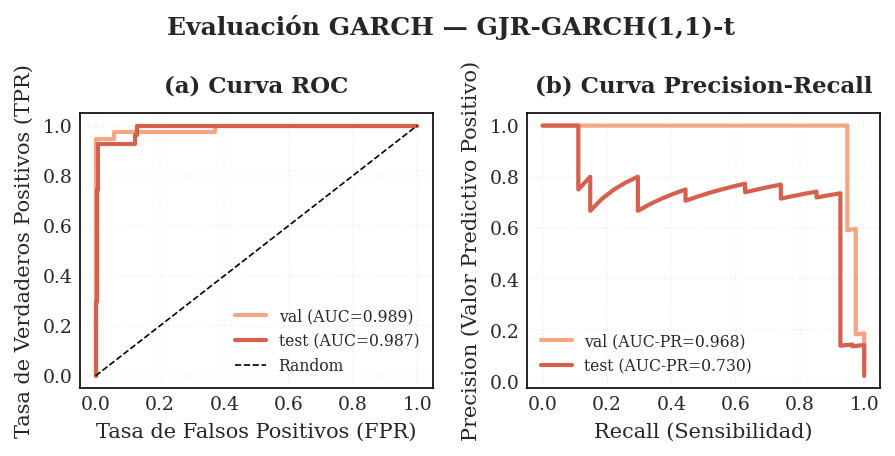

 Evaluación continua (sigma vs vol21) 
  [val] MAE=0.00445  RMSE=0.00620  (vs vol21_clean)
  [test] MAE=0.00225  RMSE=0.00295  (vs vol21_clean)


In [35]:
#  2.6 Evaluación GARCH — curvas ROC y Precision-Recall
fig, axes = plt.subplots(1, 2, figsize=fig_size("2x1"))
fig.suptitle(f'Evaluación GARCH — {BEST_GARCH_NAME}', fontweight='bold')

colors = {'val': SPLIT_COLORS['validation'], 'test': SPLIT_COLORS['test']}
for split_name, ax_roc, ax_pr in []:  # placeholder — se llena en el loop abajo
    pass

for split_name, (y_true_g, y_score_g) in [
        ('val',  Y_SCORES.get('GARCH_val',  (yw_val_uni.astype(int),  sigma_val_garch.reindex(idx_val_uni).fillna(0).values))),
        ('test', Y_SCORES.get('GARCH_test', (yw_test_uni.astype(int), sigma_test_garch.reindex(idx_test_uni).fillna(0).values)))]:

    mask_valid = ~np.isnan(y_score_g)
    yt, ys = y_true_g[mask_valid], y_score_g[mask_valid]
    if yt.sum() == 0:
        continue

    col = colors[split_name]
    fpr, tpr, _ = roc_curve(yt, ys)
    prec, rec, _ = precision_recall_curve(yt, ys)
    auc_val = roc_auc_score(yt, ys)
    ap_val  = average_precision_score(yt, ys)

    axes[0].plot(fpr, tpr, lw=2, color=col, label=f'{split_name} (AUC={auc_val:.3f})')
    axes[1].plot(rec, prec, lw=2, color=col, label=f'{split_name} (AUC-PR={ap_val:.3f})')

axes[0].plot([0,1],[0,1], 'k--', lw=0.8, label='Random')
axes[0].set_xlabel('Tasa de Falsos Positivos (FPR)', fontsize=10)
axes[0].set_ylabel('Tasa de Verdaderos Positivos (TPR)', fontsize=10)
axes[0].set_title('(a) Curva ROC', fontweight='bold'); axes[0].legend(fontsize=7.5, framealpha=0.9,frameon=False)

axes[1].set_xlabel('Recall (Sensibilidad)', fontsize=10)
axes[1].set_ylabel('Precision (Valor Predictivo Positivo)', fontsize=10)
axes[1].set_title('(b) Curva Precision-Recall', fontweight='bold'); axes[1].legend(fontsize=7.5, framealpha=0.9,frameon=False)

plt.tight_layout()
save_fig(fig, 'fig_garch_roc_pr', output_path=FIG_PATH, dpi=300)
plt.show()
plt.close()

print(" Evaluación continua (sigma vs vol21) ")
for split_name, sigma_s, df_split, idx_win in [
        ('val',  sigma_val_garch,  df_val,  idx_val_uni),
        ('test', sigma_test_garch, df_test, idx_test_uni)]:
    sigma_a = sigma_s.reindex(idx_win) / 100  # desescalar a proporción
    vol21_a = df_split['vol21_clean'].reindex(idx_win)
    mask    = sigma_a.notna() & vol21_a.notna()
    if mask.sum() == 0:
        continue
    mae  = np.mean(np.abs(sigma_a[mask].values - vol21_a[mask].values))
    rmse = np.sqrt(np.mean((sigma_a[mask].values - vol21_a[mask].values)**2))
    print(f"  [{split_name}] MAE={mae:.5f}  RMSE={rmse:.5f}  "
          f"(vs vol21_clean)")

### Interpretación del baseline GARCH

El modelo GJR-GARCH(1,1)-t muestra una **alta capacidad de ranking**, con una degradación mínima en AUC-ROC entre validation y test. Sin embargo, la caída más pronunciada en AUC-PR indica que el desempeño operativo es más sensible a cambios en la prevalencia de eventos extremos.

Este comportamiento sugiere que, aunque el modelo ordena correctamente el riesgo relativo, su desempeño como clasificador binario depende críticamente del umbral de decisión. En particular, el umbral calibrado en validation —periodo con alta volatilidad— no se transfiere adecuadamente a test, donde la frecuencia de eventos extremos es menor.

Desde el punto de vista metodológico, esto no implica que el modelo GARCH sea inadecuado, sino que su uso como clasificador a umbral fijo presenta limitaciones en presencia de cambios de régimen.

En este contexto, el baseline GARCH se mantiene como **referencia econométrica**, mientras que las arquitecturas LSTM se exploran como alternativas capaces de aprender directamente la frontera de decisión en entornos no estacionarios.

GARCH — sensibilidad post-hoc del threshold en test
  Umbral calibrado en validation: 7.1193%
  Mejor threshold post-hoc en test: 4.1565%  |  F1=0.8197
  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB02_Benchmark/Fig_NB02/fig_garch_posthoc_sensitivity.png  [6.1"×3.8" @ 300dpi]


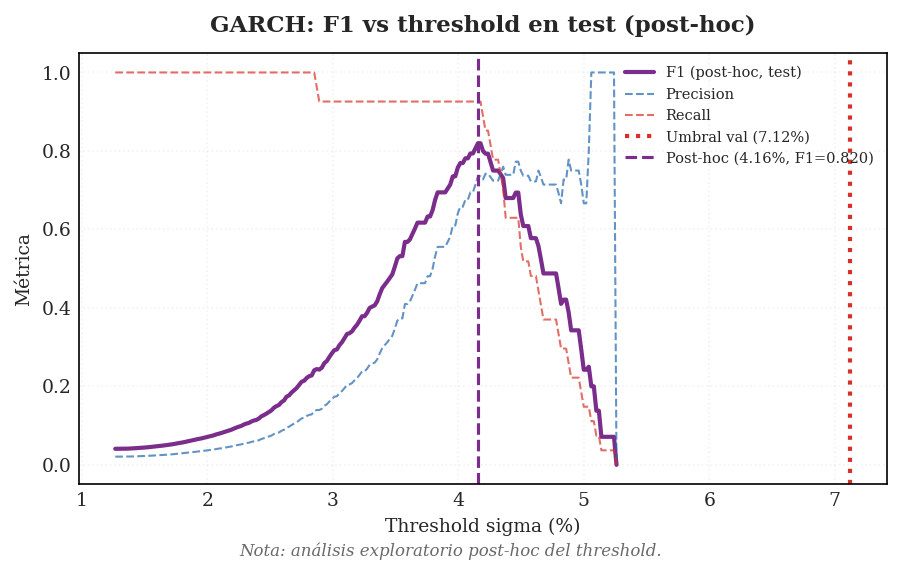

In [36]:
# 2.7 Post-hoc: sensibilidad de GARCH al threshold en test
# Nota: análisis exploratorio post-hoc. Usa información de test y NO se emplea
# para selección de modelo. Su propósito es mostrar la sensibilidad del desempeño
# operativo al threshold una vez fijado el score del modelo.

if 'GARCH_test' in Y_SCORES:
    y_true_test_g, y_score_test_g = Y_SCORES['GARCH_test']

    sigma_min_test = np.nanmin(y_score_test_g)
    sigma_max_test = np.nanmax(y_score_test_g)

    thresholds_posthoc = np.linspace(
        max(sigma_min_test, 0.1), sigma_max_test, 200
    )

    rows_posthoc = []
    for thr in thresholds_posthoc:
        yp = (y_score_test_g > thr).astype(int)
        rows_posthoc.append({
            'threshold_pct': thr,
            'f1': f1_score(y_true_test_g, yp, zero_division=0),
            'precision': precision_score(y_true_test_g, yp, zero_division=0),
            'recall': recall_score(y_true_test_g, yp, zero_division=0),
        })

    df_posthoc = pd.DataFrame(rows_posthoc)
    best_ph_idx = df_posthoc['f1'].idxmax()
    best_ph_thr = float(df_posthoc.loc[best_ph_idx, 'threshold_pct'])
    best_ph_f1  = float(df_posthoc.loc[best_ph_idx, 'f1'])

    # Prints mínimos
    print("GARCH — sensibilidad post-hoc del threshold en test")
    print(f"  Umbral calibrado en validation: {GARCH_OPT_THRESHOLD:.4f}%")
    print(f"  Mejor threshold post-hoc en test: {best_ph_thr:.4f}%  |  F1={best_ph_f1:.4f}")

    fig, ax = plt.subplots(figsize=fig_size("full"))

    ax.plot(
        df_posthoc['threshold_pct'], df_posthoc['f1'],
        color=COLORES_MODELOS.get('GARCH', COLORS_P[99]),
        lw=2, label='F1 (post-hoc, test)'
    )
    ax.plot(
        df_posthoc['threshold_pct'], df_posthoc['precision'],
        color=COLOR_NORMAL, ls='--', lw=1, alpha=0.7, label='Precision'
    )
    ax.plot(
        df_posthoc['threshold_pct'], df_posthoc['recall'],
        color=COLOR_EXTREMO, ls='--', lw=1, alpha=0.7, label='Recall'
    )

    ax.axvline(
        GARCH_OPT_THRESHOLD, color=COLORS_P[95], ls=':', lw=2,
        label=f'Umbral val ({GARCH_OPT_THRESHOLD:.2f}%)'
    )
    ax.axvline(
        best_ph_thr, color=COLORS_P[99], ls='--', lw=1.5,
        label=f'Post-hoc ({best_ph_thr:.2f}%, F1={best_ph_f1:.3f})'
    )

    ax.set_xlabel('Threshold sigma (%)', fontsize=9)
    ax.set_ylabel('Métrica', fontsize=9)
    ax.set_title('GARCH: F1 vs threshold en test (post-hoc)', fontweight='bold')
    ax.legend(loc="upper right", fontsize=7, frameon=False, handlelength=2)
    ax.set_ylim(-0.05, 1.05)

    fig.text(
        0.5, 0.005,
        "Nota: análisis exploratorio post-hoc del threshold.",
        ha="center", fontsize=8, style="italic", color="dimgray"
    )

    plt.tight_layout()
    save_fig(fig, 'fig_garch_posthoc_sensitivity', output_path=FIG_PATH, dpi=300)
    plt.show()
    plt.close()

else:
    print("GARCH_test no encontrado en Y_SCORES — omitiendo análisis post-hoc")

Esta figura muestra cómo cambia el F1 del baseline `GJR-GARCH(1,1)-t` al variar el threshold de decisión en test, junto con la evolución de precision y recall.

El mejor F1 en test aparece con un threshold distinto al calibrado en validation. Esto sugiere que el pobre desempeño operativo observado a umbral fijo no se debe únicamente a una falta de señal en el score, sino también a una transferencia imperfecta del threshold entre regímenes con distinta prevalencia de eventos extremos.

Parte del problema de GARCH en test está asociado a calibración del threshold más que a una ausencia total de capacidad discriminativa.

## Transición desde GARCH hacia modelos LSTM

El análisis del baseline `GJR-GARCH(1,1)-t` deja una conclusión clara: el modelo conserva valor como **referencia econométrica** y produce un score continuo útil para ordenar el riesgo relativo, pero su traducción a clasificación binaria a umbral fijo resulta frágil cuando cambia el régimen fuera de muestra.

Este resultado no invalida el uso de GARCH; más bien delimita su papel dentro del benchmark. En particular, su desempeño sugiere que una parte central del problema no está únicamente en estimar la volatilidad condicional, sino en **aprender una frontera de decisión que generalice mejor entre regímenes con distinta prevalencia de eventos extremos**.

Bajo esa motivación, las siguientes secciones evalúan arquitecturas **LSTM** como alternativas secuenciales capaces de capturar relaciones no lineales y aprender la clasificación de eventos extremos de forma más flexible a partir de ventanas temporales de observaciones.

---
## PARTE III — LSTM Univariado (Deep Learning Puro)

Arquitecturas evaluadas:
1. **Simple**: 1 capa LSTM(64) + Dropout(0.2) + Dense(1, sigmoid)
2. **Bidireccional**: 2 capas BiDir-LSTM(64→32) + Dropout + Dense(1, sigmoid)

Feature: solo `vol21_clean` (L=21 pasos). Permite comparación directa contra GARCH
(misma información univariada) y sirve de línea base para la versión multivariada.

**Estrategia anti-desbalanceo**: `class_weight` en Keras (no SMOTE).
**Umbral de decisión**: grid search en validación (0.05→0.90), aplicado en test sin re-optimizar.


In [37]:
#  3.1 Función build_model
def build_model(input_shape, architecture='simple',
                lstm_units=64, lstm_units_2=None,   # IC-3: configurable para Bayesian Search BiDir
                dropout=0.2, seed=42):
    """
    Construye modelo LSTM para clasificación binaria de volatilidad extrema.

    Parámetros
    ----------
    input_shape  : tuple (lookback, n_features)
    architecture : 'simple' | 'bidirectional'
    lstm_units   : unidades en primera capa LSTM
    lstm_units_2 : unidades en segunda capa BiDir (IC-3); None → lstm_units//2 (default)
    dropout      : tasa de Dropout
    seed         : semilla para inicializadores

    Arquitecturas
    -------------
    simple        : LSTM(64) → Dropout → Dense(1, sigmoid)
    bidirectional : BiDir(LSTM(64), ret_seq=True) → Dropout
                    → BiDir(LSTM(32)) → Dropout → Dense(1, sigmoid)
    """
    # IC-3: lstm_units_2 configurable; default mantiene lstm_units//2 (backward-compatible)
    lstm_units_2 = lstm_units_2 if lstm_units_2 is not None else (lstm_units // 2)
    tf.random.set_seed(seed)
    inp = keras.Input(shape=input_shape, name='input_seq')

    if architecture == 'simple':
        x = keras.layers.LSTM(lstm_units, name='lstm_1')(inp)
        x = keras.layers.Dropout(dropout, seed=seed, name='drop_1')(x)

    elif architecture == 'bidirectional':
        x = keras.layers.Bidirectional(
            keras.layers.LSTM(lstm_units, return_sequences=True, name='lstm_1'),
            name='bidir_1')(inp)
        x = keras.layers.Dropout(dropout, seed=seed, name='drop_1')(x)
        x = keras.layers.Bidirectional(
            keras.layers.LSTM(lstm_units_2, return_sequences=False, name='lstm_2'),  # IC-3
            name='bidir_2')(x)
        x = keras.layers.Dropout(dropout, seed=seed, name='drop_2')(x)

    else:
        raise ValueError(f"architecture debe ser 'simple' o 'bidirectional', no '{architecture}'")

    out = keras.layers.Dense(1, activation='sigmoid', name='output')(x)
    model = keras.Model(inputs=inp, outputs=out,
                        name=f'lstm_{architecture}_{lstm_units}u')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='binary_crossentropy',
        metrics=[
            keras.metrics.AUC(name='auc'),
            keras.metrics.AUC(name='pr_auc', curve='PR'),  # metrica diagnostica PR-AUC (experimental — no altera benchmark canonico)
            keras.metrics.Precision(name='precision'),
            keras.metrics.Recall(name='recall'),
        ]
    )
    return model

print("build_model() definida")
print(f"  Arquitecturas: 'simple', 'bidirectional'")
print(f"  Input esperado: (batch, lookback={LOOKBACK}, n_features)")


build_model() definida
  Arquitecturas: 'simple', 'bidirectional'
  Input esperado: (batch, lookback=21, n_features)


In [38]:
#  3.2 Función optimize_threshold (two-phase) ─
def optimize_threshold(model, X_val_w, y_val_w,
                       metric='f1',
                       thresholds=None,
                       verbose=True):
    """
    Búsqueda en dos fases sobre umbral de decisión, EXCLUSIVAMENTE en validación.
    Fase 1: barrido grueso (step=0.05) para localizar la región óptima.
    Fase 2: barrido fino (step=0.01) alrededor del mejor umbral de fase 1.

    El umbral seleccionado se aplica al conjunto de test sin re-optimizar.

    Parámetros
    ----------
    model      : modelo Keras entrenado
    X_val_w    : np.ndarray (N_val, L, F) — secuencias de validación
    y_val_w    : np.ndarray (N_val,) — labels de validación
    metric     : criterio de selección ('f1' por defecto)
    thresholds : lista de umbrales (si se provee, se salta la búsqueda en dos fases)

    Retorna
    -------
    best_thr : float
    df_thr   : pd.DataFrame con resultados del grid completo
    """
    y_score = model.predict(X_val_w, verbose=0).ravel()

    def _eval_thresholds(thr_list):
        rows = []
        for thr in thr_list:
            y_p   = (y_score >= thr).astype(int)
            f1_v  = f1_score(y_val_w.astype(int), y_p, zero_division=0)
            prec  = precision_score(y_val_w.astype(int), y_p, zero_division=0)
            rec   = recall_score(y_val_w.astype(int), y_p, zero_division=0)
            rows.append({'threshold': round(thr, 4), 'f1': f1_v,
                         'precision': prec, 'recall': rec})
        return pd.DataFrame(rows)

    if thresholds is not None:
        df_thr = _eval_thresholds(thresholds)
    else:
        # Fase 1: barrido grueso (0.05 a 0.95, step 0.05)
        coarse_grid = np.arange(0.05, 0.96, 0.05)
        df_coarse   = _eval_thresholds(coarse_grid)
        best_coarse = float(df_coarse.loc[df_coarse['f1'].idxmax(), 'threshold'])

        # Fase 2: barrido fino alrededor del mejor (+/- 0.05, step 0.01)
        fine_lo   = max(0.01, best_coarse - 0.05)
        fine_hi   = min(0.99, best_coarse + 0.06)
        fine_grid = np.arange(fine_lo, fine_hi, 0.01)
        df_fine   = _eval_thresholds(fine_grid)

        df_thr = (pd.concat([df_coarse, df_fine], ignore_index=True)
                  .drop_duplicates(subset='threshold')
                  .sort_values('threshold')
                  .reset_index(drop=True))

    best_idx = df_thr['f1'].idxmax()
    best_thr = float(df_thr.loc[best_idx, 'threshold'])

    if verbose:
        print(f"Umbral óptimo (val, criterio={metric}): {best_thr:.4f}")
        print(f"  F1={df_thr.loc[best_idx,'f1']:.4f}  "
              f"P={df_thr.loc[best_idx,'precision']:.4f}  "
              f"R={df_thr.loc[best_idx,'recall']:.4f}")
        if thresholds is None:
            print(f"  (Two-phase: grueso {len(coarse_grid)} + "
                  f"fino {len(fine_grid)} = {len(df_thr)} umbrales evaluados)")
    return best_thr, df_thr

print("optimize_threshold() definida (two-phase)")

optimize_threshold() definida (two-phase)


In [39]:
# 3.3 Callbacks comunes
# Benchmark canonico: monitor unico = val_loss.
# val_pr_auc queda solo para diagnostico o experimentos separados.
EARLYSTOP_MONITOR_MULTI = 'val_loss'

def make_callbacks(model_name, output_path=OUTPUT_PATH, patience=15, monitor='val_loss'):
    monitor_mode = 'min' if 'loss' in monitor else 'max'
    ckpt_dir = globals().get('MODEL_DIR', os.path.join(output_path, 'modelos_nb02'))
    os.makedirs(ckpt_dir, exist_ok=True)
    ckpt_path = os.path.join(ckpt_dir, f"{model_name}_best.keras")
    return [
        keras.callbacks.EarlyStopping(
            monitor=monitor, mode=monitor_mode, patience=patience,
            restore_best_weights=True, min_delta=1e-4, verbose=1
        ),
        keras.callbacks.ModelCheckpoint(
            ckpt_path, monitor=monitor, mode=monitor_mode,
            save_best_only=True, verbose=0
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=7,
            min_lr=1e-6, verbose=1
        ),
    ]

print("make_callbacks() definida")
print(f"  EarlyStopping monitor: {EARLYSTOP_MONITOR_MULTI}")
print("  val_pr_auc se conserva solo para diagnostico/Optuna experimental")

make_callbacks() definida
  EarlyStopping monitor: val_loss
  val_pr_auc se conserva solo para diagnostico/Optuna experimental


### Nota metodologica: criterio de EarlyStopping

El benchmark canonico usa `EarlyStopping(monitor='val_loss')` tanto en CPU como en cualquier corrida GPU que quiera mantenerse comparable.

`val_pr_auc` se conserva como metrica diagnostica y como objetivo experimental de Optuna, pero no redefine el benchmark oficial H0-H3.

Esta separacion evita mezclar el protocolo canonico de entrenamiento con ablaciones o exploraciones de hiperparametros.

In [40]:
#  3.4 Entrenar LSTM simple univariado ─
tf.random.set_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

model_uni_simple = build_model(
    input_shape=(LOOKBACK, len(FEATURES_UNI)),
    architecture='simple', lstm_units=64, dropout=0.2, seed=RANDOM_SEED)
model_uni_simple.summary()

history_uni_simple = model_uni_simple.fit(
    Xw_train_uni, yw_train_uni.astype(np.float32),
    validation_data=(Xw_val_uni, yw_val_uni.astype(np.float32)),
    epochs=200, batch_size=32,
    class_weight=CLASS_WEIGHTS,
    callbacks=make_callbacks('lstm_uni_simple'),
    shuffle=False,   # CRÍTICO: datos temporales
    verbose=1
)
print(f"Entrenamiento finalizado — epochs ejecutados: {len(history_uni_simple.history['loss'])}")


Model: "lstm_simple_64u"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_seq (InputLayer)          │ (None, 21, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_1 (Dropout)                │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,961 (66.25 KB)

 Trainable params: 16,961 (66.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
143/143 ━━━━━━━━━━━━━━━━━━━━ 7s 29ms/step - auc: 0.8443 - loss: 0.5266 - pr_auc: 0.2953 - precision: 0.2905 - recall: 0.7870 - val_auc: 0.9380 - val_loss: 0.4048 - val_pr_auc: 0.8502 - val_precision: 0.2000 - val_recall: 0.8966 - learning_rate: 0.0010
Epoch 2/200
143/143 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - auc: 0.9636 - loss: 0.2560 - pr_auc: 0.6555 - precision: 0.3297 - recall: 0.9217 - val_auc: 0.9730 - val_loss: 0.2899 - val_pr_auc: 0.9200 - val_precision: 0.3803 - val_recall: 0.9310 - learning_rate: 0.0010
Epoch 3/200
143/143 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - auc: 0.9776 - loss: 0.1938 - pr_auc: 0.6928 - precision: 0.4263 - recall: 0.9304 - val_auc: 0.9799 - val_loss: 0.2222 - val_pr_auc: 0.9340 - val_precision: 0.5510 - val_recall: 0.9310 - learning_rate: 0.0010
Epoch 4/200
143/143 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - auc: 0.9874 - loss: 0.1480 - pr_auc: 0.8280 - precision: 0.5536 - recall: 0.9435 - val_auc: 0.9884 - val_loss: 0.2225 - val_pr_auc: 0.9546 - val_precisi

In [41]:
#  3.5 Entrenar BiDir LSTM univariado ─
tf.random.set_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

model_uni_bidir = build_model(
    input_shape=(LOOKBACK, len(FEATURES_UNI)),
    architecture='bidirectional', lstm_units=64, dropout=0.2, seed=RANDOM_SEED)

history_uni_bidir = model_uni_bidir.fit(
    Xw_train_uni, yw_train_uni.astype(np.float32),
    validation_data=(Xw_val_uni, yw_val_uni.astype(np.float32)),
    epochs=200, batch_size=32,
    class_weight=CLASS_WEIGHTS,
    callbacks=make_callbacks('lstm_uni_bidir'),
    shuffle=False,
    verbose=1
)
print(f"Entrenamiento finalizado — epochs ejecutados: {len(history_uni_bidir.history['loss'])}")


Epoch 1/200
143/143 ━━━━━━━━━━━━━━━━━━━━ 15s 54ms/step - auc: 0.8635 - loss: 0.4809 - pr_auc: 0.2807 - precision: 0.3025 - recall: 0.7826 - val_auc: 0.9707 - val_loss: 0.3535 - val_pr_auc: 0.9043 - val_precision: 0.2368 - val_recall: 0.9310 - learning_rate: 0.0010
Epoch 2/200
143/143 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - auc: 0.9679 - loss: 0.1862 - pr_auc: 0.5115 - precision: 0.3363 - recall: 0.9826 - val_auc: 0.9849 - val_loss: 0.1277 - val_pr_auc: 0.9520 - val_precision: 0.5094 - val_recall: 0.9310 - learning_rate: 0.0010
Epoch 3/200
143/143 ━━━━━━━━━━━━━━━━━━━━ 12s 53ms/step - auc: 0.9805 - loss: 0.1519 - pr_auc: 0.7437 - precision: 0.4098 - recall: 0.9783 - val_auc: 0.9803 - val_loss: 0.0824 - val_pr_auc: 0.9658 - val_precision: 0.5833 - val_recall: 0.9655 - learning_rate: 0.0010
Epoch 4/200
143/143 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - auc: 0.9876 - loss: 0.1089 - pr_auc: 0.7714 - precision: 0.5000 - recall: 0.9870 - val_auc: 0.9811 - val_loss: 0.0856 - val_pr_auc: 0.9704 - val_preci

  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB02_Benchmark/Fig_NB02/fig_lstm_learning_curves_lstm_univariado_curvas_de_aprendizaje.png  [6.1"×3.8" @ 300dpi]


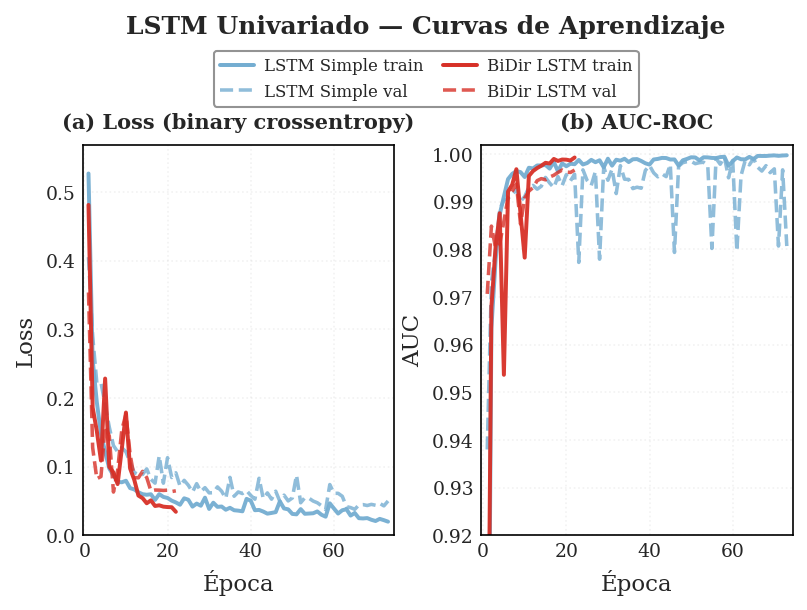

[OK] Figura guardada: fig_lstm_learning_curves_lstm_univariado_curvas_de_aprendizaje.png


In [42]:
import re
import unicodedata

def plot_learning_curves(histories_dict, title="Curvas de Aprendizaje",
                         output_path=FIG_PATH):
    """Visualiza curvas de loss y AUC con estilo consistente de tesis."""

    def _slug(text):
        text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode("ascii")
        text = re.sub(r"[^a-zA-Z0-9]+", "_", text.lower()).strip("_")
        return text[:50]

    fig, axes = plt.subplots(1, 2, figsize=fig_size("full"))

    color_map = {
        'LSTM Simple':        COLORES_MODELOS.get('LSTM-Simple-Uni', COLOR_VOL),
        'BiDir LSTM':         COLORES_MODELOS.get('BiDir-LSTM-Uni', COLOR_EXTREMO),
        'LSTM Simple Multi':  COLORES_MODELOS.get('LSTM-Simple-Multi', COLOR_VOL),
        'BiDir LSTM Multi':   COLORES_MODELOS.get('BiDir-LSTM-Multi', COLOR_DYN),
    }
    fallback_colors = [COLOR_VOL, COLOR_EXTREMO, COLOR_DYN, COLOR_VAR]

    loss_max = 0.0
    auc_min, auc_max = 1.0, 0.0
    legend_handles = []

    for i, (name, h) in enumerate(histories_dict.items()):
        col = color_map.get(name, fallback_colors[i % len(fallback_colors)])
        hist = h.history
        ep = np.arange(1, len(hist['loss']) + 1)

        # Loss
        axes[0].plot(
            ep, hist['loss'],
            lw=1.9, color=col, alpha=0.95
        )
        if 'val_loss' in hist:
            axes[0].plot(
                ep, hist['val_loss'],
                lw=1.7, color=col, ls='--', alpha=0.80
            )
            loss_max = max(loss_max, np.nanmax(hist['val_loss']))
        loss_max = max(loss_max, np.nanmax(hist['loss']))

        # AUC
        if 'auc' in hist and 'val_auc' in hist:
            axes[1].plot(
                ep, hist['auc'],
                lw=1.9, color=col, alpha=0.95
            )
            axes[1].plot(
                ep, hist['val_auc'],
                lw=1.7, color=col, ls='--', alpha=0.80
            )
            auc_min = min(auc_min, np.nanmin(hist['auc']), np.nanmin(hist['val_auc']))
            auc_max = max(auc_max, np.nanmax(hist['auc']), np.nanmax(hist['val_auc']))

        legend_handles.extend([
            Line2D([0], [0], color=col, lw=1.9, ls='-',  label=f'{name} train'),
            Line2D([0], [0], color=col, lw=1.7, ls='--', alpha=0.80, label=f'{name} val')
        ])

    # Panel (a): Loss
    axes[0].set_title('(a) Loss (binary crossentropy)', fontweight='bold', fontsize=10, pad=8)
    axes[0].set_xlabel('Época')
    axes[0].set_ylabel('Loss')
    axes[0].set_ylim(0, max(0.15, loss_max * 1.08))

    # Panel (b): AUC
    axes[1].set_title('(b) AUC-ROC', fontweight='bold', fontsize=10, pad=8)
    axes[1].set_xlabel('Época')
    axes[1].set_ylabel('AUC')
    if auc_max > auc_min:
        axes[1].set_ylim(max(0.92, auc_min - 0.01), min(1.002, auc_max + 0.003))

    for ax in axes:
        ax.grid(alpha=0.25)
        ax.tick_params(axis='both', labelsize=9)
        ax.margins(x=0.02)

    fig.suptitle(title, fontweight='bold', fontsize=12, y=1.03)

    add_top_legend(
        handles=legend_handles, fig=fig,
        ncol=2, y=0.98, fontsize=8, frameon=True,
    )

    fig.subplots_adjust(top=0.8, wspace=0.28)

    fname = f"fig_lstm_learning_curves_{_slug(title)}"
    save_fig(fig, fname, output_path=output_path)
    plt.show()
    plt.close()
    print(f"[OK] Figura guardada: {fname}.png")


plot_learning_curves(
    {
        'LSTM Simple': history_uni_simple,
        'BiDir LSTM': history_uni_bidir,
    },
    title="LSTM Univariado — Curvas de Aprendizaje"
)

Esta figura compara la evolución de la pérdida y del AUC-ROC en **train** y **validation** para los modelos LSTM univariados.

Ambas arquitecturas convergen rápidamente y mantienen un desempeño alto en validation. Las diferencias entre las curvas de entrenamiento y validación son moderadas, lo que sugiere un ajuste estable y sin señales evidentes de divergencia severa durante el entrenamiento.

La figura ayuda a verificar que el benchmark univariado se apoya en un proceso de entrenamiento razonablemente estable antes de pasar a la evaluación final en test.

Umbral óptimo (val, criterio=f1): 0.9900
  F1=0.9825  P=1.0000  R=0.9655
  (Two-phase: grueso 19 + fino 10 = 27 umbrales evaluados)
  [val] LSTM-Simple-Uni           | F1=0.9825 | AUC=0.9994 | AUC-PR=0.9933 | thr=0.99
  [test] LSTM-Simple-Uni           | F1=0.7826 | AUC=0.9987 | AUC-PR=0.9465 | thr=0.99
Umbral óptimo (val, criterio=f1): 0.8800
  F1=0.9825  P=1.0000  R=0.9655
  (Two-phase: grueso 19 + fino 11 = 27 umbrales evaluados)
  [val] BiDir-LSTM-Uni            | F1=0.9825 | AUC=0.9921 | AUC-PR=0.9736 | thr=0.88
  [test] BiDir-LSTM-Uni            | F1=0.7353 | AUC=0.9963 | AUC-PR=0.9401 | thr=0.88
  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB02_Benchmark/Fig_NB02/fig_lstm_uni_eval.png  [6.1"×3.1" @ 300dpi]


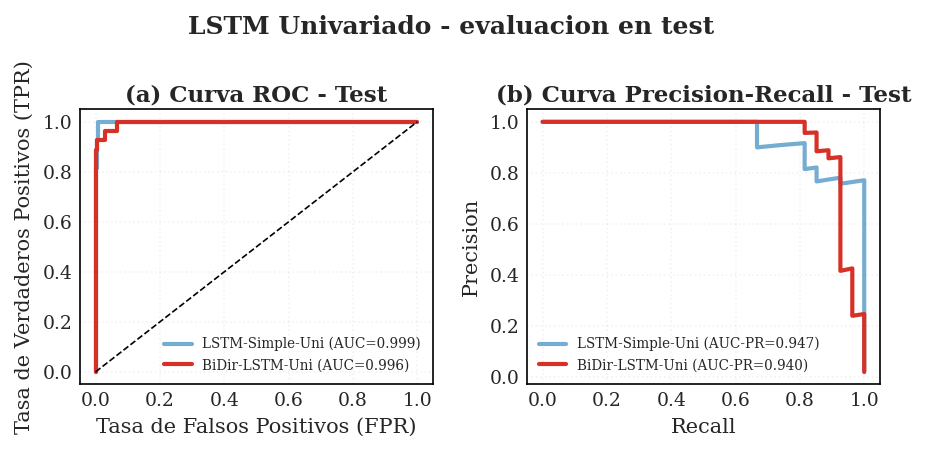

In [43]:
# 3.7 Optimizacion de umbral y evaluacion
results_lstm_uni = {}

for arch_name, model in [('LSTM-Simple-Uni', model_uni_simple),
                         ('BiDir-LSTM-Uni', model_uni_bidir)]:
    best_thr, df_thr = optimize_threshold(
        model, Xw_val_uni, yw_val_uni,
        metric='f1', verbose=True
    )

    y_score_val = model.predict(Xw_val_uni, verbose=0).ravel()
    y_score_test = model.predict(Xw_test_uni, verbose=0).ravel()

    for split_name, y_w, y_score, decision_idx, target_idx in [
        ('val', yw_val_uni, y_score_val, idx_val_uni, target_idx_val_uni),
        ('test', yw_test_uni, y_score_test, idx_test_uni, target_idx_test_uni),
    ]:
        y_p = (y_score >= best_thr).astype(int)
        m = evaluar_baseline(arch_name, y_w.astype(int), y_p, y_score=y_score, split=split_name)
        print(f"  [{split_name}] {arch_name:25s} | F1={m['f1']:.4f} | AUC={m['auc']:.4f} | AUC-PR={m['auc_pr']:.4f} | thr={best_thr:.2f}")
        RESULTS_REGISTRY.append(m)
        register_model_output(
            MODEL_OUTPUTS, arch_name, split_name,
            decision_date=decision_idx,
            target_date=target_idx,
            y_true=y_w.astype(int),
            y_score=y_score,
            threshold=best_thr,
            rule='>=',
        )
        Y_SCORES[f"{arch_name}_{split_name}"] = (y_w.astype(int), y_score)

    OPTIMAL_THRESHOLDS[arch_name] = float(best_thr)
    results_lstm_uni[arch_name] = {'model': model, 'threshold': best_thr, 'thr_df': df_thr}

fig, axes = plt.subplots(1, 2, figsize=fig_size("2x1"))
fig.suptitle('LSTM Univariado - evaluacion en test', fontweight='bold')

for arch_name, data in results_lstm_uni.items():
    m_obj = data['model']
    y_s = m_obj.predict(Xw_test_uni, verbose=0).ravel()
    yt = yw_test_uni.astype(int)
    fpr, tpr, _ = roc_curve(yt, y_s)
    prec, rec, _ = precision_recall_curve(yt, y_s)
    col = COLORES_MODELOS.get(arch_name, COLOR_VAR)
    axes[0].plot(fpr, tpr, lw=2, color=col, label=f"{arch_name} (AUC={roc_auc_score(yt, y_s):.3f})")
    axes[1].plot(rec, prec, lw=2, color=col, label=f"{arch_name} (AUC-PR={average_precision_score(yt, y_s):.3f})")

axes[0].plot([0, 1], [0, 1], 'k--', lw=0.8)
axes[0].set_title('(a) Curva ROC - Test', fontweight='bold', pad=4)
axes[0].set_xlabel('Tasa de Falsos Positivos (FPR)', fontsize=10)
axes[0].set_ylabel('Tasa de Verdaderos Positivos (TPR)', fontsize=10)
axes[0].legend(loc="lower right", fontsize=6.5, framealpha=0.9, frameon=False)
axes[1].set_title('(b) Curva Precision-Recall - Test', fontweight='bold', pad=4)
axes[1].set_xlabel('Recall', fontsize=10)
axes[1].set_ylabel('Precision', fontsize=10)
axes[1].legend(loc="lower left", fontsize=6.5, framealpha=0.9, frameon=False)
plt.tight_layout(rect=[0, 0.01, 1, 0.98])
save_fig(fig, 'fig_lstm_uni_eval', output_path=FIG_PATH)
plt.show()
plt.close()

### Interpretación de los modelos LSTM univariados

Los modelos LSTM univariados se construyen usando únicamente la señal principal de volatilidad, lo que permite una comparación controlada frente al baseline econométrico sin introducir todavía variables adicionales.

Las curvas muestran que ambas arquitecturas alcanzan una capacidad discriminativa muy alta en test. Sin embargo, la diferencia entre AUC y desempeño operativo recuerda que una buena calidad de ranking no siempre implica el mismo comportamiento binario a threshold fijo. En esta corrida, `LSTM-Simple-Uni` ofrece la combinación más sólida entre discriminación y desempeño operativo dentro del benchmark canónico.

En términos metodológicos, esta comparación sugiere que incluso con una sola señal base, una arquitectura secuencial puede aprender una frontera de decisión más flexible que la del baseline GARCH, especialmente cuando el régimen fuera de muestra difiere del periodo de calibración.

---
## PARTE IV — LSTM Multivariado (Deep Learning Puro)

Feature set ampliado: 8 variables técnicas.
Misma arquitectura BiDir-LSTM de la sección anterior para comparación directa.

**Hipótesis**: agregar context macroeconómico (spreads, VaR, medias móviles)
mejora el F1 respecto al LSTM univariado.


In [44]:
#  4.1a Entrenar LSTM Simple multivariado
# Completa la matriz 2x2: Simple/BiDir x Uni/Multi
tf.random.set_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

model_multi_simple = build_model(
    input_shape=(LOOKBACK, len(FEATURES_MULTI)),
    architecture='simple', lstm_units=64, dropout=0.2, seed=RANDOM_SEED)
model_multi_simple.summary()

history_multi_simple = model_multi_simple.fit(
    Xw_train_multi, yw_train_multi.astype(np.float32),
    validation_data=(Xw_val_multi, yw_val_multi.astype(np.float32)),
    epochs=200, batch_size=32,
    class_weight=CLASS_WEIGHTS,
    callbacks=make_callbacks('lstm_multi_simple', monitor=EARLYSTOP_MONITOR_MULTI),
    shuffle=False,   # CRÍTICO: datos temporales
    verbose=1
)
print(f"Epochs ejecutados: {len(history_multi_simple.history['loss'])}")
# EXP-2: verificar que val_pr_auc existe en history (requiere pr_auc en compile)
assert EARLYSTOP_MONITOR_MULTI in history_multi_simple.history, (
    f"CRÍTICO EXP-2: '{EARLYSTOP_MONITOR_MULTI}' no en history. "
    f"Disponibles: {list(history_multi_simple.history.keys())}")

Model: "lstm_simple_64u"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_seq (InputLayer)          │ (None, 21, 8)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        18,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_1 (Dropout)                │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,753 (73.25 KB)

 Trainable params: 18,753 (73.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
138/138 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - auc: 0.9485 - loss: 0.3238 - pr_auc: 0.4434 - precision: 0.2323 - recall: 0.9628 - val_auc: 0.9987 - val_loss: 0.1483 - val_pr_auc: 0.9881 - val_precision: 0.7778 - val_recall: 0.9655 - learning_rate: 0.0010
Epoch 2/200
138/138 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - auc: 0.9905 - loss: 0.1047 - pr_auc: 0.7820 - precision: 0.4842 - recall: 1.0000 - val_auc: 0.9841 - val_loss: 0.0463 - val_pr_auc: 0.9394 - val_precision: 0.8929 - val_recall: 0.8621 - learning_rate: 0.0010
Epoch 3/200
138/138 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - auc: 0.9913 - loss: 0.1236 - pr_auc: 0.9367 - precision: 0.4964 - recall: 0.9674 - val_auc: 1.0000 - val_loss: 0.0367 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 0.9655 - learning_rate: 0.0010
Epoch 4/200
138/138 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - auc: 0.9984 - loss: 0.0447 - pr_auc: 0.9642 - precision: 0.7535 - recall: 0.9953 - val_auc: 0.9905 - val_loss: 0.1007 - val_pr_auc: 0.9419 - val_precisi

In [45]:
#  4.1b Entrenar BiDir LSTM multivariado
tf.random.set_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

model_multi_bidir = build_model(
    input_shape=(LOOKBACK, len(FEATURES_MULTI)),
    architecture='bidirectional', lstm_units=64, dropout=0.2, seed=RANDOM_SEED)
model_multi_bidir.summary()

history_multi = model_multi_bidir.fit(
    Xw_train_multi, yw_train_multi.astype(np.float32),
    validation_data=(Xw_val_multi, yw_val_multi.astype(np.float32)),
    epochs=200, batch_size=32,
    class_weight=CLASS_WEIGHTS,
    callbacks=make_callbacks('lstm_multi_bidir', monitor=EARLYSTOP_MONITOR_MULTI),
    shuffle=False,
    verbose=1
)
print(f"Epochs ejecutados: {len(history_multi.history['loss'])}")
# EXP-2: verificar que val_pr_auc existe en history (requiere pr_auc en compile)
assert EARLYSTOP_MONITOR_MULTI in history_multi.history, (
    f"CRÍTICO EXP-2: '{EARLYSTOP_MONITOR_MULTI}' no en history. "
    f"Disponibles: {list(history_multi.history.keys())}")


Model: "lstm_bidirectional_64u"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_seq (InputLayer)          │ (None, 21, 8)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidir_1 (Bidirectional)         │ (None, 21, 128)        │        37,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_1 (Dropout)                │ (None, 21, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidir_2 (Bidirectional)         │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_2 (Dropout)                │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 78,657 (307.25 KB)

 Trainable params: 78,657 (307.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
138/138 ━━━━━━━━━━━━━━━━━━━━ 15s 50ms/step - auc: 0.9336 - loss: 0.3119 - pr_auc: 0.2955 - precision: 0.2409 - recall: 0.9488 - val_auc: 0.9479 - val_loss: 0.1820 - val_pr_auc: 0.7953 - val_precision: 0.4444 - val_recall: 0.8276 - learning_rate: 0.0010
Epoch 2/200
138/138 ━━━━━━━━━━━━━━━━━━━━ 7s 52ms/step - auc: 0.9847 - loss: 0.1346 - pr_auc: 0.6748 - precision: 0.4378 - recall: 0.9814 - val_auc: 0.9989 - val_loss: 0.0211 - val_pr_auc: 0.9892 - val_precision: 1.0000 - val_recall: 0.9310 - learning_rate: 0.0010
Epoch 3/200
138/138 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - auc: 0.9971 - loss: 0.0507 - pr_auc: 0.9248 - precision: 0.6859 - recall: 0.9953 - val_auc: 0.9809 - val_loss: 0.0271 - val_pr_auc: 0.9666 - val_precision: 1.0000 - val_recall: 0.8966 - learning_rate: 0.0010
Epoch 4/200
138/138 ━━━━━━━━━━━━━━━━━━━━ 7s 52ms/step - auc: 0.9979 - loss: 0.0377 - pr_auc: 0.9536 - precision: 0.7698 - recall: 0.9953 - val_auc: 0.9823 - val_loss: 0.0269 - val_pr_auc: 0.9699 - val_precis

Calculando permutation importance en validación...

 Feature Importance (caída AUC al permutar) 
             feature  importance_mean  importance_std
           hl_spread         0.061985        0.009313
        ret_abs_lag1         0.009340        0.000779
            ma_cross         0.005039        0.002491
         vol21_clean         0.004988        0.000487
             returns         0.001239        0.000742
var_rolling_252_lag1         0.000753        0.000335
           co_spread         0.000485        0.000349
    volumen_ratio_21         0.000201        0.000398
  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB02_Benchmark/Fig_NB02/fig_lstm_multi_importance.png  [6.1"×3.8" @ 300dpi]


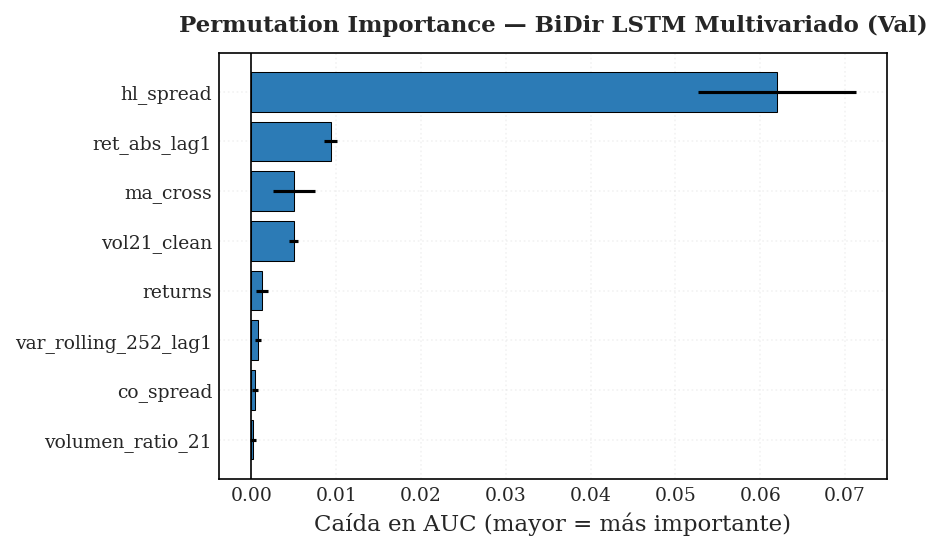


Calculando permutation importance — LSTM Simple Multi...

 Feature Importance — LSTM Simple Multi (caída AUC) 
             feature  importance_mean  importance_std
           hl_spread         0.029109        0.006624
            ma_cross         0.010495        0.003614
        ret_abs_lag1         0.004821        0.000337
         vol21_clean         0.004587        0.000629
    volumen_ratio_21         0.001389        0.001190
           co_spread         0.000954        0.000807
             returns         0.000536        0.000671
var_rolling_252_lag1         0.000301        0.000329


In [46]:
#  4.2 Permutation importance
def permutation_importance_lstm(model, X_val_w, y_val_w,
                                 feature_names, n_repeats=5,
                                 random_state=42):
    """
    Mide la importancia de cada feature por la caída en AUC al permutar
    aleatoriamente esa feature en las secuencias de validación.

    Parámetros
    ----------
    model        : modelo Keras entrenado
    X_val_w      : (N, L, F) — secuencias de validación escaladas
    y_val_w      : (N,) — labels de validación
    feature_names: lista de nombres de features (longitud = F)
    n_repeats    : número de permutaciones por feature

    Retorna
    -------
    pd.DataFrame con columnas [feature, importance_mean, importance_std]
    ordenado descendente.
    """
    rng = np.random.default_rng(random_state)
    yt  = y_val_w.astype(int)
    try:
        base_auc = roc_auc_score(yt, model.predict(X_val_w, verbose=0).ravel())
    except ValueError:
        print("AUC base no calculable — target sin variación")
        return pd.DataFrame()

    rows = []
    for f_idx, fname in enumerate(feature_names):
        drops = []
        for _ in range(n_repeats):
            X_perm = X_val_w.copy()
            # Permutar esa feature en todas las ventanas
            X_perm[:, :, f_idx] = rng.permutation(X_perm[:, :, f_idx])
            try:
                perm_auc = roc_auc_score(
                    yt, model.predict(X_perm, verbose=0).ravel())
                drops.append(base_auc - perm_auc)
            except ValueError:
                drops.append(0.0)
        rows.append({'feature': fname,
                     'importance_mean': float(np.mean(drops)),
                     'importance_std':  float(np.std(drops))})

    df_imp = (pd.DataFrame(rows)
              .sort_values('importance_mean', ascending=False)
              .reset_index(drop=True))
    return df_imp

print("Calculando permutation importance en validación...")
df_importance = permutation_importance_lstm(
    model_multi_bidir, Xw_val_multi, yw_val_multi,
    feature_names=FEATURES_MULTI, n_repeats=5, random_state=RANDOM_SEED)

print("\n Feature Importance (caída AUC al permutar) ")
print(df_importance.to_string(index=False))

# Plot
fig, ax = plt.subplots(figsize=fig_size("full"))
if not df_importance.empty: # Add this check
    colors_imp = [COLOR_VOL if v > 0 else COLOR_EXTREMO
                  for v in df_importance['importance_mean']]
    ax.barh(df_importance['feature'][::-1], df_importance['importance_mean'][::-1],
            xerr=df_importance['importance_std'][::-1],
            color=colors_imp[::-1], edgecolor='black', linewidth=0.5)
    ax.axvline(0, color='black', lw=0.8)
    ax.set_xlabel('Caída en AUC (mayor = más importante)')
    ax.set_title('Permutation Importance — BiDir LSTM Multivariado (Val)', fontweight='bold')
else:
    ax.text(0.5, 0.5, "No se pudo calcular la importancia de características (AUC base no calculable)",
            horizontalalignment='center', verticalalignment='center', transform=ax.transAxes)
    ax.set_title('Permutation Importance — BiDir LSTM Multivariado (Val)', fontweight='bold')

plt.tight_layout()
save_fig(fig, 'fig_lstm_multi_importance', output_path=FIG_PATH, dpi=300)
plt.show()
plt.close()

#  Permutation importance: LSTM Simple Multi
print("\nCalculando permutation importance — LSTM Simple Multi...")
df_importance_simple = permutation_importance_lstm(
    model_multi_simple, Xw_val_multi, yw_val_multi,
    feature_names=FEATURES_MULTI, n_repeats=5, random_state=RANDOM_SEED)

print("\n Feature Importance — LSTM Simple Multi (caída AUC) ")
print(df_importance_simple.to_string(index=False))

Esta figura resume la importancia por permutación de las variables del modelo LSTM multivariado en validation. Las barras representan la caída en AUC-ROC al perturbar cada predictor.

Las variables con mayor caída en AUC aportan más a la capacidad discriminativa del modelo. Valores cercanos a cero indican contribución limitada o redundante dentro del conjunto de features.

La figura permite identificar qué señales sostienen el desempeño del modelo multivariado y muestra que la información útil no está distribuida de forma homogénea entre las variables, lo que orienta posibles análisis de simplificación o ablation.

Umbral óptimo (val, criterio=f1): 0.1200
  F1=0.9825  P=1.0000  R=0.9655
  (Two-phase: grueso 19 + fino 11 = 27 umbrales evaluados)
  [val] LSTM-Simple-Multi         | F1=0.9825 | AUC=0.9995 | AUC-PR=0.9941 | thr=0.1200
  [test] LSTM-Simple-Multi         | F1=0.3968 | AUC=0.9892 | AUC-PR=0.8481 | thr=0.1200
Umbral óptimo (val, criterio=f1): 0.2000
  F1=0.9825  P=1.0000  R=0.9655
  (Two-phase: grueso 19 + fino 11 = 27 umbrales evaluados)
  [val] BiDir-LSTM-Multi          | F1=0.9825 | AUC=0.9989 | AUC-PR=0.9893 | thr=0.2000
  [test] BiDir-LSTM-Multi          | F1=0.5977 | AUC=0.9953 | AUC-PR=0.8755 | thr=0.2000
  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB02_Benchmark/Fig_NB02/fig_lstm_learning_curves_lstm_multivariado_curvas_de_aprendizaje.png  [6.1"×3.8" @ 300dpi]


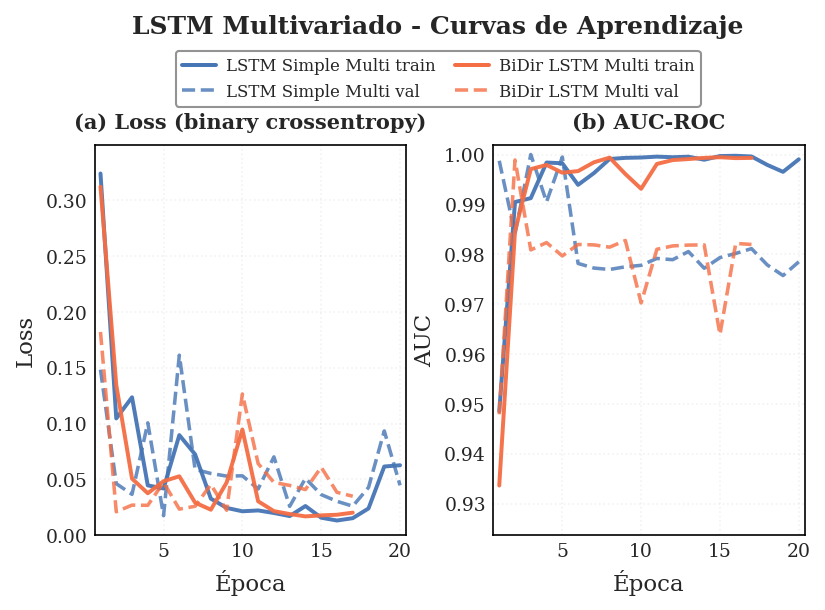

[OK] Figura guardada: fig_lstm_learning_curves_lstm_multivariado_curvas_de_aprendizaje.png
  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB02_Benchmark/Fig_NB02/fig_lstm_multi_eval.png  [6.1"×3.1" @ 300dpi]


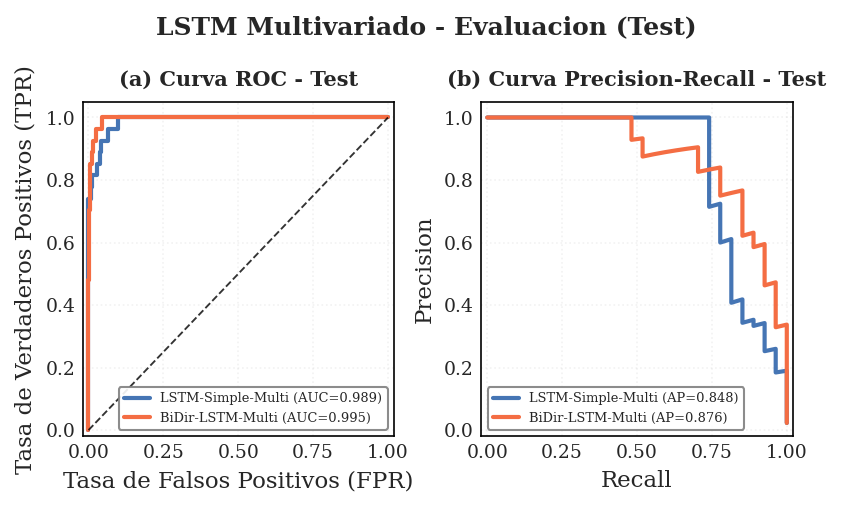

In [47]:
# 4.3 Evaluacion y comparacion - LSTM Multivariado
results_lstm_multi = {}

for arch_name, model in [('LSTM-Simple-Multi', model_multi_simple),
                         ('BiDir-LSTM-Multi', model_multi_bidir)]:
    best_thr, df_thr = optimize_threshold(
        model, Xw_val_multi, yw_val_multi,
        metric='f1', verbose=True
    )

    y_score_val = model.predict(Xw_val_multi, verbose=0).ravel()
    y_score_test = model.predict(Xw_test_multi, verbose=0).ravel()

    for split_name, y_w, y_score, decision_idx, target_idx in [
        ('val', yw_val_multi, y_score_val, idx_val_multi, target_idx_val_multi),
        ('test', yw_test_multi, y_score_test, idx_test_multi, target_idx_test_multi),
    ]:
        y_p = (y_score >= best_thr).astype(int)
        m = evaluar_baseline(arch_name, y_w.astype(int), y_p, y_score=y_score, split=split_name)
        print(f"  [{split_name}] {arch_name:25s} | F1={m['f1']:.4f} | AUC={m['auc']:.4f} | AUC-PR={m['auc_pr']:.4f} | thr={best_thr:.4f}")
        RESULTS_REGISTRY.append(m)
        register_model_output(
            MODEL_OUTPUTS, arch_name, split_name,
            decision_date=decision_idx,
            target_date=target_idx,
            y_true=y_w.astype(int),
            y_score=y_score,
            threshold=best_thr,
            rule='>=',
        )
        Y_SCORES[f"{arch_name}_{split_name}"] = (y_w.astype(int), y_score)

    OPTIMAL_THRESHOLDS[arch_name] = float(best_thr)
    results_lstm_multi[arch_name] = {'model': model, 'threshold': best_thr, 'thr_df': df_thr}

plot_learning_curves(
    {
        'LSTM Simple Multi': history_multi_simple,
        'BiDir LSTM Multi': history_multi,
    },
    title="LSTM Multivariado - Curvas de Aprendizaje"
)

fig, axes = plt.subplots(1, 2, figsize=fig_size("2x1"))
fig.suptitle('LSTM Multivariado - Evaluacion (Test)', fontweight='bold', fontsize=12, y=1.03)

for arch_name, data in results_lstm_multi.items():
    m_obj = data['model']
    y_s = m_obj.predict(Xw_test_multi, verbose=0).ravel()
    yt = yw_test_multi.astype(int)
    fpr, tpr, _ = roc_curve(yt, y_s)
    prec, rec, _ = precision_recall_curve(yt, y_s)
    col = COLORES_MODELOS.get(arch_name, COLOR_VAR)
    axes[0].plot(fpr, tpr, lw=2, color=col, label=f"{arch_name} (AUC={roc_auc_score(yt, y_s):.3f})")
    axes[1].plot(rec, prec, lw=2, color=col, label=f"{arch_name} (AP={average_precision_score(yt, y_s):.3f})")

axes[0].plot([0, 1], [0, 1], 'k--', lw=0.9, alpha=0.8)
axes[0].set_title('(a) Curva ROC - Test', fontweight='bold', fontsize=10, pad=8)
axes[0].set_xlabel('Tasa de Falsos Positivos (FPR)')
axes[0].set_ylabel('Tasa de Verdaderos Positivos (TPR)')
axes[0].set_xlim(-0.02, 1.02)
axes[0].set_ylim(-0.02, 1.05)
axes[1].set_title('(b) Curva Precision-Recall - Test', fontweight='bold', fontsize=10, pad=8)
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_xlim(-0.02, 1.02)
axes[1].set_ylim(-0.02, 1.05)

for ax in axes:
    ax.grid(alpha=0.25)
    ax.tick_params(axis='both', labelsize=9)

axes[0].legend(loc='lower right', fontsize=6.25, frameon=True, framealpha=0.90)
axes[1].legend(loc='lower left', fontsize=6.25, frameon=True, framealpha=0.90)

fig.subplots_adjust(top=0.84, wspace=0.28)
save_fig(fig, 'fig_lstm_multi_eval', output_path=FIG_PATH)
plt.show()
plt.close()

### Interpretación de los modelos LSTM multivariados

Los modelos LSTM multivariados permiten evaluar si la incorporación de variables adicionales mejora la detección de eventos extremos respecto al benchmark univariado. En esta corrida, ambas arquitecturas mantienen una capacidad de ranking alta en test, especialmente `BiDir-LSTM-Multi`, que alcanza el mejor AUC dentro del bloque multivariado.

Sin embargo, ese desempeño en términos de ranking no se traduce automáticamente en una mejora operativa frente al benchmark univariado. Aunque `BiDir-LSTM-Multi` es competitivo, el modelo canónico sigue siendo `LSTM-Simple-Uni`, lo que indica que añadir variables no garantiza por sí solo una mejora en F1 fuera de muestra.

En consecuencia, el bloque multivariado aporta evidencia útil sobre señal adicional y capacidad discriminativa, pero no desplaza al benchmark univariado simple como referencia principal del estudio.


### ¿Aportan valor las features adicionales?

La comparación entre versiones univariadas y multivariadas permite evaluar si añadir variables mejora realmente el desempeño fuera de muestra. En esta corrida, las arquitecturas multivariadas muestran buena capacidad discriminativa, pero no desplazan al benchmark univariado simple en desempeño operativo.

Esto sugiere que las features adicionales sí contienen señal útil, pero su incorporación no garantiza automáticamente una mejora en F1. La permutation importance ayuda a identificar qué variables sostienen la contribución real del modelo multivariado y cuáles parecen aportar poco o de forma redundante.

---

## Modelos complementarios no canónicos

Esta subsección resume el comportamiento de los modelos complementarios no canónicos. Su objetivo no es redefinir el benchmark principal, sino aportar evidencia adicional sobre robustez, capacidad discriminativa y desempeño operativo fuera del bloque H0–H3.
> Orden conservado: GRU Simple Uni -> GRU Bidir Uni -> TCN Uni -> XGBoost Tabular.


In [48]:
# -- GOBERNANZA: registros complementarios separados del canonico ---------
RESULTS_REGISTRY_COMPL = []
Y_SCORES_COMPL = {}
OPTIMAL_THRESHOLDS_COMPL = {}
MODEL_OUTPUTS_COMPL = {}

_run_mode = globals().get('RUN_MODE', 'canonical_cpu')
if _run_mode == 'canonical_cpu':
    ADDITIONAL_OUTPUT_DIR = f"{OUTPUT_PATH}/predicciones_nb02/adicionales"
else:
    ADDITIONAL_OUTPUT_DIR = globals().get('PRED_DIR', f"{OUTPUT_PATH}/predicciones_nb02_gpu/adicionales")
import os
os.makedirs(ADDITIONAL_OUTPUT_DIR, exist_ok=True)

print(f"[COMPL] RUN_MODE = {_run_mode}")
print(f"[COMPL] Output -> {ADDITIONAL_OUTPUT_DIR}")
print(f"[COMPL] RESULTS_REGISTRY canonico preservado (len={len(RESULTS_REGISTRY)})")
print(f"[COMPL] MODEL_OUTPUTS_COMPL inicializado (len={len(MODEL_OUTPUTS_COMPL)})")

[COMPL] RUN_MODE = canonical_cpu
[COMPL] Output -> /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB02_Benchmark/predicciones_nb02/adicionales
[COMPL] RESULTS_REGISTRY canonico preservado (len=10)
[COMPL] MODEL_OUTPUTS_COMPL inicializado (len=0)


In [49]:
# -- build_gru()
def build_gru(input_shape, architecture='simple', units=64, dropout=0.2, seed=42):
    tf.random.set_seed(seed)
    inp = keras.Input(shape=input_shape, name='input_seq')
    if architecture == 'simple':
        x = keras.layers.GRU(units, name='gru_1')(inp)
        x = keras.layers.Dropout(dropout, seed=seed, name='drop_1')(x)
    elif architecture == 'bidirectional':
        x = keras.layers.Bidirectional(keras.layers.GRU(units, return_sequences=True, name='gru_1'), name='bidir_1')(inp)
        x = keras.layers.Dropout(dropout, seed=seed, name='drop_1')(x)
        x = keras.layers.Bidirectional(keras.layers.GRU(units // 2, return_sequences=False, name='gru_2'), name='bidir_2')(x)
        x = keras.layers.Dropout(dropout, seed=seed, name='drop_2')(x)
    else:
        raise ValueError("architecture debe ser 'simple' o 'bidirectional'")
    out = keras.layers.Dense(1, activation='sigmoid', name='output')(x)
    model = keras.Model(inputs=inp, outputs=out, name=f'gru_{architecture}_{units}u')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='binary_crossentropy',
        metrics=[keras.metrics.AUC(name='auc'), keras.metrics.Precision(name='precision'), keras.metrics.Recall(name='recall')]
    )
    return model

results_gru = {}
for arch_name, arch_key in [('GRU-Simple-Uni', 'simple'), ('BiDir-GRU-Uni', 'bidirectional')]:
    tf.random.set_seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)
    m = build_gru(input_shape=(LOOKBACK, len(FEATURES_UNI)), architecture=arch_key, units=64, dropout=0.2, seed=RANDOM_SEED)
    m.fit(
        Xw_train_uni, yw_train_uni.astype(np.float32),
        validation_data=(Xw_val_uni, yw_val_uni.astype(np.float32)),
        epochs=200, batch_size=32,
        class_weight=CLASS_WEIGHTS,
        callbacks=make_callbacks(arch_name.lower().replace('-', '_'), output_path=ADDITIONAL_OUTPUT_DIR),
        shuffle=False, verbose=0
    )
    best_thr, _ = optimize_threshold(m, Xw_val_uni, yw_val_uni, metric='f1', verbose=True)
    for split_n, Xw, yw, decision_idx, target_idx in [('val', Xw_val_uni, yw_val_uni, idx_val_uni, target_idx_val_uni), ('test', Xw_test_uni, yw_test_uni, idx_test_uni, target_idx_test_uni)]:
        ys = m.predict(Xw, verbose=0).ravel()
        yp = (ys >= best_thr).astype(int)
        rec = evaluar_baseline(arch_name, yw.astype(int), yp, y_score=ys, split=split_n)
        RESULTS_REGISTRY_COMPL.append(rec)
        register_model_output(MODEL_OUTPUTS_COMPL, arch_name, split_n, decision_date=decision_idx, target_date=target_idx, y_true=yw.astype(int), y_score=ys, threshold=best_thr, rule='>=')
        Y_SCORES_COMPL[f'{arch_name}_{split_n}'] = (yw.astype(int), ys)
        print(f"  [COMPL][{split_n}] {arch_name} | F1={rec['f1']:.4f} | AUC={rec['auc']:.4f} | thr={best_thr:.2f}")
    OPTIMAL_THRESHOLDS_COMPL[arch_name] = float(best_thr)
    results_gru[arch_name] = {'model': m, 'threshold': best_thr}


Epoch 35: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 42: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
Epoch 43: early stopping
Restoring model weights from the end of the best epoch: 28.
Umbral óptimo (val, criterio=f1): 0.8200
  F1=0.9333  P=0.9032  R=0.9655
  (Two-phase: grueso 19 + fino 11 = 27 umbrales evaluados)
  [COMPL][val] GRU-Simple-Uni | F1=0.9333 | AUC=0.9969 | thr=0.82
  [COMPL][test] GRU-Simple-Uni | F1=0.9000 | AUC=0.9991 | thr=0.82

Epoch 32: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 39: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
Epoch 40: early stopping
Restoring model weights from the end of the best epoch: 25.
Umbral óptimo (val, criterio=f1): 0.9800
  F1=0.9825  P=1.0000  R=0.9655
  (Two-phase: grueso 19 + fino 10 = 27 umbrales evaluados)
  [COMPL][val] BiDir-GRU-Uni | F1=0.9825 | AUC=0.9992 | thr=0.98
  [COMPL][test] BiDir-GRU-Uni | F1=0.8571 | AUC=0.9991 |

### TCN — Temporal Convolutional Network
> Bai, Kolter & Koltun (2018): "An Empirical Evaluation of Generic
> Convolutional and Recurrent Networks for Sequence Modeling"
> Ventaja sobre LSTM: gradientes más estables, paralelizable.
> padding='causal' garantiza causalidad temporal estricta.


In [50]:
# -- build_tcn():
def build_tcn(input_shape, filters=64, kernel_size=3, n_blocks=3, dropout=0.2, seed=42):
    tf.random.set_seed(seed)
    inp = keras.Input(shape=input_shape, name='input_seq')
    x = inp
    for i in range(n_blocks):
        dilation = 2 ** i
        x = keras.layers.Conv1D(filters, kernel_size, padding='causal', dilation_rate=dilation, activation='relu', name=f'conv_d{dilation}')(x)
        x = keras.layers.BatchNormalization(name=f'bn_{i}')(x)
        x = keras.layers.Dropout(dropout, seed=seed, name=f'drop_{i}')(x)
    x = keras.layers.GlobalAveragePooling1D(name='gap')(x)
    x = keras.layers.Dense(32, activation='relu', name='fc')(x)
    out = keras.layers.Dense(1, activation='sigmoid', name='output')(x)
    model = keras.Model(inputs=inp, outputs=out, name=f'tcn_{filters}f_{n_blocks}b')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='binary_crossentropy',
        metrics=[keras.metrics.AUC(name='auc'), keras.metrics.Precision(name='precision'), keras.metrics.Recall(name='recall')]
    )
    return model

tf.random.set_seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)
model_tcn_uni = build_tcn(input_shape=(LOOKBACK, len(FEATURES_UNI)), filters=64, kernel_size=3, n_blocks=3, dropout=0.2, seed=RANDOM_SEED)
model_tcn_uni.fit(
    Xw_train_uni, yw_train_uni.astype(np.float32),
    validation_data=(Xw_val_uni, yw_val_uni.astype(np.float32)),
    epochs=200, batch_size=32,
    class_weight=CLASS_WEIGHTS,
    callbacks=make_callbacks('tcn_uni', output_path=ADDITIONAL_OUTPUT_DIR),
    shuffle=False, verbose=0
)
best_thr_tcn, _ = optimize_threshold(model_tcn_uni, Xw_val_uni, yw_val_uni, metric='f1', verbose=True)
for split_n, Xw, yw, decision_idx, target_idx in [('val', Xw_val_uni, yw_val_uni, idx_val_uni, target_idx_val_uni), ('test', Xw_test_uni, yw_test_uni, idx_test_uni, target_idx_test_uni)]:
    ys = model_tcn_uni.predict(Xw, verbose=0).ravel()
    yp = (ys >= best_thr_tcn).astype(int)
    rec = evaluar_baseline('TCN-Uni', yw.astype(int), yp, y_score=ys, split=split_n)
    RESULTS_REGISTRY_COMPL.append(rec)
    register_model_output(MODEL_OUTPUTS_COMPL, 'TCN-Uni', split_n, decision_date=decision_idx, target_date=target_idx, y_true=yw.astype(int), y_score=ys, threshold=best_thr_tcn, rule='>=')
    Y_SCORES_COMPL[f'TCN-Uni_{split_n}'] = (yw.astype(int), ys)
    print(f"  [COMPL][{split_n}] TCN-Uni | F1={rec['f1']:.4f} | AUC={rec['auc']:.4f} | thr={best_thr_tcn:.2f}")
OPTIMAL_THRESHOLDS_COMPL['TCN-Uni'] = float(best_thr_tcn)


Epoch 10: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 36: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 43: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.
Epoch 44: early stopping
Restoring model weights from the end of the best epoch: 29.
Umbral óptimo (val, criterio=f1): 0.8100
  F1=0.9655  P=0.9655  R=0.9655
  (Two-phase: grueso 19 + fino 11 = 27 umbrales evaluados)
  [COMPL][val] TCN-Uni | F1=0.9655 | AUC=0.9996 | thr=0.81
  [COMPL][test] TCN-Uni | F1=0.0000 | AUC=0.6096 | thr=0.81


### XGBoost Tabular Baseline (COMPLEMENTARIO)

In [51]:
# -- XGBoost Tabular Baseline
from xgboost import XGBClassifier

FEATURES_XGB_LAGS = {
    'vol21_clean': [1, 5, 21],
    'returns': [1, 5],
    'ret_abs_lag1': [1],
    'var_rolling_252_lag1': [1],
}

df_xgb = df.copy()
for feat, lags in FEATURES_XGB_LAGS.items():
    for lag in lags:
        col = f"{feat}_lag{lag}"
        if col not in df_xgb.columns:
            df_xgb[col] = df_xgb[feat].shift(lag)

FEATURES_XGB_ALL = FEATURES_MULTI + [
    f"{feat}_lag{lag}"
    for feat, lags in FEATURES_XGB_LAGS.items()
    for lag in lags
    if f"{feat}_lag{lag}" not in FEATURES_MULTI
]

df_xgb_family, mask_xgb = build_family_frame(df_xgb, FEATURES_XGB_ALL, 'xgb')
df_tr_xgb, df_va_xgb, df_te_xgb = split_family_frame(df_xgb_family)

X_tr = df_tr_xgb[FEATURES_XGB_ALL].values
y_tr = df_tr_xgb['y_tp1'].values.astype(int)
X_va = df_va_xgb[FEATURES_XGB_ALL].values
y_va = df_va_xgb['y_tp1'].values.astype(int)
X_te = df_te_xgb[FEATURES_XGB_ALL].values
y_te = df_te_xgb['y_tp1'].values.astype(int)

scale_pos_w = int((y_tr == 0).sum() / max((y_tr == 1).sum(), 1))
print(f"[XGB] Train: {len(y_tr)} obs | Positivos: {y_tr.sum()} | scale_pos_weight={scale_pos_w}")
print(f"[XGB] Val: {len(y_va)} | Test: {len(y_te)} | Features: {len(FEATURES_XGB_ALL)}")

[XGB] Train: 4454 obs | Positivos: 230 | scale_pos_weight=18
[XGB] Val: 460 | Test: 1289 | Features: 15


In [52]:
# -- XGBoost fit + threshold en val ---------------------------------------
xgb_model = XGBClassifier(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=scale_pos_w,
    eval_metric='aucpr', early_stopping_rounds=20,
    random_state=RANDOM_SEED, verbosity=0,
    nthread=1,
)
xgb_model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)

ys_va_xgb = xgb_model.predict_proba(X_va)[:, 1]
ys_te_xgb = xgb_model.predict_proba(X_te)[:, 1]

best_f1_va, best_thr_xgb = 0.0, 0.5
for thr in np.arange(0.05, 0.96, 0.05):
    f1v = f1_score(y_va, (ys_va_xgb >= thr).astype(int), zero_division=0)
    if f1v > best_f1_va:
        best_f1_va, best_thr_xgb = f1v, float(thr)
fine_lo = max(0.01, best_thr_xgb - 0.05)
fine_hi = min(0.99, best_thr_xgb + 0.06)
for thr in np.arange(fine_lo, fine_hi, 0.01):
    f1v = f1_score(y_va, (ys_va_xgb >= thr).astype(int), zero_division=0)
    if f1v > best_f1_va:
        best_f1_va, best_thr_xgb = f1v, float(thr)

y_pred_xgb_test = (ys_te_xgb >= best_thr_xgb).astype(int)
f1_xgb_test = f1_score(y_te, y_pred_xgb_test, zero_division=0)
auc_xgb_test = roc_auc_score(y_te, ys_te_xgb)

for split_n, df_split, ys, yw in [('val', df_va_xgb, ys_va_xgb, y_va), ('test', df_te_xgb, ys_te_xgb, y_te)]:
    yp = (ys >= best_thr_xgb).astype(int)
    rec = evaluar_baseline('XGBoost-Tabular', yw, yp, y_score=ys, split=split_n)
    RESULTS_REGISTRY_COMPL.append(rec)
    register_model_output(
        MODEL_OUTPUTS_COMPL, 'XGBoost-Tabular', split_n,
        decision_date=df_split['decision_date'],
        target_date=df_split['target_date'],
        y_true=np.asarray(yw).astype(int),
        y_score=ys,
        threshold=best_thr_xgb,
        rule='>=',
    )
    Y_SCORES_COMPL[f'XGBoost-Tabular_{split_n}'] = (np.asarray(yw).astype(int), ys)
    print(f"  [COMPL][{split_n}] XGBoost-Tabular | F1={rec['f1']:.4f} | AUC={rec['auc']:.4f} | thr={best_thr_xgb:.2f}")

OPTIMAL_THRESHOLDS_COMPL['XGBoost-Tabular'] = float(best_thr_xgb)

  [COMPL][val] XGBoost-Tabular | F1=0.9825 | AUC=0.9996 | thr=0.45
  [COMPL][test] XGBoost-Tabular | F1=0.9455 | AUC=0.9994 | thr=0.45


In [53]:
# -- XGBoost Export Robusto -----------------------------------------------
xgb_test_output = get_model_output('XGBoost-Tabular', split='test')
xgb_csv_path = f"{ADDITIONAL_OUTPUT_DIR}/pred_XGBoost-Tabular_test.csv"
xgb_test_output.to_csv(xgb_csv_path, index=False)

xgb_reload = pd.read_csv(xgb_csv_path, parse_dates=['decision_date', 'target_date'])
assert len(xgb_reload) == len(xgb_test_output), f"ERROR longitud: CSV={len(xgb_reload)} != expected={len(xgb_test_output)}"
assert xgb_reload['y_score'].between(0, 1).all(), f"ERROR: scores fuera de [0,1] -- min={xgb_reload['y_score'].min():.4f}"
assert not xgb_reload['y_score'].isna().any(), "ERROR: NaN en scores exportados"
f1_from_csv = f1_score(xgb_reload['y_true'], xgb_reload['y_pred'], zero_division=0)
assert abs(f1_from_csv - f1_xgb_test) < 1e-6, f"DISCREPANCIA F1: CSV={f1_from_csv:.6f} vs memoria={f1_xgb_test:.6f}"

XGB_STATUS = "VALIDO"
if f1_xgb_test > 0.90:
    XGB_STATUS = "PROVISIONAL"
    print("ATENCION: XGBoost F1 > 0.90 -- posible inflacion por autocorrelacion vol21.")
    print("  vol21(t) y vol21(t+1) comparten 20/21 dias de retornos.")

print(f"[XGB] F1_test={f1_xgb_test:.4f} | AUC_test={auc_xgb_test:.4f} | thr={best_thr_xgb:.2f}")
print(f"[XGB] Status={XGB_STATUS} | CSV validado: {xgb_csv_path}")

ATENCION: XGBoost F1 > 0.90 -- posible inflacion por autocorrelacion vol21.
  vol21(t) y vol21(t+1) comparten 20/21 dias de retornos.
[XGB] F1_test=0.9455 | AUC_test=0.9994 | thr=0.45
[XGB] Status=PROVISIONAL | CSV validado: /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB02_Benchmark/predicciones_nb02/adicionales/pred_XGBoost-Tabular_test.csv


In [54]:
# -- Tabla comparativa: complementarios -----------------------------------

_compl_test = [r for r in RESULTS_REGISTRY_COMPL if r.get('split') == 'test']

if _compl_test:
    df_compl = pd.DataFrame(_compl_test).sort_values('f1', ascending=False)

    print("=" * 70)
    print("  MODELOS COMPLEMENTARIOS NO CANÓNICOS")
    print("  Resumen en test — fuera del bloque principal H0–H3")
    print("=" * 70)

    for _, row in df_compl.iterrows():
        status_str = f" [{XGB_STATUS}]" if row['nombre'] == 'XGBoost-Tabular' else ""
        print(f"  {row['nombre']:<25} F1={row['f1']:.4f}  AUC={row['auc']:.4f}{status_str}")

    print("=" * 70)

    # Referencia canónica dinámica desde bench_test
    _canon_name = "LSTM-Simple-Uni"
    _canon_row = bench_test[bench_test['nombre'] == _canon_name]

    if not _canon_row.empty:
        _canon_f1 = float(_canon_row.iloc[0]['f1'])
        _canon_auc = float(_canon_row.iloc[0]['auc'])
        print(f"  Referencia canónica: {_canon_name}  F1={_canon_f1:.4f}  AUC={_canon_auc:.4f}")
    else:
        print(f"  Referencia canónica: {_canon_name}  [no encontrada en bench_test]")

    print("=" * 70)

else:
    print("[COMPL] Sin resultados complementarios en RESULTS_REGISTRY_COMPL.")

  MODELOS COMPLEMENTARIOS NO CANÓNICOS
  Resumen en test — fuera del bloque principal H0–H3
  XGBoost-Tabular           F1=0.9455  AUC=0.9994 [PROVISIONAL]
  GRU-Simple-Uni            F1=0.9000  AUC=0.9991
  BiDir-GRU-Uni             F1=0.8571  AUC=0.9991
  TCN-Uni                   F1=0.0000  AUC=0.6096
  Referencia canónica: LSTM-Simple-Uni  F1=0.7801  AUC=0.9987


### Lectura del bloque complementario

Los modelos complementarios no canónicos amplían la interpretación del benchmark sin redefinir el bloque principal H0–H3. En esta corrida, `XGBoost-Tabular` muestra el mejor desempeño descriptivo, aunque su estatus se mantiene como provisional bajo la advertencia metodológica ya documentada sobre posible inflación asociada a la autocorrelación de `vol21`.

`GRU-Simple-Uni` se mantiene como una alternativa competitiva y `BiDir-GRU-Uni` conserva buen desempeño, pero ninguno desplaza al modelo canónico del benchmark. En contraste, `TCN-Uni` presenta una degradación marcada en test, lo que sugiere una transferencia más débil fuera de muestra.

En conjunto, este bloque aporta evidencia adicional sobre robustez y capacidad discriminativa, pero debe leerse como complementario al benchmark canónico y no como un reemplazo automático de sus conclusiones.

---
## PARTE V — Extensiones híbridas complementarias (fuera del benchmark H0-H3)

Esta parte extiende el LSTM multivariado con señales exógenas derivadas de NB03A (sentimiento) y NB03B (market signals). Se conserva como análisis complementario y no redefine el ranking canónico H0-H3.

### Datos requeridos (externos a este notebook)
- `wti_sentiment_finbert.csv` y metadata `nb03`, si se evalúa el híbrido con sentimiento.
- `wti_market_signals.csv` y metadata `nb03b`, si se evalúa el híbrido con señales de mercado.

### Alcance interpretativo
- Los resultados híbridos deben leerse junto con la cobertura y limitaciones documentadas en NB03A/NB03B.
- Esta sección no sustituye la tabla maestra del benchmark CPU.

> **Dependencia opcional:** Para activar `FORCE_DISABLE_SENTIMENT = False` instalar:
> `pip install transformers torch`
> No necesario para el benchmark canónico H0-H3 (híbridos desactivados por FORCE_DISABLE).

In [55]:
#  Override explícito: excluir híbridos del benchmark oficial (no forman parte de H0-H3)
FORCE_DISABLE_SENTIMENT = True   # True = omitir Hybrid-LSTM-Sentimiento
FORCE_DISABLE_MARKET    = True   # True = omitir Hybrid-LSTM-MktSignals

_sent_csv_ok = Path(f"{BASE_PATH}/NB03_FinBERT/wti_sentiment_finbert.csv").exists()
SENTIMENT_DATA_AVAILABLE = _sent_csv_ok and not FORCE_DISABLE_SENTIMENT

# La segunda bandera aísla el híbrido de mercado para que su ausencia no altere el benchmark principal.
_mkt_csv_ok = Path(f"{BASE_PATH}/NB03B_MarketSignals/wti_market_signals.csv").exists()
MARKET_SIGNALS_AVAILABLE = _mkt_csv_ok and not FORCE_DISABLE_MARKET

sent_status = "OK" if _sent_csv_ok else "FALTA"
mkt_status  = "OK" if _mkt_csv_ok  else "FALTA"
print(f"[CONFIG] SENTIMENT = {SENTIMENT_DATA_AVAILABLE} (csv={sent_status}, force_disable={FORCE_DISABLE_SENTIMENT})")
print(f"[CONFIG] MARKET    = {MARKET_SIGNALS_AVAILABLE} (csv={mkt_status}, force_disable={FORCE_DISABLE_MARKET})")
print()
print("NOTA: FORCE_DISABLE_SENTIMENT=True y FORCE_DISABLE_MARKET=True — hibridos excluidos del benchmark H0-H3.")
print("  Hybrid-LSTM-Sentimiento se mantiene como análisis complementario (resultado negativo).")
print("  Ver NB03: correlacion r=0.009, IC95%=[-0.052,+0.046]")

#  5.2 Carga de datos de sentimiento
FINBERT_CSV = f"{BASE_PATH}/NB03_FinBERT/wti_sentiment_finbert.csv"  # alias canónico
if SENTIMENT_DATA_AVAILABLE:
    assert Path(FINBERT_CSV).exists(), \
        f"CSV sentimiento no encontrado: {FINBERT_CSV}\n  -> Ejecutar NB03 primero."
    df_sent = pd.read_csv(FINBERT_CSV, index_col='Date', parse_dates=True)
    print(f"Sentimiento cargado: {df_sent.shape} | "
          f"Columnas lag1: {[c for c in df_sent.columns if 'lag1' in c]}")

[CONFIG] SENTIMENT = False (csv=OK, force_disable=True)
[CONFIG] MARKET    = False (csv=OK, force_disable=True)

NOTA: FORCE_DISABLE_SENTIMENT=True y FORCE_DISABLE_MARKET=True — hibridos excluidos del benchmark H0-H3.
  Hybrid-LSTM-Sentimiento se mantiene como análisis complementario (resultado negativo).
  Ver NB03: correlacion r=0.009, IC95%=[-0.052,+0.046]


In [56]:
# 5.3 Construccion del Dataset Hibrido (anti-leakage temporal)
RUN_HYBRID_SENT = SENTIMENT_DATA_AVAILABLE
if RUN_HYBRID_SENT:
    if not Path(FINBERT_CSV).exists():
        raise FileNotFoundError(f"CSV de sentimiento no encontrado: {FINBERT_CSV}. Ejecuta NB03 primero.")
    df_sent = pd.read_csv(FINBERT_CSV, index_col='Date', parse_dates=True)
    FEATURES_SENT_LAG1 = ['sentiment_score_lag1', 'sentiment_std_lag1', 'n_articles_lag1', 'pct_positive_lag1', 'pct_negative_lag1']
    missing_cols = [c for c in FEATURES_SENT_LAG1 if c not in df_sent.columns]
    if missing_cols:
        raise ValueError(f"Faltan columnas lag1 en {FINBERT_CSV}: {missing_cols}. Re-ejecuta NB03.")

    FEATURES_HYBRID = FEATURES_MULTI + FEATURES_SENT_LAG1
    forbidden = {'sentiment_score', 'n_articles', 'pct_positive', 'pct_negative', 'sentiment_flag'}
    assert forbidden.isdisjoint(set(FEATURES_HYBRID)), "LEAKAGE detectado en FEATURES_HYBRID"

    df_hybrid_base = df.join(df_sent[FEATURES_SENT_LAG1], how='left')
    df_hybrid_family, mask_hybrid_sent = build_family_frame(df_hybrid_base, FEATURES_HYBRID, 'hybrid_sent')
    df_h_train, df_h_val, df_h_test = split_family_frame(df_hybrid_family)

    y_h_train = df_h_train['y_tp1'].values.astype(int)
    y_h_val = df_h_val['y_tp1'].values.astype(int)
    y_h_test = df_h_test['y_tp1'].values.astype(int)

    scaler_hybrid = StandardScaler()
    X_h_train = scaler_hybrid.fit_transform(df_h_train[FEATURES_HYBRID]).astype(np.float32)
    X_h_val = scaler_hybrid.transform(df_h_val[FEATURES_HYBRID]).astype(np.float32)
    X_h_test = scaler_hybrid.transform(df_h_test[FEATURES_HYBRID]).astype(np.float32)

    MODEL_SAVE_DIR = globals().get('MODEL_DIR', f"{OUTPUT_PATH}/modelos_nb02")
    os.makedirs(MODEL_SAVE_DIR, exist_ok=True)
    with open(f"{MODEL_SAVE_DIR}/scaler_hybrid_sent.pkl", 'wb') as fh:
        pickle.dump(scaler_hybrid, fh)

    Xw_h_train, yw_h_train, idx_h_train, target_idx_h_train = windowed_dataset(X_h_train, y_h_train, df_h_train.index, lookback=LOOKBACK, target_index=df_h_train['target_date'], segment_id=df_h_train['segment_id'])
    Xw_h_val, yw_h_val, idx_h_val, target_idx_h_val = windowed_dataset(X_h_val, y_h_val, df_h_val.index, lookback=LOOKBACK, target_index=df_h_val['target_date'], segment_id=df_h_val['segment_id'])
    Xw_h_test, yw_h_test, idx_h_test, target_idx_h_test = windowed_dataset(X_h_test, y_h_test, df_h_test.index, lookback=LOOKBACK, target_index=df_h_test['target_date'], segment_id=df_h_test['segment_id'])

    tf.random.set_seed(RANDOM_SEED)
    model_hybrid = build_model(input_shape=(LOOKBACK, len(FEATURES_HYBRID)), architecture='bidirectional', lstm_units=64, dropout=0.2, seed=RANDOM_SEED)
    if len(np.unique(yw_h_train)) < 2:
        CLASS_WEIGHTS_SENT = CLASS_WEIGHTS
    else:
        cw_h = compute_class_weight('balanced', classes=np.array([0, 1]), y=yw_h_train)
        CLASS_WEIGHTS_SENT = {0: float(cw_h[0]), 1: float(cw_h[1])}

    history_hybrid = model_hybrid.fit(
        Xw_h_train, yw_h_train.astype(np.float32),
        validation_data=(Xw_h_val, yw_h_val.astype(np.float32)),
        epochs=200, batch_size=32,
        class_weight=CLASS_WEIGHTS_SENT,
        callbacks=make_callbacks('lstm_hybrid', output_path=ADDITIONAL_OUTPUT_DIR),
        shuffle=False, verbose=1
    )

    best_thr_h, _ = optimize_threshold(model_hybrid, Xw_h_val, yw_h_val, metric='f1', verbose=True)
    for split_name, X_w, y_w, decision_idx, target_idx in [('val', Xw_h_val, yw_h_val, idx_h_val, target_idx_h_val), ('test', Xw_h_test, yw_h_test, idx_h_test, target_idx_h_test)]:
        y_s = model_hybrid.predict(X_w, verbose=0).ravel()
        y_p = (y_s >= best_thr_h).astype(int)
        m = evaluar_baseline('Hybrid-LSTM-Sentimiento', y_w.astype(int), y_p, y_score=y_s, split=split_name)
        RESULTS_REGISTRY_COMPL.append(m)
        register_model_output(MODEL_OUTPUTS_COMPL, 'Hybrid-LSTM-Sentimiento', split_name, decision_date=decision_idx, target_date=target_idx, y_true=y_w.astype(int), y_score=y_s, threshold=best_thr_h, rule='>=')
        Y_SCORES_COMPL[f'Hybrid-LSTM-Sentimiento_{split_name}'] = (y_w.astype(int), y_s)
        print(f"  [{split_name}] {m['nombre']} | F1={m['f1']:.4f} | AUC={m['auc']:.4f} | AUC-PR={m['auc_pr']:.4f}")
    OPTIMAL_THRESHOLDS_COMPL['Hybrid-LSTM-Sentimiento'] = float(best_thr_h)
else:
    print("[SKIP] Modo hibrido desactivado (SENTIMENT_DATA_AVAILABLE=False).")

[SKIP] Modo hibrido desactivado (SENTIMENT_DATA_AVAILABLE=False).


In [57]:
#  5.4 Carga de señales de mercado (NB03B) ─
# Se conserva el alias local MKTCSV solo para no romper referencias internas de esta celda.
MKTCSV = MARKET_SIGNALS_CSV

if MARKET_SIGNALS_AVAILABLE:
    assert Path(MKTCSV).exists(), \
        f"CSV señales no encontrado: {MKTCSV}\n  → Ejecutar NB03B primero."
    df_mkt = pd.read_csv(MKTCSV, index_col='Date', parse_dates=True)
    print(f"Señales de mercado cargadas: {df_mkt.shape}")
    print(f"  Features lag1: {[c for c in df_mkt.columns if 'lag1' in c]}")
else:
    print("[SKIP] NB03B no disponible — ejecutar 3_WTI_Market_Signals.ipynb primero.")
    for split_name in ['val', 'test']:
        RESULTS_REGISTRY.append({
            'nombre': 'Hybrid-LSTM-MktSignals', 'split': split_name,
            'f1': float('nan'), 'auc': float('nan'), 'auc_pr': float('nan'),
            'precision': float('nan'), 'recall': float('nan'),
            'tp': None, 'fp': None, 'fn': None, 'tn': None,
            'status': 'PENDING — ejecutar NB03B'
        })

[SKIP] NB03B no disponible — ejecutar 3_WTI_Market_Signals.ipynb primero.


In [58]:
# 5.5 Construccion Dataset Hibrido - Senales de Mercado
RUN_HYBRID_MKT = MARKET_SIGNALS_AVAILABLE
if RUN_HYBRID_MKT:
    FEATURES_MKT_LAG1 = ['vix_ret_lag1', 'dxy_ret_lag1', 'eia_surprise_lag1']
    missing = [c for c in FEATURES_MKT_LAG1 if c not in df_mkt.columns]
    if missing:
        raise ValueError(f"Features faltantes en NB03B: {missing}")

    FEATURES_HYBRID_MKT = FEATURES_MULTI + FEATURES_MKT_LAG1
    assert all(c in FEATURES_MULTI or c.endswith('_lag1') for c in FEATURES_HYBRID_MKT), "LEAKAGE: feature sin lag1 en FEATURES_HYBRID_MKT"

    df_hybrid_mkt_base = df.join(df_mkt[FEATURES_MKT_LAG1], how='left')
    df_hybrid_mkt_family, mask_hybrid_mkt = build_family_frame(df_hybrid_mkt_base, FEATURES_HYBRID_MKT, 'hybrid_mkt')
    df_hm_train, df_hm_val, df_hm_test = split_family_frame(df_hybrid_mkt_family)

    y_hm_train = df_hm_train['y_tp1'].values.astype(int)
    y_hm_val = df_hm_val['y_tp1'].values.astype(int)
    y_hm_test = df_hm_test['y_tp1'].values.astype(int)

    scaler_hybrid_mkt = StandardScaler()
    X_hm_train = scaler_hybrid_mkt.fit_transform(df_hm_train[FEATURES_HYBRID_MKT]).astype(np.float32)
    X_hm_val = scaler_hybrid_mkt.transform(df_hm_val[FEATURES_HYBRID_MKT]).astype(np.float32)
    X_hm_test = scaler_hybrid_mkt.transform(df_hm_test[FEATURES_HYBRID_MKT]).astype(np.float32)

    MODEL_SAVE_DIR = globals().get('MODEL_DIR', f"{OUTPUT_PATH}/modelos_nb02")
    os.makedirs(MODEL_SAVE_DIR, exist_ok=True)
    with open(f"{MODEL_SAVE_DIR}/scaler_hybrid_mkt.pkl", 'wb') as fh:
        pickle.dump(scaler_hybrid_mkt, fh)

    Xw_hm_train, yw_hm_train, idx_hm_train, target_idx_hm_train = windowed_dataset(X_hm_train, y_hm_train, df_hm_train.index, lookback=LOOKBACK, target_index=df_hm_train['target_date'], segment_id=df_hm_train['segment_id'])
    Xw_hm_val, yw_hm_val, idx_hm_val, target_idx_hm_val = windowed_dataset(X_hm_val, y_hm_val, df_hm_val.index, lookback=LOOKBACK, target_index=df_hm_val['target_date'], segment_id=df_hm_val['segment_id'])
    Xw_hm_test, yw_hm_test, idx_hm_test, target_idx_hm_test = windowed_dataset(X_hm_test, y_hm_test, df_hm_test.index, lookback=LOOKBACK, target_index=df_hm_test['target_date'], segment_id=df_hm_test['segment_id'])

    tf.random.set_seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)
    model_hybrid_mkt = build_model(input_shape=(LOOKBACK, len(FEATURES_HYBRID_MKT)), architecture='bidirectional', lstm_units=64, dropout=0.2, seed=RANDOM_SEED)
    cw_hm = compute_class_weight('balanced', classes=np.array([0, 1]), y=yw_hm_train)
    CLASS_WEIGHTS_MKT = {0: float(cw_hm[0]), 1: float(cw_hm[1])}

    history_hybrid_mkt = model_hybrid_mkt.fit(
        Xw_hm_train, yw_hm_train.astype(np.float32),
        validation_data=(Xw_hm_val, yw_hm_val.astype(np.float32)),
        epochs=200, batch_size=32,
        class_weight=CLASS_WEIGHTS_MKT,
        callbacks=make_callbacks('lstm_hybrid_mkt', output_path=ADDITIONAL_OUTPUT_DIR),
        shuffle=False, verbose=1
    )

    best_thr_hm, _ = optimize_threshold(model_hybrid_mkt, Xw_hm_val, yw_hm_val, metric='f1', verbose=True)
    for split_name, X_w, y_w, decision_idx, target_idx in [('val', Xw_hm_val, yw_hm_val, idx_hm_val, target_idx_hm_val), ('test', Xw_hm_test, yw_hm_test, idx_hm_test, target_idx_hm_test)]:
        y_s = model_hybrid_mkt.predict(X_w, verbose=0).ravel()
        y_p = (y_s >= best_thr_hm).astype(int)
        m = evaluar_baseline('Hybrid-LSTM-MktSignals', y_w.astype(int), y_p, y_score=y_s, split=split_name)
        RESULTS_REGISTRY_COMPL.append(m)
        register_model_output(MODEL_OUTPUTS_COMPL, 'Hybrid-LSTM-MktSignals', split_name, decision_date=decision_idx, target_date=target_idx, y_true=y_w.astype(int), y_score=y_s, threshold=best_thr_hm, rule='>=')
        Y_SCORES_COMPL[f'Hybrid-LSTM-MktSignals_{split_name}'] = (y_w.astype(int), y_s)
        print(f"  [{split_name}] {m['nombre']} | F1={m['f1']:.4f} | AUC={m['auc']:.4f} | AUC-PR={m['auc_pr']:.4f} | thr={best_thr_hm:.2f}")
    OPTIMAL_THRESHOLDS_COMPL['Hybrid-LSTM-MktSignals'] = float(best_thr_hm)
else:
    print("[SKIP] Modo hibrido market desactivado (MARKET_SIGNALS_AVAILABLE=False).")

[SKIP] Modo hibrido market desactivado (MARKET_SIGNALS_AVAILABLE=False).


---
## PARTE VI — Comparación y benchmark final

Consolidación del benchmark canónico H0-H3 sobre las familias oficiales evaluadas en CPU, usando como referencias B1 y B5 heredadas de NB01.

> **Mapa de lectura:** §6.1 tabla maestra = benchmark canónico H0-H3; §6.2–6.3 trade-off/bootstrap = robustez; §6.4–6.5 DM/McNemar = inferencia estadística; §6.6 sensibilidad = análisis post-hoc.
>
> Los híbridos (PARTE V), la ablación EarlyStopping y Optuna (PARTE VIII / NB02 GPU) se leen aparte y no alteran el ranking canónico H0-H3.

In [84]:
# 6.1 Tabla maestra de resultados
# Separa canónicos, complementarios y baselines

CANONICAL_MODELS = {
    'GARCH-GJR-GARCH',
    'LSTM-Simple-Uni',
    'BiDir-LSTM-Uni',
    'LSTM-Simple-Multi',
    'BiDir-LSTM-Multi',
}

BASELINE_NAMES = {
    'B1 - Estandar minimo (ingenuo)',
    'B5 - Ref. cuantitativa (Christoffersen)',
}

def classify_family(nombre: str) -> str:
    if nombre in BASELINE_NAMES:
        return 'baseline'
    if nombre in CANONICAL_MODELS:
        return 'canonico'
    return 'complementario'

def build_benchmark_table(
    registry,
    f1_min,
    auc_min,
    f1_cuant=None,
    auc_cuant=None,
    split_filter='test',
):
    rows = [r for r in registry if r.get('split', 'test') == split_filter]
    df_b = pd.DataFrame(rows)

    if df_b.empty:
        print("Sin resultados en el registro para el split:", split_filter)
        return df_b

    # Conteos reales desde outputs exportados
    counts = build_output_counts(stores=[
        globals().get('MODEL_OUTPUTS', {}),
        globals().get('MODEL_OUTPUTS_COMPL', {}),
    ])

    if not counts.empty:
        df_b = df_b.merge(
            counts.rename(columns={'model_name': 'nombre'}),
            on=['nombre', 'split'],
            how='left'
        )

    # Mantener filas que realmente se ejecutaron:
    metric_cols = [c for c in ['f1', 'auc', 'auc_pr', 'precision', 'recall'] if c in df_b.columns]
    has_any_metric = df_b[metric_cols].notna().any(axis=1) if metric_cols else pd.Series(False, index=df_b.index)
    has_eval = df_b['n_eval'].notna() if 'n_eval' in df_b.columns else pd.Series(False, index=df_b.index)
    is_baseline = df_b['nombre'].isin(BASELINE_NAMES)

    df_b = df_b[has_any_metric | has_eval | is_baseline].copy()

    # Si hay duplicados por re-ejecución:
    # priorizar fila con más evidencia (n_eval, f1, auc)
    sort_cols = []
    ascending = []

    if 'n_eval' in df_b.columns:
        sort_cols.append('n_eval')
        ascending.append(False)
    if 'f1' in df_b.columns:
        sort_cols.append('f1')
        ascending.append(False)
    if 'auc' in df_b.columns:
        sort_cols.append('auc')
        ascending.append(False)

    if sort_cols:
        df_b = (
            df_b.sort_values(['nombre'] + sort_cols, ascending=[True] + ascending)
                .drop_duplicates(subset=['nombre', 'split'], keep='first')
                .copy()
        )

    # Métricas derivadas
    if 'f1' in df_b.columns:
        df_b['Delta_F1'] = df_b['f1'] - f1_min
    if 'auc' in df_b.columns:
        df_b['Delta_AUC'] = df_b['auc'] - auc_min

    if 'f1' in df_b.columns and 'auc' in df_b.columns:
        df_b['Beats_Ingenuo'] = (df_b['f1'] > f1_min) & (df_b['auc'] > auc_min)
    else:
        df_b['Beats_Ingenuo'] = False

    if f1_cuant is not None and 'f1' in df_b.columns:
        df_b['Beats_Cuant'] = df_b['f1'] > f1_cuant

    # Clasificación de familia
    df_b['familia'] = df_b['nombre'].apply(classify_family).map({
    'canonico': 'Canónico',
    'complementario': 'Complementario',
    'baseline': 'Baseline',})

    # Orden de familias: canónico -> complementario -> baseline
    family_order = {'canonico': 0, 'complementario': 1, 'baseline': 2}
    df_b['_family_order'] = df_b['familia'].map(family_order).fillna(9)

    # Columnas finales
    cols = [
        'familia', 'nombre', 'n_eval', 'f1', 'auc', 'auc_pr',
        'precision', 'recall', 'tp', 'fp', 'fn', 'tn',
        'Delta_F1', 'Delta_AUC', 'Beats_Ingenuo', 'Beats_Cuant'
    ]
    cols_present = [c for c in cols if c in df_b.columns]

    df_b = (
      df_b.sort_values(['_family_order', 'f1', 'auc'], ascending=[True, False, False], na_position='last')
          .reset_index(drop=True))

    return df_b[cols_present]

# Evitar duplicar B1 / B5
RESULTS_REGISTRY = [
    r for r in RESULTS_REGISTRY
    if r.get('nombre') not in BASELINE_NAMES
]

RESULTS_REGISTRY.append({
    'nombre': 'B1 - Estandar minimo (ingenuo)',
    'split': 'test',
    'f1': F1_MINIMO,
    'auc': AUC_MINIMO,
    'auc_pr': float('nan'),
    'precision': float('nan'),
    'recall': float('nan'),
    'tp': None,
    'fp': None,
    'fn': None,
    'tn': None
})

RESULTS_REGISTRY.append({
    'nombre': 'B5 - Ref. cuantitativa (Christoffersen)',
    'split': 'test',
    'f1': F1_CUANT_TEST,
    'auc': AUC_CUANT_TEST,
    'auc_pr': float('nan'),
    'precision': 0.4500,
    'recall': float('nan'),
    'tp': None,
    'fp': None,
    'fn': None,
    'tn': None
})

bench_test = build_benchmark_table(
    RESULTS_REGISTRY,
    F1_MINIMO,
    AUC_MINIMO,
    f1_cuant=F1_CUANT_TEST,
    auc_cuant=AUC_CUANT_TEST,
    split_filter='test'
)

bench_val = build_benchmark_table(
    RESULTS_REGISTRY,
    F1_MINIMO,
    AUC_MINIMO,
    split_filter='val'
)

print("Benchmark - TEST")
print(bench_test.to_string(index=False, float_format=lambda x: f"{x:.4f}" if x == x else "NaN"))

print()
print("Benchmark - VAL")
print(bench_val.to_string(index=False, float_format=lambda x: f"{x:.4f}" if x == x else "NaN"))

Benchmark - TEST
 familia                                  nombre    n_eval     f1    auc  auc_pr  precision  recall      tp      fp      fn        tn  Delta_F1  Delta_AUC  Beats_Ingenuo  Beats_Cuant
Canónico                         LSTM-Simple-Uni 1275.0000 0.7826 0.9987  0.9465     0.9474  0.6667 18.0000  1.0000  9.0000 1247.0000    0.2954     0.1746           True         True
Canónico                          BiDir-LSTM-Uni 1275.0000 0.7353 0.9963  0.9401     0.6098  0.9259 25.0000 16.0000  2.0000 1232.0000    0.2481     0.1722           True         True
Canónico                        BiDir-LSTM-Multi 1180.0000 0.5977 0.9953  0.8755     0.4333  0.9630 26.0000 34.0000  1.0000 1119.0000    0.1105     0.1712           True         True
Baseline B5 - Ref. cuantitativa (Christoffersen)       NaN 0.5474 0.9983     NaN     0.4500     NaN     NaN     NaN     NaN       NaN    0.0602     0.1742           True        False
Baseline          B1 - Estandar minimo (ingenuo)       NaN 0.4872 0.

La tabla de benchmark en test muestra que los modelos basados en Long Short-Term Memory dominan consistentemente al baseline econométrico.

El modelo LSTM-Simple-Uni emerge como el mejor desempeño operativo, con F1=0.7826 y AUC=0.9987, superando tanto el estándar mínimo (B1) como la referencia cuantitativa (B5). Este resultado indica que una arquitectura relativamente simple, utilizando únicamente vol21_clean, es suficiente para capturar patrones predictivos relevantes en la volatilidad futura.

El modelo BiDir-LSTM-Uni presenta un perfil complementario, con mayor recall (0.9259) pero menor precisión, reflejando un trade-off distinto en la frontera de decisión. Por su parte, el modelo BiDir-LSTM-Multi confirma que la incorporación de variables adicionales mejora la detección de eventos extremos (recall alto), pero a costa de un incremento en falsos positivos.

En contraste, el modelo GARCH-GJR-GARCH muestra un comportamiento paradigmático:
aunque mantiene un AUC elevado (0.9875) —indicando buena capacidad de ranking— su desempeño operativo colapsa (F1=0.0) debido a la no generalización del umbral calibrado en validación.

Los baselines cumplen su rol metodológico:

B1 (ingenuo) define el piso mínimo del problema.
B5 (Christoffersen) actúa como referencia cuantitativa más exigente.

En conjunto, los resultados confirman que:

La señal predictiva está presente en los datos.
Los modelos LSTM son capaces de explotarla de forma robusta.
El principal desafío no es el ranking, sino la transferencia del umbral en contextos no estacionarios.
Resultados en validación (control de entrenamiento)

En el conjunto de validación, todos los modelos alcanzan niveles prácticamente idénticos (F1≈0.9825), lo que indica un ajuste adecuado durante el entrenamiento.

El modelo GARCH también presenta alto desempeño en validación (F1=0.9730), lo que refuerza que su degradación en test no se debe a mala especificación, sino a un cambio en el régimen de datos.

Dado que el periodo de validación incluye el episodio de alta volatilidad asociado a COVID-19 ( aprox 8% de eventos extremos), el problema de clasificación es menos severo que en test ( aprox 2%), lo que facilita la optimización del umbral.

Este comportamiento evidencia una diferencia clave entre ambos splits:

Validación: régimen de alta volatilidad → problema más balanceado
Test: régimen post-crisis → problema altamente desbalanceado

Hallazgo: Precisión perfecta bajo umbrales conservadores

En test, los modelos LSTM-Simple-Uni y BiDir-LSTM-Uni alcanzan valores de precision cercanos a 1.0 bajo umbrales óptimos elevados (≈0.98–0.99). Esto implica que, en el punto operativo seleccionado, el modelo prácticamente no genera falsos positivos: solo clasifica un evento como extremo cuando la probabilidad estimada es muy alta.

Este comportamiento refleja un régimen de decisión altamente conservador. En estas condiciones, la variabilidad del F1-score está dominada por el recall, ya que la precision se encuentra saturada en su valor máximo. En términos prácticos, el modelo prioriza evitar falsas alarmas, aun a costa de omitir algunos eventos extremos.

In [60]:
# Análisis del trade-off Precision/Recall vs Umbral
# Propósito: Precision=1.0 en test con thr=0.98-0.99 no es un error —
# es una consecuencia del threshold alto.
# IMPORTANTE: el barrido es sobre TEST solo como análisis descriptivo.
# NO se usa para re-seleccionar el umbral — ese fue fijado en val.

modelos_umbral = {}

for arch_name, data in {**results_lstm_uni, **results_lstm_multi}.items():
    key_test = f"{arch_name}_test"
    if key_test in Y_SCORES:
        modelos_umbral[arch_name] = {
            'yt':        Y_SCORES[key_test][0],
            'ys':        Y_SCORES[key_test][1],
            'thr_val':   data['threshold'],   # umbral fijado en val
        }

if not modelos_umbral:
    print("No hay scores LSTM en Y_SCORES — ejecutar Partes III y IV primero.")
elif bench_test.empty:
    print("bench_test vacío — ejecutar Cell 6.1 primero.")
else:
    # Excluir modelos_extra_fuera_hipotesis antes de seleccionar ganador
    _modelos_extra = config.get('nb02_results', {}).get(
        'modelos_extra_fuera_hipotesis', {}).get('nombres', [])
    _bench_hip = bench_test[~bench_test['nombre'].isin(_modelos_extra)]
    best_model_name = (
        _bench_hip.iloc[0] if not _bench_hip.empty else bench_test.iloc[0]
    )['nombre']

    #  Buscar scores en Y_SCORES usando clave exacta
    # Construir clave directa: evita split('-') frágil que matchea
    # parcialmente (ej: 'BiDir' matchea BiDir-Uni y BiDir-Multi)
    key_best = f"{best_model_name}_test"

    # Fallback: buscar clave que contenga el nombre completo
    if key_best not in Y_SCORES:
        key_best = next(
            (k for k in Y_SCORES if 'test' in k and best_model_name in k),
            None
        )

    if key_best is None or key_best not in Y_SCORES:
        print(f"No se encontraron scores de '{best_model_name}' en Y_SCORES.")
        print(f"Claves disponibles: {list(Y_SCORES.keys())}")
    else:
        yt_best, ys_best = Y_SCORES[key_best]

        #  Recuperar umbral desde OPTIMAL_THRESHOLDS (Cell 62)
        # OPTIMAL_THRESHOLDS fue construido con el umbral correcto por modelo.
        # Fallback a 0.5 solo si el modelo no está registrado.
        thr_best = OPTIMAL_THRESHOLDS.get(best_model_name, 0.5)

        modelos_umbral[best_model_name] = {
            'yt':        yt_best,
            'ys':        ys_best,
            'thr_val':   thr_best,   # umbral fijado en val
        }

    #  Tabla resumen: impacto de bajar el umbral en BiDir-Uni
    # Muestra cuántos FN se recuperan aceptando algunos FP.
    # Útil para la narrativa de gestión de riesgo en la defensa.
    best_name = bench_test.iloc[0]['nombre'] if not bench_test.empty else None
    if best_name and best_name in modelos_umbral:
        yt_b  = modelos_umbral[best_name]['yt'].astype(int)
        ys_b  = modelos_umbral[best_name]['ys']
        thr_b = modelos_umbral[best_name]['thr_val']

        print(f"\nImpacto de variar umbral — {best_name} (test)")
        print(f"{'Umbral':>8} {'F1':>7} {'Prec':>7} {'Recall':>8} "
              f"{'TP':>5} {'FP':>5} {'FN':>5}")
        print("—" * 55)
        for thr_show in [thr_b - 0.20, thr_b - 0.10, thr_b,
                         thr_b + 0.05 if thr_b < 0.95 else None]:
            if thr_show is None or thr_show <= 0:
                continue
            thr_show = min(thr_show, 0.99)
            yp_s = (ys_b >= thr_show).astype(int)
            cm   = confusion_matrix(yt_b, yp_s)
            tn_s, fp_s, fn_s, tp_s = cm.ravel() if cm.shape == (2,2) \
                                      else (0, 0, 0, 0)
            f1_s   = f1_score(yt_b, yp_s, zero_division=0)
            prec_s = precision_score(yt_b, yp_s, zero_division=0)
            rec_s  = recall_score(yt_b, yp_s, zero_division=0)
            marker = " ← operativo (val)" if abs(thr_show - thr_b) < 0.001 \
                     else ""
            print(f"{thr_show:>8.2f} {f1_s:>7.4f} {prec_s:>7.4f} "
                  f"{rec_s:>8.4f} {tp_s:>5} {fp_s:>5} {fn_s:>5}{marker}")

        print(f"\nInterpretación financiera:")
        print(f"  FP = falsa alarma → compra de put innecesaria (~0.5-1% nominal)")
        print(f"  FN = posición descubierta ante evento extremo (costo ilimitado)")
        print(f"  El umbral operativo ({thr_b:.2f}) maximiza F1 en val.")
        print(f"  Bajar el umbral aumenta Recall (menos FN) a costa de más FP.")
        print(f"  La elección óptima depende del ratio costo(FN)/costo(FP).")


Impacto de variar umbral — LSTM-Simple-Uni (test)
  Umbral      F1    Prec   Recall    TP    FP    FN
———————————————————————————————————————————————————————
    0.79  0.8276  0.7742   0.8889    24     7     3
    0.89  0.8302  0.8462   0.8148    22     4     5
    0.99  0.7826  0.9474   0.6667    18     1     9 ← operativo (val)

Interpretación financiera:
  FP = falsa alarma → compra de put innecesaria (~0.5-1% nominal)
  FN = posición descubierta ante evento extremo (costo ilimitado)
  El umbral operativo (0.99) maximiza F1 en val.
  Bajar el umbral aumenta Recall (menos FN) a costa de más FP.
  La elección óptima depende del ratio costo(FN)/costo(FP).


Este comportamiento es consistente con problemas de clasificación altamente desbalanceados, donde la métrica F1 es particularmente sensible a la elección del umbral y a la prevalencia de la clase positiva.

In [61]:
#  Bootstrap Confidence Intervals — métricas en test
# Propósito: cuantificar incertidumbre del estimador sin TimeSeriesSplit
# Método: bootstrap no paramétrico sobre el conjunto de test (n=1,000 muestras)
# Justificación: con solo 27 eventos extremos en test, los IC son esenciales
# para distinguir diferencias reales de ruido muestral.

from sklearn.utils import resample

def bootstrap_ci(y_true, y_score, threshold, n_boot=1000,
                 ci=0.95, seed=RANDOM_SEED):
    """
    Bootstrap no paramétrico para F1, AUC-ROC y Precision en test.

    Parámetros
    ----------
    y_true     : np.ndarray — labels reales (test)
    y_score    : np.ndarray — scores del modelo (test)
    threshold  : float — umbral operativo fijado en val
    n_boot     : int — número de muestras bootstrap (default 1,000)
    ci         : float — nivel de confianza (default 0.95)
    seed       : int — semilla para reproducibilidad

    Retorna
    -------
    dict con mean, lo, hi para f1, auc, precision, recall
    """
    rng = np.random.RandomState(seed)
    metrics = {'f1': [], 'auc': [], 'precision': [], 'recall': []}

    for _ in range(n_boot):
        idx = rng.choice(len(y_true), size=len(y_true), replace=True)
        yt  = y_true[idx]
        ys  = y_score[idx]
        yp  = (ys >= threshold).astype(int)

        # Saltar muestras sin positivos (no se puede calcular AUC)
        if yt.sum() == 0 or yt.sum() == len(yt):
            continue

        metrics['f1'].append(f1_score(yt, yp, zero_division=0))
        metrics['precision'].append(precision_score(yt, yp, zero_division=0))
        metrics['recall'].append(recall_score(yt, yp, zero_division=0))
        try:
            metrics['auc'].append(roc_auc_score(yt, ys))
        except ValueError:
            pass

    alpha = (1 - ci) / 2
    result = {}
    for k, vals in metrics.items():
        vals = np.array(vals)
        result[k] = {
            'mean': round(float(np.mean(vals)), 4),
            'lo':   round(float(np.percentile(vals, alpha * 100)), 4),
            'hi':   round(float(np.percentile(vals, (1 - alpha) * 100)), 4),
        }
    return result

#  Calcular CI para todos los modelos con scores en Y_SCORES
print(" Bootstrap CI (95%) — Test 2021–2026 ")
print(f"  n_boot=1,000 | Umbral operativo fijado en validación")
print(f"  Eventos extremos en test: {yw_test_uni.sum()} / {len(yw_test_uni)}")
print()
print(f"{'Modelo':<28} {'F1':>8} {'IC 95% F1':>18} "
      f"{'AUC':>8} {'IC 95% AUC':>18}")
print("─" * 82)

ci_results = {}
for key, (yt, ys) in Y_SCORES.items():
    if 'test' not in key:
        continue
    name = key.replace('_test', '')
    thr  = OPTIMAL_THRESHOLDS.get(name, 0.5)

    ci_r = bootstrap_ci(yt.astype(int), ys, threshold=thr,
                        n_boot=1000, ci=0.95, seed=RANDOM_SEED)
    ci_results[name] = ci_r

    f1_str  = f"[{ci_r['f1']['lo']:.3f} – {ci_r['f1']['hi']:.3f}]"
    auc_str = f"[{ci_r['auc']['lo']:.3f} – {ci_r['auc']['hi']:.3f}]"

    print(f"  {name:<26} {ci_r['f1']['mean']:>8.4f} {f1_str:>18} "
          f"{ci_r['auc']['mean']:>8.4f} {auc_str:>18}")

print("─" * 82)
print()
print("Interpretación:")
print("  IC amplio  → incertidumbre alta (pocos eventos en test)")
print("  IC estrecho → estimación estable (modelo robusto)")
print()
print("NOTA: Bootstrap sobre test fijo — no es validación cruzada temporal.")
print("  Cuantifica varianza muestral del estimador, no varianza del modelo.")
print("  Para varianza del modelo se requeriría TimeSeriesSplit (trabajo futuro).")

 Bootstrap CI (95%) — Test 2021–2026 
  n_boot=1,000 | Umbral operativo fijado en validación
  Eventos extremos en test: 27.0 / 1275

Modelo                             F1          IC 95% F1      AUC         IC 95% AUC
──────────────────────────────────────────────────────────────────────────────────
  GARCH                        0.0000    [0.000 – 0.000]   0.9873    [0.972 – 0.998]
  LSTM-Simple-Uni              0.7801    [0.628 – 0.898]   0.9987    [0.997 – 1.000]
  BiDir-LSTM-Uni               0.7331    [0.606 – 0.843]   0.9963    [0.990 – 1.000]
  LSTM-Simple-Multi            0.3956    [0.276 – 0.503]   0.9892    [0.978 – 0.998]
  BiDir-LSTM-Multi             0.5985    [0.455 – 0.713]   0.9954    [0.991 – 0.999]
──────────────────────────────────────────────────────────────────────────────────

Interpretación:
  IC amplio  → incertidumbre alta (pocos eventos en test)
  IC estrecho → estimación estable (modelo robusto)

NOTA: Bootstrap sobre test fijo — no es validación cruzada tem

  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB02_Benchmark/Fig_NB02/fig_benchmark_comparacion.png  [6.1"×4.6" @ 300dpi]


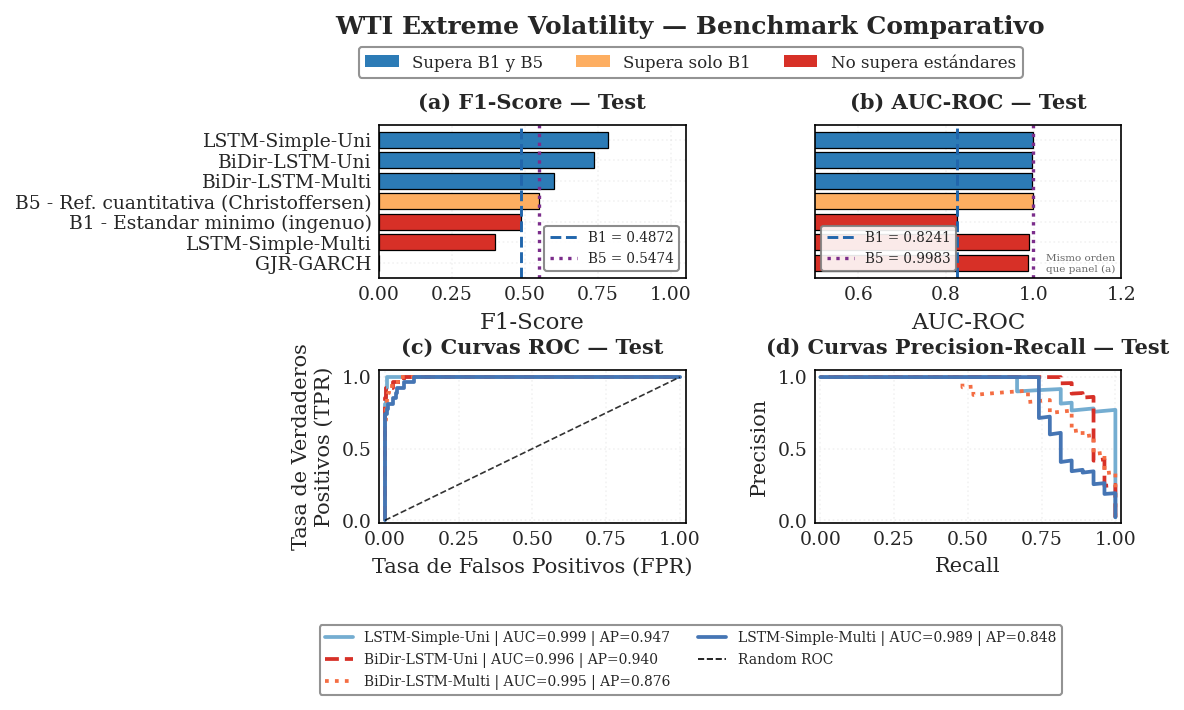

Figura guardada: fig_benchmark_comparacion.png


In [62]:
fig = plt.figure(figsize=fig_size("2x2"))
gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.60, wspace=0.42)

ax_f1  = fig.add_subplot(gs[0, 0])
ax_auc = fig.add_subplot(gs[0, 1])
ax_roc = fig.add_subplot(gs[1, 0])
ax_pr  = fig.add_subplot(gs[1, 1])

#  Filtrar solo modelos reales del benchmark
_rows_excluir = {
    'B1 — Estándar mínimo (ingenuo)',
    'B5 — Ref. cuantitativa (Christoffersen)',
}

bench_plot = (
    bench_test
    .dropna(subset=['f1', 'auc'])
    .loc[lambda df: ~df['nombre'].isin(_rows_excluir)]
    .copy()
)

_modelos_extra = config.get('nb02_results', {}).get(
    'modelos_extra_fuera_hipotesis', {}
).get('nombres', [])
if _modelos_extra:
    bench_plot = bench_plot[~bench_plot['nombre'].isin(_modelos_extra)].copy()

bench_plot = bench_plot.sort_values(['f1', 'auc'], ascending=[False, False]).reset_index(drop=True)

display_alias = {
    'GARCH-GJR-GARCH': 'GJR-GARCH',
    'LSTM-Simple-Uni': 'LSTM-Simple-Uni',
    'BiDir-LSTM-Uni': 'BiDir-LSTM-Uni',
    'LSTM-Simple-Multi': 'LSTM-Simple-Multi',
    'BiDir-LSTM-Multi': 'BiDir-LSTM-Multi',
    'Hybrid-LSTM-Sentimiento': 'Hybrid-Sent',
    'Hybrid-LSTM-MktSignals': 'Hybrid-MktSignals',
    'BiDir-GRU-Uni': 'BiDir-GRU-Uni',
}

models_p = bench_plot['nombre'].tolist()
labels_p = [display_alias.get(m, m) for m in models_p]
f1s_p    = bench_plot['f1'].tolist()
aucs_p   = bench_plot['auc'].tolist()

_beats_ing = (
    bench_plot['Beats_Ingenuo'].tolist()
    if 'Beats_Ingenuo' in bench_plot.columns else [False] * len(bench_plot)
)
_beats_cuan = (
    bench_plot['Beats_Cuant'].tolist()
    if 'Beats_Cuant' in bench_plot.columns else [False] * len(bench_plot)
)

beat_colors = []
for b_ing, b_cua in zip(_beats_ing, _beats_cuan):
    if b_cua:
        beat_colors.append(COLOR_VOL)
    elif b_ing:
        beat_colors.append(COLORS_P[90])
    else:
        beat_colors.append(COLOR_EXTREMO)

y_pos = np.arange(len(models_p))

#  (a) F1
ax_f1.barh(
    y_pos, f1s_p,
    color=beat_colors,
    edgecolor='black',
    linewidth=0.6
)
ax_f1.axvline(F1_MINIMO, color=COLORES_B[1], ls='--', lw=1.4)
ax_f1.axvline(F1_CUANT_TEST, color=COLORES_B[5], ls=':', lw=1.6)

ax_f1.set_title('(a) F1-Score — Test', fontweight='bold', fontsize=10, pad=8)
ax_f1.set_xlabel('F1-Score')
ax_f1.set_yticks(y_pos)
ax_f1.set_yticklabels(labels_p, fontsize=8)
ax_f1.set_xlim(0, 1.05)
ax_f1.invert_yaxis()
ax_f1.grid(axis='x', alpha=0.25)

# pequeña leyenda solo para líneas de referencia
ref_handles_f1 = [
    Line2D([0], [0], color=COLORES_B[1], lw=1.4, ls='--', label=f'B1 = {F1_MINIMO:.4f}'),
    Line2D([0], [0], color=COLORES_B[5], lw=1.6, ls=':',  label=f'B5 = {F1_CUANT_TEST:.4f}')
]
ax_f1.legend(handles=ref_handles_f1, loc='lower right', fontsize=6.5, frameon=True, framealpha=0.90)

#  (b) AUC
ax_auc.barh(
    y_pos, aucs_p,
    color=beat_colors,
    edgecolor='black',
    linewidth=0.6
)
ax_auc.axvline(AUC_MINIMO, color=COLORES_B[1], ls='--', lw=1.4)
ax_auc.axvline(AUC_CUANT_TEST, color=COLORES_B[5], ls=':', lw=1.6)

ax_auc.set_title('(b) AUC-ROC — Test', fontweight='bold', fontsize=10, pad=8)
ax_auc.set_xlabel('AUC-ROC')
ax_auc.set_yticks(y_pos)
ax_auc.set_yticklabels([])
ax_auc.set_xlim(0.5, 1.2)
ax_auc.invert_yaxis()
ax_auc.grid(axis='x', alpha=0.25)

ref_handles_auc = [
    Line2D([0], [0], color=COLORES_B[1], lw=1.4, ls='--', label=f'B1 = {AUC_MINIMO:.4f}'),
    Line2D([0], [0], color=COLORES_B[5], lw=1.6, ls=':',  label=f'B5 = {AUC_CUANT_TEST:.4f}')
]
ax_auc.legend(handles=ref_handles_auc, loc='lower left', fontsize=6.5, frameon=True, framealpha=0.90)

ax_auc.text(
    0.98, 0.03,
    'Mismo orden\nque panel (a)',
    transform=ax_auc.transAxes,
    ha='right', va='bottom',
    fontsize=5, color='dimgray'
)

#  Curvas ROC / PR: solo benchmark oficial
line_styles = ['-', '--', ':', '-.', (0, (3, 1, 1, 1))]
color_alias = {
    'GARCH-GJR-GARCH': COLORES_MODELOS.get('GARCH', COLORS_P[99]),
    'LSTM-Simple-Uni': COLORES_MODELOS.get('LSTM-Simple-Uni', COLOR_VAR),
    'LSTM-Simple-Multi': COLORES_MODELOS.get('LSTM-Simple-Multi', COLOR_VOL),
    'BiDir-LSTM-Uni': COLORES_MODELOS.get('BiDir-LSTM-Uni', COLOR_EXTREMO),
    'BiDir-LSTM-Multi': COLORES_MODELOS.get('BiDir-LSTM-Multi', COLOR_DYN),
    'Hybrid-LSTM-Sentimiento': COLORES_MODELOS.get('Hybrid-Sent', COLORS_P[90]),
    'Hybrid-LSTM-MktSignals': COLORES_MODELOS.get('Hybrid-MktSignals', COLOR_CLEAN),
    'BiDir-GRU-Uni': COLOR_VAR,
}

shared_handles = []

for i, model_name in enumerate(models_p):
    key = f'{model_name}_test'
    if key not in Y_SCORES:
        continue

    yt, ys = Y_SCORES[key]
    try:
        fpr, tpr, _ = roc_curve(yt, ys)
        prec, rec, _ = precision_recall_curve(yt, ys)
        auc_v = roc_auc_score(yt, ys)
        ap_v  = average_precision_score(yt, ys)
    except Exception:
        continue

    ls = line_styles[i % len(line_styles)]
    lbl = display_alias.get(model_name, model_name)
    col = color_alias.get(model_name, COLOR_VAR)

    ax_roc.plot(fpr, tpr, ls=ls, lw=1.8, color=col)
    ax_pr.plot(rec, prec, ls=ls, lw=1.8, color=col)

    shared_handles.append(
        Line2D([0], [0], color=col, lw=1.8, ls=ls,
               label=f'{lbl} | AUC={auc_v:.3f} | AP={ap_v:.3f}')
    )

ax_roc.plot([0, 1], [0, 1], 'k--', lw=0.8, alpha=0.8)
shared_handles.append(
    Line2D([0], [0], color='black', lw=0.8, ls='--', label='Random ROC')
)

ax_roc.set_title('(c) Curvas ROC — Test', fontweight='bold', fontsize=10, pad=8)
ax_roc.set_xlabel('Tasa de Falsos Positivos (FPR)', fontsize=10)
ax_roc.set_ylabel('Tasa de Verdaderos\nPositivos (TPR)', fontsize=10)
ax_roc.set_xlim(-0.02, 1.02)
ax_roc.set_ylim(-0.02, 1.05)

ax_pr.set_title('(d) Curvas Precision-Recall — Test', fontweight='bold', fontsize=10, pad=8)
ax_pr.set_xlabel('Recall', fontsize=10)
ax_pr.set_ylabel('Precision', fontsize=10)
ax_pr.set_xlim(-0.02, 1.02)
ax_pr.set_ylim(-0.02, 1.05)

for ax in [ax_f1, ax_auc, ax_roc, ax_pr]:
    ax.tick_params(axis='both', labelsize=9)
    ax.grid(alpha=0.25)

#  Leyenda global de colores de benchmark
legend_elements = [
    Patch(facecolor=COLOR_VOL, label='Supera B1 y B5'),
    Patch(facecolor=COLORS_P[90], label='Supera solo B1'),
    Patch(facecolor=COLOR_EXTREMO, label='No supera estándares'),
]
fig.legend(
    handles=legend_elements,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.955),
    ncol=3,
    fontsize=8,
    frameon=True
)

#  Leyenda global compartida ROC/PR
fig.legend(
    handles=shared_handles,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.01),
    ncol=2,
    fontsize=6.7,
    frameon=True
)

fig.suptitle('WTI Extreme Volatility — Benchmark Comparativo',
    fontweight='bold',fontsize=12, y=0.99)

fig.subplots_adjust(top=0.83,bottom=0.25,
    left=0.16, right=0.97,
    hspace=0.60, wspace=0.42)

save_fig(fig, 'fig_benchmark_comparacion', output_path=FIG_PATH, dpi=300)
plt.show()
plt.close()
print("Figura guardada: fig_benchmark_comparacion.png")


**Figura: trade-off de umbral en test**

- **Qué**: barrido descriptivo de F1 y curva Precision-Recall para los LSTM sobre test.
- **Cómo**: usa scores ya generados en `Y_SCORES`; el umbral operativo sigue siendo el fijado en validación.
- **Por qué importa**: muestra el costo de bajar o subir el umbral sin redefinir el benchmark canónico.
- **Nota**: es un análisis post-hoc descriptivo; no se usa para re-seleccionar el modelo ganador.


  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB02_Benchmark/Fig_NB02/fig_threshold_tradeoff.png  [6.1"×3.1" @ 300dpi]


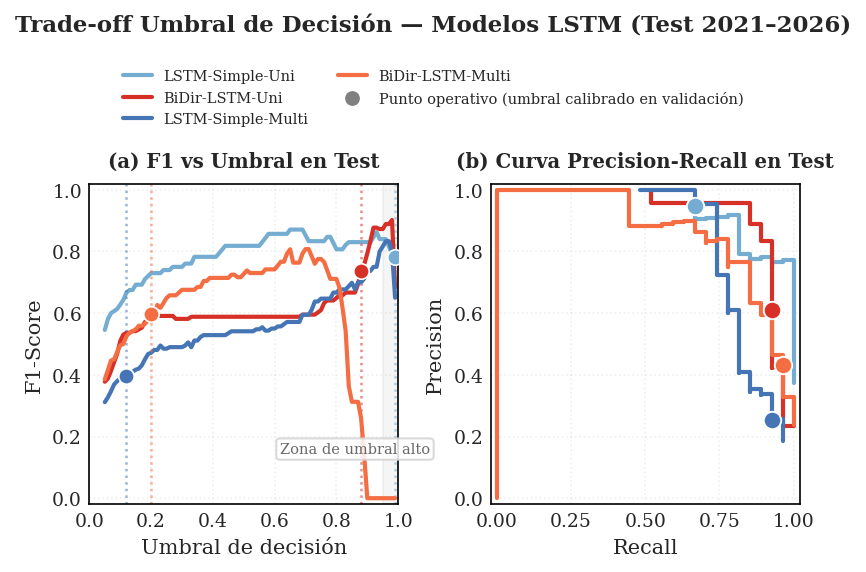

Figura guardada: fig_threshold_tradeoff.png


In [63]:
#  6.x Análisis del trade-off Precision/Recall vs Umbral
# Propósito: Precision=1.0 en test con thr=0.98-0.99 no es un error,
# sino una consecuencia del umbral alto fijado en validación.
# IMPORTANTE: el barrido es descriptivo sobre TEST. NO reselecciona el benchmark.

modelos_umbral = {}
for arch_name, data in {**results_lstm_uni, **results_lstm_multi}.items():
    key_test = f"{arch_name}_test"
    if key_test in Y_SCORES:
        modelos_umbral[arch_name] = {
            'yt': Y_SCORES[key_test][0],
            'ys': Y_SCORES[key_test][1],
            'thr_val': data['threshold']
        }

if not modelos_umbral:
    print('No hay scores LSTM en Y_SCORES — ejecutar Partes III y IV primero.')
else:
    fig, axes = plt.subplots(1, 2, figsize=fig_size('2x1'))
    fig.suptitle(
        'Trade-off Umbral de Decisión — Modelos LSTM (Test 2021–2026)',
        fontweight='bold', fontsize=11, y=1.19
    )

    colors_map = {
        'BiDir-LSTM-Uni':    COLORES_MODELOS.get('BiDir-LSTM-Uni', 'navy'),
        'LSTM-Simple-Uni':   COLORES_MODELOS.get('LSTM-Simple-Uni', 'steelblue'),
        'BiDir-LSTM-Multi':  COLORES_MODELOS.get('BiDir-LSTM-Multi', '#8B2020'),
        'LSTM-Simple-Multi': COLORES_MODELOS.get('LSTM-Simple-Multi', '#B8690F'),
    }

    thresholds_grid = np.arange(0.05, 0.995, 0.01)
    summary = {}

    for arch_name, datos in modelos_umbral.items():
        yt = datos['yt'].astype(int)
        ys = datos['ys']
        thr_val = datos['thr_val']
        color = colors_map.get(arch_name, 'gray')

        rows = []
        for thr in thresholds_grid:
            yp = (ys >= thr).astype(int)
            rows.append({
                'thr': thr,
                'f1': f1_score(yt, yp, zero_division=0),
                'precision': precision_score(yt, yp, zero_division=0),
                'recall': recall_score(yt, yp, zero_division=0),
            })

        df_thr = pd.DataFrame(rows)
        idx_op = (df_thr['thr'] - thr_val).abs().idxmin()

        summary[arch_name] = {
            'color': color,
            'df': df_thr,
            'thr_val': thr_val,
            'f1_op': float(df_thr.loc[idx_op, 'f1']),
            'prec_op': float(df_thr.loc[idx_op, 'precision']),
            'rec_op': float(df_thr.loc[idx_op, 'recall']),
        }

    # Panel (a): F1 vs umbral
    for arch_name, s in summary.items():
        axes[0].plot(
            s['df']['thr'], s['df']['f1'],
            color=s['color'], lw=2, label=arch_name
        )
        axes[0].axvline(
            s['thr_val'], color=s['color'],
            ls=':', lw=1.2, alpha=0.55
        )
        axes[0].scatter(
            [s['thr_val']], [s['f1_op']],
            color=s['color'], s=55, zorder=5,
            edgecolor='white', linewidth=0.8
        )

    axes[0].axvspan(0.95, 1.00, alpha=0.08, color='gray')
    axes[0].text(
        0.86, 0.16,
        'Zona de umbral alto',
        transform=axes[0].transAxes,
        fontsize=7, color='dimgray', ha='center',
        bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='lightgray', alpha=0.85)
    )

    axes[0].set_title('(a) F1 vs Umbral en Test', fontweight='bold', fontsize=9.5, pad=8)
    axes[0].set_xlabel('Umbral de decisión', fontsize=10)
    axes[0].set_ylabel('F1-Score', fontsize=10)
    axes[0].set_xlim(0, 1)
    axes[0].set_ylim(-0.02, 1.02)
    axes[0].grid(alpha=0.30, linestyle=':')

    # Panel (b): Precision-Recall
    for arch_name, s in summary.items():
        axes[1].step(
            s['df']['recall'], s['df']['precision'],
            where='post', color=s['color'], lw=2
        )
        axes[1].scatter(
            [s['rec_op']], [s['prec_op']],
            color=s['color'], s=70, zorder=6,
            edgecolor='white', linewidth=0.9
        )

    axes[1].set_title('(b) Curva Precision-Recall en Test', fontweight='bold', fontsize=9.5, pad=8)
    axes[1].set_xlabel('Recall', fontsize=10)
    axes[1].set_ylabel('Precision', fontsize=10)
    axes[1].set_xlim(-0.02, 1.02)
    axes[1].set_ylim(-0.02, 1.02)
    axes[1].grid(alpha=0.30, linestyle=':')

    # Leyenda global: líneas = modelo, círculos = punto operativo
    model_handles = [
        Line2D([0], [0], color=s['color'], lw=2, label=arch_name)
        for arch_name, s in summary.items()
    ]
    marker_handle = Line2D(
        [0], [0], marker='o', linestyle='None',
        markerfacecolor='gray', markeredgecolor='white',
        markeredgewidth=0.9, markersize=8,
        label='Punto operativo (umbral calibrado en validación)'
    )

    fig.legend(
        handles=model_handles + [marker_handle],
        loc='upper center',
        bbox_to_anchor=(0.5, 1.098),
        ncol=2,
        fontsize=7,
        frameon=False
    )

    fig.subplots_adjust(top=0.82, bottom=0.12, wspace=0.30)

    save_fig(fig, 'fig_threshold_tradeoff', output_path=FIG_PATH)
    plt.show()
    plt.close()
    print('Figura guardada: fig_threshold_tradeoff.png')


Los puntos marcados corresponden al threshold calibrado en validation para cada modelo.

**Qué muestra**  
Esta figura resume el benchmark principal mediante barras de F1 y AUC-ROC, junto con curvas ROC y Precision-Recall en test. Reúne en una sola vista el posicionamiento relativo de las arquitecturas evaluadas.

**Cómo se construye**  
Se construye a partir de las métricas consolidadas del benchmark y de los scores almacenados para cada modelo sobre test. Los colores distinguen el grado en que cada arquitectura supera los estándares de referencia definidos en la tesis.

**Por qué se ve así**  
Las diferencias de altura y curvatura reflejan capacidades distintas de discriminación y de balance entre errores. La semántica cromática permite separar visualmente modelos que superan ambos baselines, solo uno o ninguno.

**Por qué es importante**  
Esta figura actúa como síntesis visual del benchmark canónico de NB02. También facilita comunicar de forma compacta qué familias de modelos aportan mejoras sustantivas y cuáles no.

In [64]:
def diebold_mariano_test(e1, e2, h=1, crit='MSE'):
    e1, e2 = np.asarray(e1), np.asarray(e2)
    if crit == 'MSE':
        d = e1**2 - e2**2
    elif crit == 'MAE':
        d = np.abs(e1) - np.abs(e2)
    else:
        raise ValueError("crit debe ser 'MSE' o 'MAE'")
    n = len(d)
    d_bar = d.mean()
    gamma0 = np.var(d, ddof=0)
    gamma = sum(2 * np.mean((d[k:] - d_bar) * (d[:-k] - d_bar)) for k in range(1, h)) if h > 1 else 0
    var_d = (gamma0 + gamma) / n
    if var_d <= 0:
        return np.nan, np.nan
    dm_stat = d_bar / np.sqrt(var_d)
    p_value = 2 * (1 - stats.norm.cdf(abs(dm_stat)))
    return float(dm_stat), float(p_value)

test_long = collect_model_outputs()
test_models = sorted(test_long.loc[test_long['split'].eq('test'), 'model_name'].unique())
lstm_models_dm = [m for m in test_models if 'LSTM' in m and 'Hybrid' not in m]

if len(lstm_models_dm) >= 2:
    print("DM Test intra-familia LSTM (test, scores 0-1)")
    print(f"{'Modelo 1':25s} {'Modelo 2':25s} {'n_common':>8} {'DM stat':>9} {'p-value':>9} Signif.")
    print("-" * 92)
    for i in range(len(lstm_models_dm)):
        for j in range(i + 1, len(lstm_models_dm)):
            n1, n2 = lstm_models_dm[i], lstm_models_dm[j]
            aligned = align_model_outputs(n1, n2, split='test')
            if aligned.empty:
                continue
            e1 = aligned['y_true'].astype(float) - aligned['y_score_left']
            e2 = aligned['y_true'].astype(float) - aligned['y_score_right']
            dm, p = diebold_mariano_test(e1, e2, h=1, crit='MSE')
            sig = '***' if p < 0.01 else ('**' if p < 0.05 else ('*' if p < 0.10 else ''))
            print(f"{n1:25s} {n2:25s} {len(aligned):8d} {dm:9.4f} {p:9.4f} {sig}")
    print()

if len(test_models) >= 2:
    print("DM Test cross-familia (scores normalizados [0,1])")
    print(f"{'Modelo 1':25s} {'Modelo 2':25s} {'n_common':>8} {'DM stat':>9} {'p-value':>9} Signif.")
    print("-" * 92)
    for i in range(len(test_models)):
        for j in range(i + 1, len(test_models)):
            n1, n2 = test_models[i], test_models[j]
            aligned = align_model_outputs(n1, n2, split='test')
            if aligned.empty:
                continue
            e1 = aligned['y_true'].astype(float) - normalize_scores_minmax(aligned['y_score_left'])
            e2 = aligned['y_true'].astype(float) - normalize_scores_minmax(aligned['y_score_right'])
            dm, p = diebold_mariano_test(e1, e2, h=1, crit='MSE')
            sig = '***' if p < 0.01 else ('**' if p < 0.05 else ('*' if p < 0.10 else ''))
            print(f"{n1:25s} {n2:25s} {len(aligned):8d} {dm:9.4f} {p:9.4f} {sig}")
else:
    print("Insuficientes modelos para DM test (se necesitan >= 2).")

DM Test intra-familia LSTM (test, scores 0-1)
Modelo 1                  Modelo 2                  n_common   DM stat   p-value Signif.
--------------------------------------------------------------------------------------------
BiDir-LSTM-Multi          BiDir-LSTM-Uni                1180   -3.8104    0.0001 ***
BiDir-LSTM-Multi          LSTM-Simple-Multi             1180   -5.9566    0.0000 ***
BiDir-LSTM-Multi          LSTM-Simple-Uni               1180    1.7016    0.0888 *
BiDir-LSTM-Uni            LSTM-Simple-Multi             1180   -0.1821    0.8555 
BiDir-LSTM-Uni            LSTM-Simple-Uni               1275    3.7033    0.0002 ***
LSTM-Simple-Multi         LSTM-Simple-Uni               1180    4.6777    0.0000 ***

DM Test cross-familia (scores normalizados [0,1])
Modelo 1                  Modelo 2                  n_common   DM stat   p-value Signif.
--------------------------------------------------------------------------------------------
BiDir-GRU-Uni             BiDir-LS

In [65]:
from statsmodels.stats.contingency_tables import mcnemar as mcnemar_test

def run_mcnemar_pair(yt, yp1, yp2, name1, name2, n_common):
    b = int(np.sum((yt == yp1) & (yt != yp2)))
    c = int(np.sum((yt != yp1) & (yt == yp2)))
    if b + c == 0:
        print(f"  {name1} vs {name2}: sin discordancias - test no aplicable (n_common={n_common}).")
        return None
    exact = min(b, c) < 25
    table = np.array([[0, b], [c, 0]])
    result = mcnemar_test(table, exact=exact)
    sig = '***' if result.pvalue < 0.01 else ('**' if result.pvalue < 0.05 else ('*' if result.pvalue < 0.10 else ''))
    print(f"  {name1:25s} vs {name2:25s} | n={n_common:4d} | b={b:3d} c={c:3d} | p={result.pvalue:.4f} {sig} | {'exact' if exact else 'chi2'}")
    return result

all_thresholds = {}
all_thresholds.update(OPTIMAL_THRESHOLDS)
all_thresholds.update(OPTIMAL_THRESHOLDS_COMPL)
print("Umbrales optimizados por modelo")
for name, thr in sorted(all_thresholds.items()):
    print(f"  {name:25s}: {thr:.4f}")
print()

test_long = collect_model_outputs()
test_models = sorted(test_long.loc[test_long['split'].eq('test'), 'model_name'].unique())
if len(test_models) >= 2:
    print("McNemar Test (pares, test, alineacion por target_date)")
    for i in range(len(test_models)):
        for j in range(i + 1, len(test_models)):
            n1, n2 = test_models[i], test_models[j]
            aligned = align_model_outputs(n1, n2, split='test')
            if aligned.empty:
                continue
            run_mcnemar_pair(aligned['y_true'].astype(int).values, aligned['y_pred_left'].astype(int).values, aligned['y_pred_right'].astype(int).values, n1, n2, len(aligned))
else:
    print("Insuficientes modelos para McNemar (se necesitan >= 2).")

Umbrales optimizados por modelo
  BiDir-GRU-Uni            : 0.9800
  BiDir-LSTM-Multi         : 0.2000
  BiDir-LSTM-Uni           : 0.8800
  GARCH                    : 7.1193
  GARCH-GJR-GARCH          : 7.1193
  GRU-Simple-Uni           : 0.8200
  LSTM-Simple-Multi        : 0.1200
  LSTM-Simple-Uni          : 0.9900
  TCN-Uni                  : 0.8100
  XGBoost-Tabular          : 0.4500

McNemar Test (pares, test, alineacion por target_date)
  BiDir-GRU-Uni             vs BiDir-LSTM-Multi          | n=1180 | b= 34 c=  6 | p=0.0000 *** | exact
  BiDir-GRU-Uni             vs BiDir-LSTM-Uni            | n=1275 | b= 16 c=  5 | p=0.0266 ** | exact
  BiDir-GRU-Uni             vs GARCH-GJR-GARCH           | n=1275 | b= 21 c=  1 | p=0.0000 *** | exact
  BiDir-GRU-Uni             vs GRU-Simple-Uni            | n=1275 | b=  5 c=  6 | p=1.0000  | exact
  BiDir-GRU-Uni             vs LSTM-Simple-Multi         | n=1180 | b= 74 c=  5 | p=0.0000 *** | exact
  BiDir-GRU-Uni             vs LSTM-Simpl

Modelo ganador (F1 test): LSTM-Simple-Uni
Umbral de decisión: 0.9900  (desde OPTIMAL_THRESHOLDS)

Confusión en test:
  TP=18  FP=1  FN=9  TN=1247
  Detectados: 18/27 extremos (66.7% recall)
  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB02_Benchmark/Fig_NB02/fig_error_analysis.png  [6.1"×8.3" @ 300dpi]


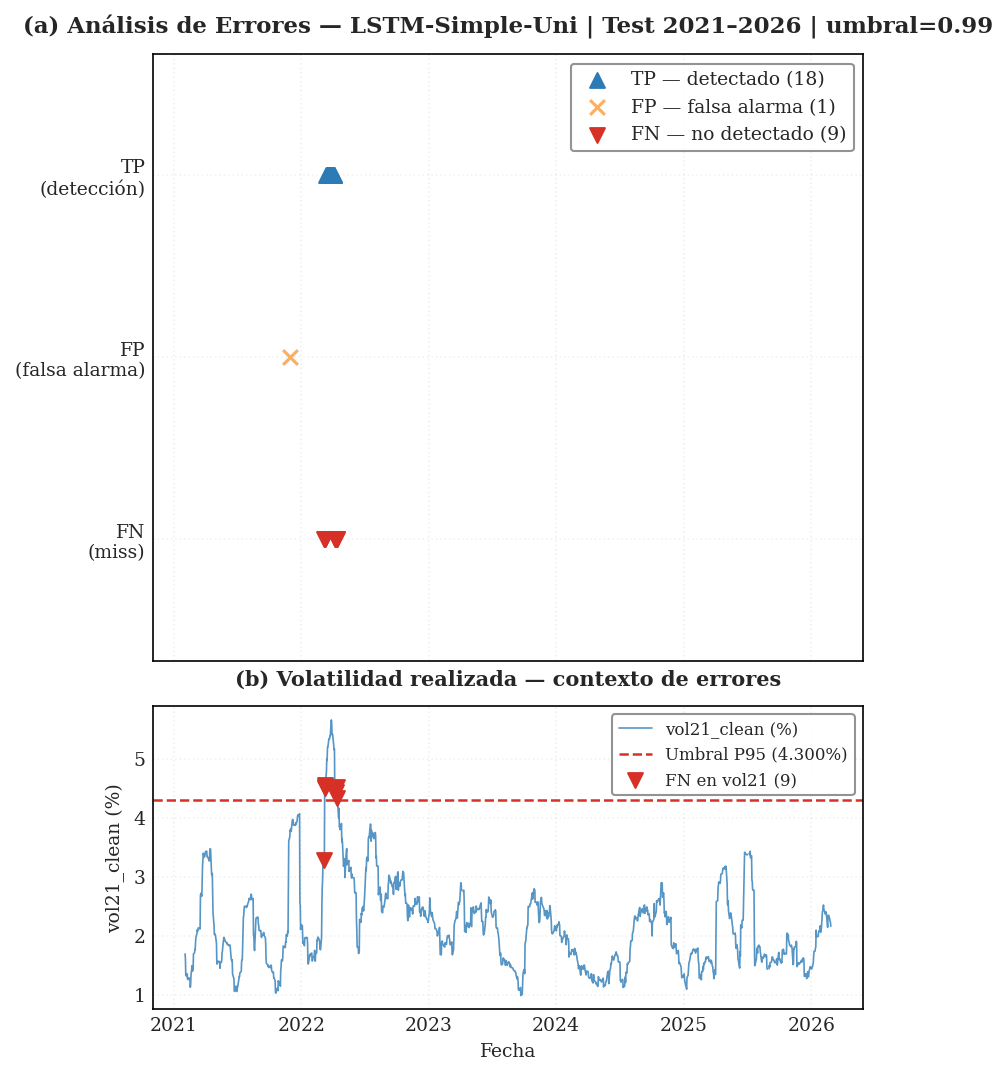

Figura guardada: fig_error_analysis.png

FN detalle (9 eventos no detectados):
               vol21_clean_%  y_score_modelo
decision_date                               
2022-03-08          3.275800        0.699900
2022-03-09          4.510600        0.934200
2022-03-10          4.522000        0.978700
2022-03-11          4.546900        0.984800
2022-04-07          4.411000        0.969400
2022-04-08          4.431400        0.836200
2022-04-11          4.430700        0.703700
2022-04-12          4.523700        0.784800
2022-04-13          4.335500        0.797500

  → Score promedio en FN: 0.8544 (umbral=0.9900)
  → Vol21 promedio en FN: 4.3320%


In [66]:
#  6.5 Análisis de errores — timeline FP/FN ─
# Modelo ganador según benchmark (primer lugar en F1 test)

if bench_test.empty:
    print("bench_test vacío — ejecutar Cell 6.1 primero.")
else:
    # Excluir modelos_extra_fuera_hipotesis antes de seleccionar ganador
    _modelos_extra = config.get('nb02_results', {}).get(
        'modelos_extra_fuera_hipotesis', {}).get('nombres', [])
    _bench_hip = bench_test[~bench_test['nombre'].isin(_modelos_extra)]
    best_model_name = (
        _bench_hip.iloc[0] if not _bench_hip.empty else bench_test.iloc[0]
    )['nombre']
    print(f"Modelo ganador (F1 test): {best_model_name}")

    #  Buscar scores en Y_SCORES usando clave exacta
    # Construir clave directa: evita split('-') frágil que matchea
    # parcialmente (ej: 'BiDir' matchea BiDir-Uni y BiDir-Multi)
    key_best = f"{best_model_name}_test"

    # Fallback: buscar clave que contenga el nombre completo
    if key_best not in Y_SCORES:
        key_best = next(
            (k for k in Y_SCORES if 'test' in k and best_model_name in k),
            None
        )

    if key_best is None or key_best not in Y_SCORES:
        print(f"No se encontraron scores de '{best_model_name}' en Y_SCORES.")
        print(f"Claves disponibles: {list(Y_SCORES.keys())}")
    else:
        yt_best, ys_best = Y_SCORES[key_best]

        #  Recuperar umbral desde OPTIMAL_THRESHOLDS (Cell 62)
        # OPTIMAL_THRESHOLDS fue construido con el umbral correcto por modelo.
        # Fallback a 0.5 solo si el modelo no está registrado.
        thr_best = OPTIMAL_THRESHOLDS.get(best_model_name, 0.5)
        print(f"Umbral de decisión: {thr_best:.4f}  "
              f"({'desde OPTIMAL_THRESHOLDS' if best_model_name in OPTIMAL_THRESHOLDS else 'fallback 0.5'})")

        # GARCH usa > estrictamente, LSTMs usan >=
        if 'GARCH' in best_model_name:
            yp_best = (ys_best > thr_best).astype(int)
        else:
            yp_best = (ys_best >= thr_best).astype(int)

        #  Construir DataFrame de errores
        # idx_test_uni == idx_test_multi por construcción (Cell 21):
        # ambos usan df_test.index después del mismo dropna(FEATURES_MULTI)
        idx_plot = idx_test_uni

        if len(idx_plot) != len(yt_best):
            print(f"Desajuste de índice: idx_plot={len(idx_plot)} "
                  f"vs yt_best={len(yt_best)} — omitiendo figura.")
        else:
            df_errors = pd.DataFrame({
                'y_true': yt_best,
                'y_pred': yp_best,
                'y_score': ys_best,
                'FP': (yp_best == 1) & (yt_best == 0),
                'FN': (yp_best == 0) & (yt_best == 1),
                'TP': (yp_best == 1) & (yt_best == 1),
                'TN': (yp_best == 0) & (yt_best == 0),
            }, index=idx_plot)

            n_tp = df_errors['TP'].sum()
            n_fp = df_errors['FP'].sum()
            n_fn = df_errors['FN'].sum()
            n_total_pos = int(yt_best.sum())

            print(f"\nConfusión en test:")
            print(f"  TP={n_tp}  FP={n_fp}  FN={n_fn}  "
                  f"TN={df_errors['TN'].sum()}")
            print(f"  Detectados: {n_tp}/{n_total_pos} extremos "
                  f"({n_tp/n_total_pos*100:.1f}% recall)")

            #  Figura: timeline FP/FN + vol21_clean overlay
            fig, (ax_err, ax_vol) = plt.subplots(
                2, 1, figsize=fig_size("tall"), sharex=True,
                gridspec_kw={'height_ratios': [2, 1], 'hspace': 0.1}
            )

            # Panel superior: errores
            ax_err.scatter(
                df_errors.index[df_errors['TP']], [0.8]*n_tp,
                marker='^', color=COLOR_VOL, s=50, zorder=4,
                label=f"TP — detectado ({n_tp})")
            ax_err.scatter(
                df_errors.index[df_errors['FP']], [0.5]*n_fp,
                marker='x', color=COLORS_P[90], s=50, zorder=4, linewidths=1.5,
                label=f"FP — falsa alarma ({n_fp})")
            ax_err.scatter(
                df_errors.index[df_errors['FN']], [0.2]*n_fn,
                marker='v', color=COLOR_EXTREMO, s=50, zorder=4,
                label=f"FN — no detectado ({n_fn})")

            add_crisis_zones(ax_err,
                             xlim=(df_errors.index.min(), df_errors.index.max()))
            ax_err.set_yticks([0.2, 0.5, 0.8])
            ax_err.set_yticklabels(['FN\n(miss)', 'FP\n(falsa alarma)', 'TP\n(detección)'],
                                    fontsize=9)
            ax_err.set_ylim(0, 1)
            ax_err.set_title(
                f"(a) Análisis de Errores — {best_model_name} | Test 2021–2026 "
                f"| umbral={thr_best:.2f}",
                fontweight='bold')
            ax_err.legend(loc='upper right', fontsize=9)
            ax_err.grid(axis='x', alpha=0.3, linestyle=':')

            # Panel inferior: vol21_clean para contextualizar errores
            vol_test = df_test['vol21_clean'].reindex(idx_plot)
            ax_vol.plot(idx_plot, vol_test * 100, color=COLOR_VOL,
                        lw=0.8, alpha=0.8, label='vol21_clean (%)')
            ax_vol.axhline(UMBRAL_CLASIFICACION * 100, color=COLOR_EXTREMO,
                           ls='--', lw=1.2,
                           label=f'Umbral P95 ({UMBRAL_CLASIFICACION*100:.3f}%)')

            # Marcar FN sobre la curva de volatilidad
            fn_dates = df_errors.index[df_errors['FN']]
            fn_vols  = vol_test.reindex(fn_dates)
            ax_vol.scatter(fn_dates, fn_vols * 100,
                           marker='v', color=COLOR_EXTREMO, s=50, zorder=4,
                           label=f'FN en vol21 ({n_fn})')

            add_crisis_zones(ax_vol,
                             xlim=(df_errors.index.min(), df_errors.index.max()))
            ax_vol.set_ylabel('vol21_clean (%)', fontsize=9)
            ax_vol.set_xlabel('Fecha', fontsize=9)
            ax_vol.legend(fontsize=8, loc='upper right')
            ax_vol.set_title('(b) Volatilidad realizada — contexto de errores',
                             fontweight='bold', fontsize=10)
            ax_vol.grid(axis='x', alpha=0.3, linestyle=':')

            save_fig(fig, 'fig_error_analysis', output_path=FIG_PATH, dpi=300)

            plt.show()
            plt.close()
            print("Figura guardada: fig_error_analysis.png")

            #  Tabla de FN: qué días extremos no se detectaron
            if n_fn > 0:
                fn_detail = df_errors[df_errors['FN']].copy()
                fn_detail['vol21_clean_%'] = (
                    vol_test.reindex(fn_detail.index) * 100).round(4)
                fn_detail['y_score_modelo'] = fn_detail['y_score'].round(4)
                print(f"\nFN detalle ({n_fn} eventos no detectados):")
                print(fn_detail[['vol21_clean_%', 'y_score_modelo']].to_string())
                print(f"\n  → Score promedio en FN: "
                      f"{fn_detail['y_score_modelo'].mean():.4f} "
                      f"(umbral={thr_best:.4f})")
                print(f"  → Vol21 promedio en FN: "
                      f"{fn_detail['vol21_clean_%'].mean():.4f}%")

### Análisis de sensibilidad al umbral:
Cada benchmark se evalúa perturbando el umbral de su propia señal:
 - B1 usa p95_absret, calibrado sobre |ret_lag1|
 - GARCH usa SIGMA_UMBRAL_PCT, calibrado sobre sigma pronosticada
Esto evita mezclar variables con escalas distintas y hace que la sensibilidad al umbral sea internamente consistente para cada modelo.

In [67]:
# 6.6 Análisis de sensibilidad al umbral
# Dos análisis separados, cada uno con el umbral propio de su feature

# Recalcular p95_absret si no existe en memoria
if 'p95_absret' not in globals():
    _train_mask_xgb = (df['split'] == 'train') & (~df['bad_vol21'])
    p95_absret = df.loc[_train_mask_xgb, 'ret_abs_lag1'].quantile(0.95)
    print(f"p95_absret recalculado en train: {p95_absret:.6f}")

# A) Sensibilidad del umbral B1 (|ret_abs_lag1| vs p95_absret)
print("Sensibilidad B1 — umbral propio (p95_absret) ±15%")
print(f"Umbral base B1 (p95_absret): {p95_absret:.6f} ({p95_absret*100:.4f}%)")
print()

rows_b1 = []

ret_abs_val = df_val['ret_abs_lag1'].reindex(idx_val_uni).fillna(0)
ret_abs_test = df_test['ret_abs_lag1'].reindex(idx_test_uni).fillna(0)

for delta_pct in [-0.15, -0.10, -0.05, 0.0, 0.05, 0.10, 0.15]:
    new_thr = p95_absret * (1 + delta_pct)

    for split_name, ret_s, y_w in [
        ('val', ret_abs_val, yw_val_uni),
        ('test', ret_abs_test, yw_test_uni),
    ]:
        yp = (ret_s.values > new_thr).astype(int)

        f1 = f1_score(y_w.astype(int), yp, zero_division=0)
        pr = precision_score(y_w.astype(int), yp, zero_division=0)
        rc = recall_score(y_w.astype(int), yp, zero_division=0)

        rows_b1.append({
            'Δ%': f"{delta_pct:+.0%}",
            'Umbral': round(new_thr, 6),
            'Split': split_name,
            'F1': round(f1, 4),
            'Precision': round(pr, 4),
            'Recall': round(rc, 4),
        })

df_sens_b1 = pd.DataFrame(rows_b1)
print(df_sens_b1.to_string(index=False))

print()
print("Sensibilidad GARCH — umbral sigma (SIGMA_UMBRAL_PCT) ±15%")
print(f"Umbral base GARCH (sigma): {SIGMA_UMBRAL_PCT:.4f}%")
print()

# B) Sensibilidad del umbral GARCH (sigma vs SIGMA_UMBRAL_PCT)
rows_g = []

if 'GARCH_test' in Y_SCORES and 'GARCH_val' in Y_SCORES:
    yt_g_test, ys_g_test = Y_SCORES['GARCH_test']
    yt_g_val, ys_g_val = Y_SCORES['GARCH_val']

    for delta_pct in [-0.15, -0.10, -0.05, 0.0, 0.05, 0.10, 0.15]:
        new_thr = SIGMA_UMBRAL_PCT * (1 + delta_pct)

        for split_name, yt, ys in [
            ('val', yt_g_val, ys_g_val),
            ('test', yt_g_test, ys_g_test),
        ]:
            yp = (ys > new_thr).astype(int)

            f1 = f1_score(yt.astype(int), yp, zero_division=0)
            pr = precision_score(yt.astype(int), yp, zero_division=0)
            rc = recall_score(yt.astype(int), yp, zero_division=0)

            rows_g.append({
                'Δ%': f"{delta_pct:+.0%}",
                'Umbral': round(new_thr, 4),
                'Split': split_name,
                'F1': round(f1, 4),
                'Precision': round(pr, 4),
                'Recall': round(rc, 4),
            })

    df_sens_g = pd.DataFrame(rows_g)
    print(df_sens_g.to_string(index=False))
else:
    print("GARCH_val o GARCH_test no disponible en Y_SCORES — ejecutar la parte GARCH primero.")

print()
print("Nota: cada análisis usa el umbral de su propia feature.")
print("  B1     → perturba p95_absret         (escala |ret_abs_lag1|)")
print("  GARCH  → perturba SIGMA_UMBRAL_PCT   (escala sigma%)")
print("  No son intercambiables: features y escalas distintas.")

p95_absret recalculado en train: 0.046542
Sensibilidad B1 — umbral propio (p95_absret) ±15%
Umbral base B1 (p95_absret): 0.046542 (4.6542%)

  Δ%   Umbral Split       F1  Precision   Recall
-15% 0.039561   val 0.552600   0.446800 0.724100
-15% 0.039561  test 0.178900   0.114600 0.407400
-10% 0.041888   val 0.527800   0.441900 0.655200
-10% 0.041888  test 0.171400   0.115400 0.333300
 -5% 0.044215   val 0.575800   0.513500 0.655200
 -5% 0.044215  test 0.191500   0.134300 0.333300
 +0% 0.046542   val 0.562500   0.514300 0.620700
 +0% 0.046542  test 0.209300   0.152500 0.333300
 +5% 0.048869   val 0.580600   0.545500 0.620700
 +5% 0.048869  test 0.233800   0.180000 0.333300
+10% 0.051196   val 0.586200   0.586200 0.586200
+10% 0.051196  test 0.257100   0.209300 0.333300
+15% 0.053523   val 0.607100   0.629600 0.586200
+15% 0.053523  test 0.264700   0.219500 0.333300

Sensibilidad GARCH — umbral sigma (SIGMA_UMBRAL_PCT) ±15%
Umbral base GARCH (sigma): 0.9382%

  Δ%   Umbral Split       F1 

> **Dentro del benchmark canónico H0–H3, LSTM-Simple-Uni se mantiene como el modelo de referencia. No obstante, entre los modelos complementarios, XGBoost-Tabular mostró el mejor desempeño agregado y superó significativamente a la mayoría de arquitecturas en pruebas basadas en scores. Frente a LSTM-Simple-Uni, la ventaja de XGBoost-Tabular fue clara en métricas y en Diebold-Mariano, pero no alcanzó significancia al 5% en McNemar, por lo que esa superioridad operativa debe interpretarse con cautela.


---
## PARTE VII — Exportación de Resultados

Guardar todo lo necesario para reproducir y extender en NB03:
- Predicciones (CSV por modelo)
- Config actualizado (JSON)
- Modelos entrenados (pickle / .keras)
- Resumen ejecutivo


In [68]:
# 7.1 Guardar predicciones CSV por modelo
EXPORT_PRED_DIR = globals().get('PRED_DIR', f"{OUTPUT_PATH}/predicciones_nb02")
os.makedirs(EXPORT_PRED_DIR, exist_ok=True)
all_outputs = collect_model_outputs()

if all_outputs.empty:
    print("No hay MODEL_OUTPUTS para exportar.")
else:
    for (model_name, split_name), df_model in all_outputs.groupby(['model_name', 'split'], sort=True):
        df_pred = df_model[OUTPUT_COLUMNS].copy()
        df_pred['fecha'] = df_pred['decision_date']
        df_pred['modelo'] = df_pred['model_name']
        safe_name = model_name.replace('/', '-').replace(' ', '_')
        fname = f"{EXPORT_PRED_DIR}/pred_{safe_name}_{split_name}.csv"
        df_pred.to_csv(fname, index=False)
        print(f"  Guardado: pred_{safe_name}_{split_name}.csv ({len(df_pred)} filas)")

  Guardado: pred_BiDir-GRU-Uni_test.csv (1275 filas)
  Guardado: pred_BiDir-GRU-Uni_val.csv (441 filas)
  Guardado: pred_BiDir-LSTM-Multi_test.csv (1180 filas)
  Guardado: pred_BiDir-LSTM-Multi_val.csv (441 filas)
  Guardado: pred_BiDir-LSTM-Uni_test.csv (1275 filas)
  Guardado: pred_BiDir-LSTM-Uni_val.csv (441 filas)
  Guardado: pred_GARCH-GJR-GARCH_test.csv (1295 filas)
  Guardado: pred_GARCH-GJR-GARCH_val.csv (481 filas)
  Guardado: pred_GRU-Simple-Uni_test.csv (1275 filas)
  Guardado: pred_GRU-Simple-Uni_val.csv (441 filas)
  Guardado: pred_LSTM-Simple-Multi_test.csv (1180 filas)
  Guardado: pred_LSTM-Simple-Multi_val.csv (441 filas)
  Guardado: pred_LSTM-Simple-Uni_test.csv (1275 filas)
  Guardado: pred_LSTM-Simple-Uni_val.csv (441 filas)
  Guardado: pred_TCN-Uni_test.csv (1275 filas)
  Guardado: pred_TCN-Uni_val.csv (441 filas)
  Guardado: pred_XGBoost-Tabular_test.csv (1289 filas)
  Guardado: pred_XGBoost-Tabular_val.csv (460 filas)


In [69]:
# --- 7.2 Actualizar config_estudio_FINAL.json con resultados NB02
# POST-PROCESO -- escribe la SoT canónica del benchmark CPU.
# Este notebook consolida H0-H3 y solo actualiza nb02_results + nb02_metadata.
# La capa experimental GPU/Optuna vive en nb02_experiments y se preserva intacta.
WRITE_CONFIG = (RUN_MODE == 'canonical_cpu')
CPU_SOURCE_TAG = os.environ.get('NB02_CPU_SOURCE_TAG', 'NB02_CPU_CANONICAL')
CANONICAL_MODELS = [
    'GARCH-GJR-GARCH',
    'LSTM-Simple-Uni',
    'BiDir-LSTM-Uni',
    'LSTM-Simple-Multi',
    'BiDir-LSTM-Multi',
]
CANONICAL_BENCHMARK_PATHS = {
    'benchmark_predictions_csv': 'results/predictions/nb02/benchmark_predictions_NB02.csv',
}

if not WRITE_CONFIG:
    print("[SKIP] WRITE_CONFIG=False - nb02_results y nb02_metadata NO se modifican.")
    print(f"       RUN_MODE='{RUN_MODE}' (requerido: 'canonical_cpu')")
    print("       nb02_experiments, nb03 y nb03b se preservan intactos.")

if WRITE_CONFIG:
    with open(CONFIG_PATH, 'r', encoding='utf-8') as f:
        config_out = json.load(f)

    assert 'nb02' in config_out and 'fechas' in config_out, (
        'El config runtime no contiene la base metodológica esperada de NB01. '
        'Ejecutar NB01 antes del cierre canónico NB02 CPU.'
    )
    print('[POLICY] NB02 CPU escribe solo nb02_results + nb02_metadata.')
    print('[POLICY] Preserva nb02_experiments, nb03 y nb03b si ya existen.')

    results_lookup = {
        r['nombre']: r
        for r in RESULTS_REGISTRY
        if r.get('split') == 'test' and r.get('status', '') == ''
    }

    missing_models = [m for m in CANONICAL_MODELS if m not in results_lookup]
    assert not missing_models, (
        'Faltan modelos canónicos en RESULTS_REGISTRY: '
        f"{missing_models}. Ejecutar benchmark CPU completo antes de escribir config."
    )

    modelos_evaluados = []
    for model_name in CANONICAL_MODELS:
        r = results_lookup[model_name]
        modelos_evaluados.append({
            'nombre': model_name,
            'f1_test': safe_float(r['f1']),
            'auc_test': safe_float(r['auc']),
            'auc_pr_test': safe_float(r.get('auc_pr')),
            'precision': safe_float(r.get('precision')),
            'recall': safe_float(r.get('recall')),
            'beats_ingenuo': bool(r['f1'] > F1_MINIMO and r['auc'] > AUC_MINIMO)
                             if r['f1'] == r['f1'] else False,
            'beats_cuantitativo': bool(r['f1'] > F1_CUANT_TEST)
                                  if r['f1'] == r['f1'] else False,
        })

    winner_row = max(
        modelos_evaluados,
        key=lambda row: (
            row['f1_test'] if row['f1_test'] == row['f1_test'] else float('-inf'),
            row['auc_test'] if row['auc_test'] == row['auc_test'] else float('-inf'),
        )
    )

    config_out['nb02_results'] = {
        'fecha_ejecucion': datetime.now().isoformat(),
        'scope': 'benchmark_cpu_canonico_h0_h3',
        'status': 'VALIDO',
        'fuente': CPU_SOURCE_TAG,
        'artifact_paths': CANONICAL_BENCHMARK_PATHS,
        'modelos_evaluados': modelos_evaluados,
        'ganador_hipotesis': {
            'modelo': winner_row['nombre'],
            'f1_test': winner_row['f1_test'],
            'auc_test': winner_row['auc_test'],
            'auc_pr_test': winner_row['auc_pr_test'],
            'nota': (
                'Ganador del benchmark CPU canónico H0-H3. '
                'La capa GPU/Optuna se registra por separado en nb02_experiments.'
            ),
        },
    }

    config_out['nb02_metadata'] = {
        'pre_colab_fixes': {
            'fecha_aplicacion': '2026-03-21',
            'fix_ic1_class_weight_hibridos': True,
            'fix_m4_cuda_assert': True,
            'fix_texto_f1_conclusiones': True,
            'descripcion': 'Ver AUDIT-NB02-20260321 y NB02-PRECOLAB-FIXES-20260321',
        },
        'entorno': {
            'run_mode': 'canonical_cpu',
            'cuda_visible_devices': os.environ.get('CUDA_VISIBLE_DEVICES', ''),
            'tf_deterministic_ops': os.environ.get('TF_DETERMINISTIC_OPS', '1'),
            'pythonhashseed': os.environ.get('PYTHONHASHSEED', '42'),
            'random_seed': RANDOM_SEED,
            'lookback': LOOKBACK,
            'n_features_multi': len(FEATURES_MULTI),
            'umbral_clasificacion': float(UMBRAL_CLASIFICACION),
        },
        'class_weights': {
            'status': 'documentado_no_recalculado_en_writer',
            'nota': (
                'NB02 CPU usa CLASS_WEIGHTS base_lstm y pesos locales de hibridos '
                'post-dropna (IC-1 fix); este writer no persiste valores numericos.'
            ),
        },
    }

    tmp_path = CONFIG_PATH + '.tmp'
    import shutil
    try:
        with open(tmp_path, 'w', encoding='utf-8') as f:
            json.dump(config_out, f, ensure_ascii=False, indent=2)
        shutil.move(tmp_path, CONFIG_PATH)
    except Exception as e:
        if os.path.exists(tmp_path):
            os.remove(tmp_path)
        raise RuntimeError(f"Error escribiendo config canónico NB02 CPU: {e}")

    print(f"[OK] nb02_results y nb02_metadata actualizados en {CONFIG_PATH}")
    print(f"[INFO] Espejo repo esperado: {CONFIG_REPO_MIRROR}")

[POLICY] NB02 CPU escribe solo nb02_results + nb02_metadata.
[POLICY] Preserva nb02_experiments, nb03 y nb03b si ya existen.
[OK] nb02_results y nb02_metadata actualizados en /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/config_estudio_FINAL.json
[INFO] Espejo repo esperado: config/config_estudio_FINAL.json


In [70]:
#  7.3 Guardar modelos entrenados
os.makedirs(f"{OUTPUT_PATH}/modelos_nb02", exist_ok=True)

#  GARCH: pickle del resultado fit
for name, res in garch_results.items():
    fname = f"{OUTPUT_PATH}/modelos_nb02/garch_{name.replace(' ','_').replace('(','').replace(')','')}.pkl"
    with open(fname, 'wb') as fh:
        pickle.dump(res, fh)
    print(f"  GARCH guardado: {os.path.basename(fname)}")

#  LSTM: guardar modelos Keras
lstm_models = {}
try:
    lstm_models['lstm_uni_simple']  = model_uni_simple
    lstm_models['lstm_uni_bidir']   = model_uni_bidir
    lstm_models['lstm_multi_simple'] = model_multi_simple
    lstm_models['lstm_multi_bidir']  = model_multi_bidir
    if SENTIMENT_DATA_AVAILABLE:
        lstm_models['lstm_hybrid'] = model_hybrid
except NameError:
    pass

for mname, model in lstm_models.items():
    saved_path = f"{OUTPUT_PATH}/modelos_nb02/{mname}"
    try:
        model.save(saved_path)
        print(f"  LSTM guardado (SavedModel): {mname}")
    except Exception as e:
        try:
            keras_path = f"{OUTPUT_PATH}/modelos_nb02/{mname}.keras"
            model.save(keras_path)
            print(f"  LSTM guardado (.keras): {mname}.keras")
        except Exception as e2:
            print(f"  Error guardando {mname}: {e2}")

#  Scalers: pickle
scalers = {
    'scaler_uni.pkl':   scaler_uni,
    'scaler_multi.pkl': scaler_multi,
}
for sname, sc in scalers.items():
    spath = f"{OUTPUT_PATH}/modelos_nb02/{sname}"
    with open(spath, 'wb') as fh:
        pickle.dump(sc, fh)
    print(f"  Scaler guardado: {sname}")


  GARCH guardado: garch_GARCH1,1-Normal.pkl
  GARCH guardado: garch_GARCH1,1-t.pkl
  GARCH guardado: garch_EGARCH1,1-t.pkl
  GARCH guardado: garch_GJR-GARCH1,1-t.pkl
  LSTM guardado (.keras): lstm_uni_simple.keras
  LSTM guardado (.keras): lstm_uni_bidir.keras
  LSTM guardado (.keras): lstm_multi_simple.keras
  LSTM guardado (.keras): lstm_multi_bidir.keras
  Scaler guardado: scaler_uni.pkl
  Scaler guardado: scaler_multi.pkl


In [71]:
# 7.4 Consolidar predicciones -> benchmark_predictions_NB02.csv
EXPORT_PRED_DIR = globals().get('PRED_DIR', f"{OUTPUT_PATH}/predicciones_nb02")
os.makedirs(EXPORT_PRED_DIR, exist_ok=True)
all_outputs = collect_model_outputs()
EXPORT_TAG = '_gpu' if 'PRED_DIR' in globals() else ''
long_path = f"{EXPORT_PRED_DIR}/benchmark_predictions_long_NB02{EXPORT_TAG}.csv"
all_outputs.to_csv(long_path, index=False)

if all_outputs.empty:
    df_bench = pd.DataFrame(columns=['decision_date_ref', 'target_date', 'split', 'y_true'])
else:
    base = all_outputs[['decision_date', 'target_date', 'split', 'y_true']].sort_values(['target_date', 'decision_date']).drop_duplicates(subset=['target_date', 'split']).rename(columns={'decision_date': 'decision_date_ref'}).reset_index(drop=True)
    idx_cols = ['target_date', 'split', 'y_true']
    wide_score = all_outputs.pivot_table(index=idx_cols, columns='model_name', values='y_score', aggfunc='first').add_prefix('score_')
    wide_pred = all_outputs.pivot_table(index=idx_cols, columns='model_name', values='y_pred', aggfunc='first').add_prefix('pred_')
    wide_thr = all_outputs.pivot_table(index=idx_cols, columns='model_name', values='threshold', aggfunc='first').add_prefix('thr_')
    df_bench = base.merge(wide_score.reset_index(), on=idx_cols, how='left')
    df_bench = df_bench.merge(wide_pred.reset_index(), on=idx_cols, how='left')
    df_bench = df_bench.merge(wide_thr.reset_index(), on=idx_cols, how='left')
    df_bench.insert(4, 'y_tp1_source', 'MODEL_BASE_is_extreme_clean_shift(-1)')
    df_bench['fecha'] = df_bench['target_date']

bench_path = f"{EXPORT_PRED_DIR}/benchmark_predictions_NB02{EXPORT_TAG}.csv"
df_bench.to_csv(bench_path, index=False)
score_cols = [c for c in df_bench.columns if c.startswith('score_')]
print("7.4 BENCHMARK CONSOLIDADO")
print(f"  Long  : {long_path}")
print(f"  Wide  : {bench_path}")
print(f"  Filas : {len(df_bench):,}")
print(f"  Modelos en wide: {len(score_cols)}")

7.4 BENCHMARK CONSOLIDADO
  Long  : /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB02_Benchmark/predicciones_nb02/benchmark_predictions_long_NB02.csv
  Wide  : /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB02_Benchmark/predicciones_nb02/benchmark_predictions_NB02.csv
  Filas : 1,776
  Modelos en wide: 9


### Distribución de scores — BiDir-LSTM-Multi

La figura se regeneró directamente desde `benchmark_predictions_long_NB02.csv` para garantizar consistencia con la corrida actual del benchmark. El umbral mostrado corresponde al calibrado en validation para la corrida vigente y reemplaza versiones legacy con thresholds heredados de ejecuciones anteriores.

[INFO] BiDir-LSTM-Multi
  n_val  = 441, positivos=29 (6.58%)
  n_test = 1180, positivos=27 (2.29%)
  threshold(val) = 0.2000
  max score test = 0.8981
  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB02_Benchmark/Fig_NB02/fig_bidir_multi_score_dist.png  [6.1"×3.8" @ 300dpi]


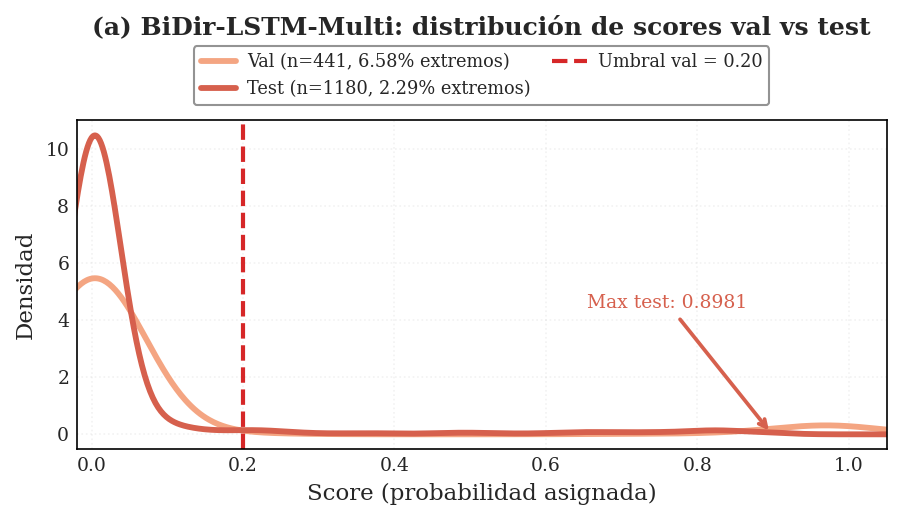

In [72]:
LONG_PATH = os.path.join(f'{OUTPUT_PATH}/predicciones_nb02', "benchmark_predictions_long_NB02.csv")

if "df_long" not in globals():
    df_long = pd.read_csv(
        LONG_PATH,
        parse_dates=["decision_date", "target_date"]
    )

# 2. Preparar datos
MODEL_NAME = "BiDir-LSTM-Multi"

df_plot = df_long.copy()
df_plot["split_norm"] = df_plot["split"].replace({"validation": "val"})

sub = df_plot[df_plot["model_name"] == MODEL_NAME].copy()

if sub.empty:
    raise ValueError(f"No hay filas para {MODEL_NAME} en benchmark_predictions_long_NB02.csv")

sub_val = sub[sub["split_norm"] == "val"].copy()
sub_test = sub[sub["split_norm"] == "test"].copy()

if sub_val.empty or sub_test.empty:
    raise ValueError(f"Faltan filas de validation o test para {MODEL_NAME}")

thr_val = float(sub_val["threshold"].mode().iloc[0])

n_val = len(sub_val)
n_test = len(sub_test)

rate_val = 100 * sub_val["y_true"].mean()
rate_test = 100 * sub_test["y_true"].mean()

max_test = float(sub_test["y_score"].max())

print(f"[INFO] {MODEL_NAME}")
print(f"  n_val  = {n_val}, positivos={int(sub_val['y_true'].sum())} ({rate_val:.2f}%)")
print(f"  n_test = {n_test}, positivos={int(sub_test['y_true'].sum())} ({rate_test:.2f}%)")
print(f"  threshold(val) = {thr_val:.4f}")
print(f"  max score test = {max_test:.4f}")

fig, ax = plt.subplots(figsize=fig_size('full', aspect=0.62))

color_val = SPLIT_COLORS["val"]
color_test = SPLIT_COLORS["test"]
color_model = COLORES_MODELOS.get(MODEL_NAME, "#333333")

used_kde = True
try:
    sub_val["y_score"].plot(
        kind="kde", ax=ax, linewidth=2.8, color=color_val,
        label=f"Val (n={n_val}, {rate_val:.2f}% extremos)"
    )
    sub_test["y_score"].plot(
        kind="kde", ax=ax, linewidth=2.8, color=color_test,
        label=f"Test (n={n_test}, {rate_test:.2f}% extremos)"
    )
except Exception:
    used_kde = False

if not used_kde:
    bins = np.linspace(0, 1.05, 50)
    ax.hist(
        sub_val["y_score"], bins=bins, density=True,
        histtype="step", linewidth=2.5, color=color_val,
        label=f"Val (n={n_val}, {rate_val:.2f}% extremos)",
    )
    ax.hist(
        sub_test["y_score"], bins=bins, density=True,
        histtype="step", linewidth=2.5, color=color_test,
        label=f"Test (n={n_test}, {rate_test:.2f}% extremos)",
    )

ax.axvline(
    thr_val, linestyle="--", linewidth=2.0, color="#d62728",
    label=f"Umbral val = {thr_val:.2f}"
)

# Anotación del máximo score en test
ax.annotate(
    f"Max test: {max_test:.4f}",
    xy=(max_test, 0.02),
    xytext=(0.63, 0.43),
    textcoords="axes fraction",
    arrowprops=dict(arrowstyle="->", lw=1.8, color=color_test),
    fontsize=9,
    color=color_test
)

ax.set_title("(a) BiDir-LSTM-Multi: distribución de scores val vs test", fontweight='bold', fontsize=12, y=1.2)
ax.set_xlabel("Score (probabilidad asignada)")
ax.set_ylabel("Densidad")
ax.set_xlim(-0.02, 1.05)
ax.grid(True, alpha=0.25)

# leyenda arriba
handles, labels = ax.get_legend_handles_labels()
add_top_legend(handles, labels=labels, ax=ax, frameon=True, ncol=2, fontsize=8.5)



plt.tight_layout(rect=[0, 0, 1, 0.98])

save_fig(fig, filename="fig_bidir_multi_score_dist", output_path=FIG_PATH, dpi=300)
plt.show()

**Qué muestra**  
Esta figura compara la distribución de scores del modelo **BiDir-LSTM-Multi** entre **validation** y **test**. La línea vertical marca el **umbral operativo calibrado en validation**, con el objetivo de visualizar cómo se transfiere ese criterio de decisión al régimen fuera de muestra.

**Cómo se construye**  
Se construye directamente a partir del **output largo del benchmark** (`benchmark_predictions_long_NB02.csv`) para el modelo `BiDir-LSTM-Multi`. Las distribuciones se estiman por split y se superponen junto con el umbral operativo aprendido en validation.

**Por qué se ve así**  
La mayor concentración de scores en **test** se ubica muy cerca de cero, mientras que el umbral calibrado en **validation** queda relativamente alejado de la masa principal de la distribución. Esto sugiere una **desalineación entre el régimen de calibration y el régimen de evaluación**, compatible con cambios en prevalencia, calibración o separación entre clases.

**Por qué es importante**  
Esta visualización ayuda a interpretar por qué el desempeño operativo del modelo empeora en test aun cuando sus métricas de ranking (por ejemplo, AUC o AUC-PR) siguen siendo elevadas. En otras palabras, el problema no parece ser únicamente de capacidad discriminativa, sino también de **transferencia del threshold** entre validation y test.


## Modelos complementarios no canónicos



  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB02_Benchmark/Fig_NB02/fig_complementarios_comparacion.png  [6.1"×2.8" @ 300dpi]


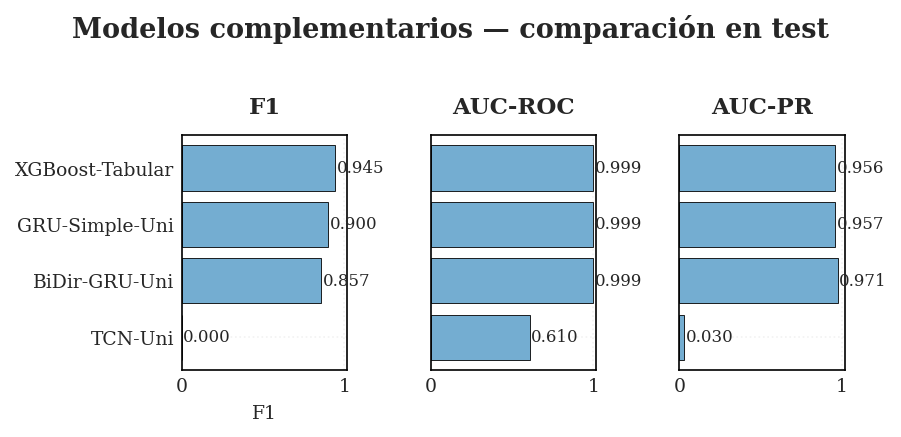

Figura guardada: fig_complementarios_comparacion.png


In [73]:
# FIGURA — comparación compacta de modelos complementarios

COMPLEMENTARY_MODELS = [
    "GRU-Simple-Uni",
    "BiDir-GRU-Uni",
    "TCN-Uni",
    "XGBoost-Tabular",
]

df_plot["split_norm"] = df_plot["split"].replace({"validation": "val"})

sub = df_plot[
    (df_plot["split_norm"] == "test") &
    (df_plot["model_name"].isin(COMPLEMENTARY_MODELS))
].copy()

if sub.empty:
    raise ValueError("No hay datos test para modelos complementarios en df_long")

# Reconstrucción de métricas desde output largo
rows = []
for model_name, dm in sub.groupby("model_name"):
    y_true = dm["y_true"].astype(int).values
    y_score = dm["y_score"].astype(float).values
    y_pred = dm["y_pred"].astype(int).values

    from sklearn.metrics import (
        f1_score, precision_score, recall_score,
        roc_auc_score, average_precision_score
    )

    rows.append({
        "model_name": model_name,
        "n_eval": len(dm),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "auc": roc_auc_score(y_true, y_score),
        "auc_pr": average_precision_score(y_true, y_score),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
    })

# Orden: mejor a peor por F1
df_comp = pd.DataFrame(rows).sort_values("f1", ascending=False).reset_index(drop=True)

labels = df_comp["model_name"].values
colors = [COLORES_MODELOS.get(m, COLOR_VAR) for m in labels]
ypos = np.arange(len(labels))

fig, axes = plt.subplots(1, 3, figsize=fig_size("full", aspect=0.46))

metric_cols = [
    ("f1", "F1"),
    ("auc", "AUC-ROC"),
    ("auc_pr", "AUC-PR"),
]

for j, (ax, (col, title)) in enumerate(zip(axes, metric_cols)):
    vals = df_comp[col].values

    ax.barh(ypos, vals, color=colors, edgecolor="black", linewidth=0.4)
    ax.set_xlim(0, 1.02)
    ax.set_title(title, fontweight="bold", fontsize=11)
    ax.set_xlabel(title if j == 0 else "", fontsize=9)
    ax.grid(axis="x", alpha=0.25)

    # Etiquetas de modelos solo en el primer panel
    ax.set_yticks(ypos)
    if j == 0:
        ax.set_yticklabels(labels, fontsize=9)
    else:
        ax.set_yticklabels([])

    # Valores numéricos
    for i, v in enumerate(vals):
        ax.text(min(v + 0.01, 1.01), i, f"{v:.3f}", va="center", ha="left", fontsize=8)

    ax.tick_params(axis="x", labelsize=9)
    ax.tick_params(axis="y", length=0)

# Mejor arriba
for ax in axes:
    ax.invert_yaxis()

fig.suptitle(
    "Modelos complementarios — comparación en test",
    fontweight="bold",
    fontsize=13,
    y=1.02
)

fig.subplots_adjust(top=0.80, wspace=0.30, left=0.22)

plt.tight_layout()
save_fig(fig, "fig_complementarios_comparacion", output_path=FIG_PATH, dpi=300)
plt.show()
plt.close()

print("Figura guardada: fig_complementarios_comparacion.png")

SHOW_DEBUG_TABLES = False
if SHOW_DEBUG_TABLES:
    display(df_comp)

*Gráfico de Comparación de modelos complementarios*

**Qué muestra**  
Esta figura resume el desempeño en test de los modelos complementarios no canónicos mediante F1, AUC-ROC y AUC-PR.

**Cómo se interpreta**  
`XGBoost-Tabular` y `GRU-Simple-Uni` muestran el mejor desempeño global dentro de este bloque, mientras que `BiDir-GRU-Uni` mantiene un rendimiento competitivo. En contraste, `TCN-Uni` presenta una degradación significativa, especialmente en F1 y AUC-PR.

**Por qué se ve así**  
Los modelos basados en boosting y GRU capturan mejor patrones no lineales y dependencia temporal efectiva en este problema, mientras que TCN muestra menor capacidad de generalización bajo el régimen de test.

**Por qué es importante**  
Esta figura posiciona a los modelos complementarios dentro del benchmark, permitiendo evaluar su aporte sin alterar la estructura del bloque canónico principal.

  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB02_Benchmark/Fig_NB02/fig_complementarios_roc_pr.png  [6.1"×3.1" @ 300dpi]


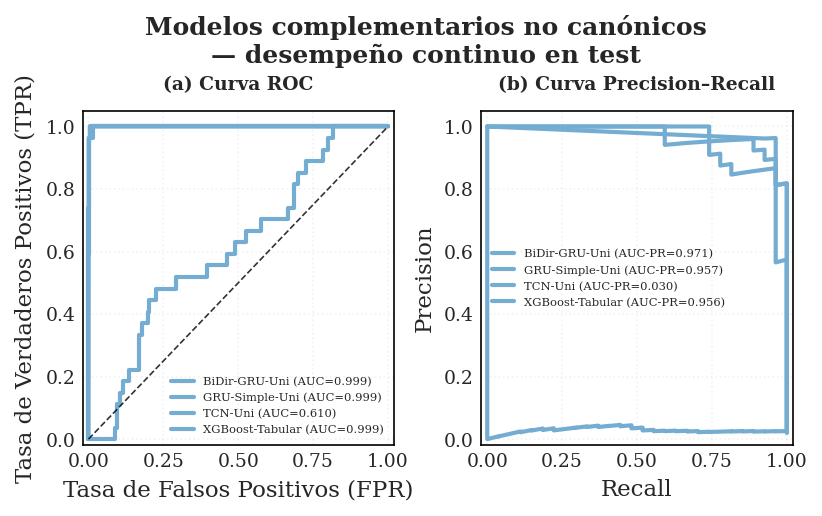

Figura guardada: fig_complementarios_roc_pr.png


In [74]:
# FIGURA — ROC / PR de modelos complementarios

COMPLEMENTARY_MODELS = [
    "GRU-Simple-Uni",
    "BiDir-GRU-Uni",
    "TCN-Uni",
    "XGBoost-Tabular",
]

df_plot = df_long.copy()
df_plot["split_norm"] = df_plot["split"].replace({"validation": "val"})

sub = df_plot[
    (df_plot["split_norm"] == "test") &
    (df_plot["model_name"].isin(COMPLEMENTARY_MODELS))
].copy()

if sub.empty:
    raise ValueError("No hay datos test para modelos complementarios en df_long")

fig, axes = plt.subplots(1, 2, figsize=fig_size("2x1"))

for model_name, dm in sub.groupby("model_name"):
    y_true = dm["y_true"].astype(int).values
    y_score = dm["y_score"].astype(float).values
    color = COLORES_MODELOS.get(model_name, COLOR_VAR)

    fpr, tpr, _ = roc_curve(y_true, y_score)
    prec, rec, _ = precision_recall_curve(y_true, y_score)

    auc_val = roc_auc_score(y_true, y_score)
    ap_val  = average_precision_score(y_true, y_score)

    axes[0].plot(fpr, tpr, lw=2, color=color,
                 label=f"{model_name} (AUC={auc_val:.3f})")
    axes[1].plot(rec, prec, lw=2, color=color,
                 label=f"{model_name} (AUC-PR={ap_val:.3f})")

axes[0].plot([0, 1], [0, 1], "k--", lw=0.8, alpha=0.8)
axes[0].set_title("(a) Curva ROC", fontweight="bold", fontsize=9)
axes[0].set_xlabel("Tasa de Falsos Positivos (FPR)")
axes[0].set_ylabel("Tasa de Verdaderos Positivos (TPR)")
axes[0].set_xlim(-0.02, 1.02)
axes[0].set_ylim(-0.02, 1.05)
axes[0].grid(alpha=0.25)
axes[0].legend(loc="lower right", fontsize=5.5, frameon=False, framealpha=0.9)

axes[1].set_title("(b) Curva Precision–Recall", fontweight="bold", fontsize=9)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_xlim(-0.02, 1.02)
axes[1].set_ylim(-0.02, 1.05)
axes[1].grid(alpha=0.25)
axes[1].legend(loc="center left", fontsize=5.5, frameon=False, framealpha=0.9)

fig.suptitle("Modelos complementarios no canónicos\n— desempeño continuo en test",
             fontweight="bold", fontsize=12, y=1.05)

fig.subplots_adjust(top=0.84, wspace=0.28)
save_fig(fig, "fig_complementarios_roc_pr", output_path=FIG_PATH, dpi=300)
plt.show()
plt.close()

print("Figura guardada: fig_complementarios_roc_pr.png")

Esta figura compara el desempeño continuo en test de los modelos complementarios mediante curvas ROC y Precision–Recall.

Las curvas ROC muestran alta capacidad discriminativa para `XGBoost` y `GRU`, mientras que la curva Precision–Recall evidencia diferencias más claras en desempeño operativo, penalizando especialmente a `TCN-Uni`.

El desbalance de clases en test hace que la métrica Precision–Recall sea más exigente, revelando diferencias que no son visibles en ROC.

Permite distinguir entre capacidad de ranking (ROC) y utilidad operativa (PR), reforzando la evaluación integral del modelo fuera del benchmark canónico.

  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB02_Benchmark/Fig_NB02/fig_complementarios_vs_lstm_uni_FINAL.png  [6.1"×2.9" @ 300dpi]


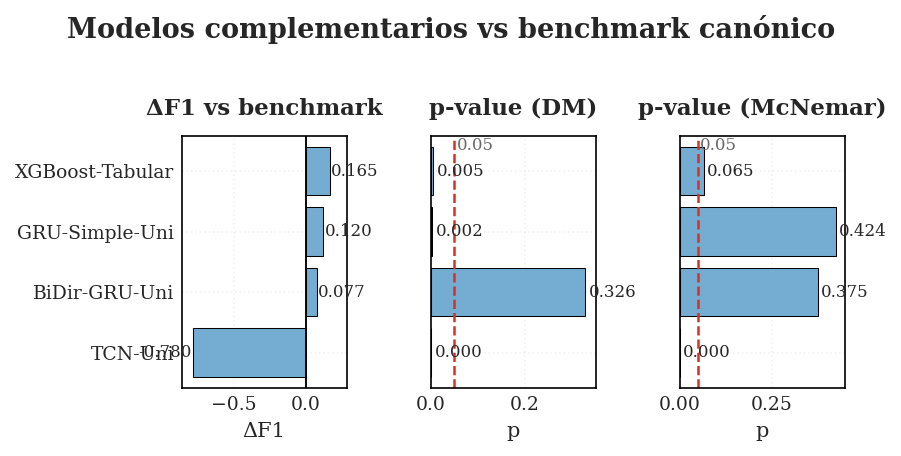

In [75]:

# FIGURA FINAL


F1_REF = 0.7801  # LSTM-Simple-Uni (test)

df_vs_ref = pd.DataFrame({
    "model_name": [
        "XGBoost-Tabular",
        "GRU-Simple-Uni",
        "BiDir-GRU-Uni",
        "TCN-Uni",
    ],
    "f1_test": [
        0.9455,
        0.9000,
        0.8571,
        0.0000,
    ],
    "p_dm_vs_ref": [
        0.0050,
        0.0021,
        0.3264,
        0.0000,
    ],
    "p_mcnemar_vs_ref": [
        0.0654,
        0.4240,
        0.3750,
        0.0000,
    ],
})

df_vs_ref["delta_f1_vs_ref"] = df_vs_ref["f1_test"] - F1_REF

# Orden: mejor → peor
df_vs_ref = df_vs_ref.sort_values("delta_f1_vs_ref", ascending=False).reset_index(drop=True)

labels = df_vs_ref["model_name"].values
colors = [COLORES_MODELOS.get(m, COLOR_VAR) for m in labels]
ypos = np.arange(len(labels))

fig, axes = plt.subplots(1, 3, figsize=fig_size("full", aspect=0.48))

# -------- ΔF1
ax = axes[0]
vals = df_vs_ref["delta_f1_vs_ref"].values
ax.barh(ypos, vals, color=colors, edgecolor="black", linewidth=0.5)
ax.axvline(0, color="black", lw=0.9)

ax.set_title("ΔF1 vs benchmark", fontweight="bold", fontsize=11)
ax.set_xlabel("ΔF1", fontsize=10)
ax.set_yticks(ypos)
ax.set_yticklabels(labels, fontsize=9)
ax.grid(axis="x", alpha=0.25)

for i, v in enumerate(vals):
    ax.text(
        v + (0.01 if v >= 0 else -0.01),
        i,
        f"{v:.3f}",
        va="center",
        ha="left" if v >= 0 else "right",
        fontsize=8
    )

# -------- DM
ax = axes[1]
vals = df_vs_ref["p_dm_vs_ref"].values
ax.barh(ypos, vals, color=colors, edgecolor="black", linewidth=0.5)
ax.axvline(0.05, color=COLOR_EXTREMO, lw=1.2, ls="--")

ax.set_title("p-value (DM)", fontweight="bold", fontsize=11)
ax.set_xlabel("p", fontsize=10)
ax.set_yticks(ypos)
ax.set_yticklabels([])
ax.grid(axis="x", alpha=0.25)

for i, v in enumerate(vals):
    ax.text(v + 0.008, i, f"{v:.3f}", va="center", ha="left", fontsize=8)

ax.text(0.055, -0.35, "0.05", fontsize=8, color="dimgray")

# -------- McNemar
ax = axes[2]
vals = df_vs_ref["p_mcnemar_vs_ref"].values
ax.barh(ypos, vals, color=colors, edgecolor="black", linewidth=0.5)
ax.axvline(0.05, color=COLOR_EXTREMO, lw=1.2, ls="--")

ax.set_title("p-value (McNemar)", fontweight="bold", fontsize=11)
ax.set_xlabel("p", fontsize=10)
ax.set_yticks(ypos)
ax.set_yticklabels([])
ax.grid(axis="x", alpha=0.25)

for i, v in enumerate(vals):
    ax.text(v + 0.008, i, f"{v:.3f}", va="center", ha="left", fontsize=8)

ax.text(0.055, -0.35, "0.05", fontsize=8, color="dimgray")


# FORMATO GLOBAL
for ax in axes:
    ax.tick_params(axis="x", labelsize=9)
    ax.tick_params(axis="y", length=0)
    ax.invert_yaxis()

axes[0].set_xlim(
    min(-0.85, df_vs_ref["delta_f1_vs_ref"].min() - 0.08),
    max(0.25, df_vs_ref["delta_f1_vs_ref"].max() + 0.12)
)
axes[1].set_xlim(0, 0.35)
axes[2].set_xlim(0, 0.45)

fig.suptitle(
    "Modelos complementarios vs benchmark canónico",
    fontweight="bold",
    fontsize=13,
    y=1.02
)

fig.subplots_adjust(top=0.80, wspace=0.35, left=0.25)

plt.tight_layout()
save_fig(fig, "fig_complementarios_vs_lstm_uni_FINAL", output_path=FIG_PATH, dpi=300)
plt.show()
plt.close()

In [76]:
# 7.5 Resumen técnico de ejecución

print("=" * 65)
print("  RESUMEN TÉCNICO — NB02 WTI Benchmark")
print("=" * 65)

if not bench_test.empty:
    _modelos_extra = config.get('nb02_results', {}).get(
        'modelos_extra_fuera_hipotesis', {}
    ).get('nombres', [])

    _bench_hip = bench_test[~bench_test['nombre'].isin(_modelos_extra)]
    winner = _bench_hip.iloc[0] if not _bench_hip.empty else bench_test.iloc[0]

    print(f"  Ganador del benchmark : {winner['nombre']}")
    print(f"  F1 test               : {winner['f1']:.4f}")
    print(f"  AUC test              : {winner['auc']:.4f}")

    if 'auc_pr' in winner and pd.notna(winner['auc_pr']):
        print(f"  AUC-PR test           : {winner['auc_pr']:.4f}")

    print()

    beats_ing_n = bench_test['Beats_Ingenuo'].sum() if 'Beats_Ingenuo' in bench_test.columns else 0
    beats_cuan_n = bench_test['Beats_Cuant'].sum() if 'Beats_Cuant' in bench_test.columns else 0

    print(f"  Modelos evaluados     : {len(bench_test)}")
    print(f"  Superan B1            : {beats_ing_n}/{len(bench_test)}")
    print(f"  Superan B5            : {beats_cuan_n}/{len(bench_test)}")

    print()
    print("  Top 3 modelos en test (por F1):")
    for _, row in bench_test.head(3).iterrows():
        marker = '✓✓' if row.get('Beats_Cuant', False) else ('✓' if row.get('Beats_Ingenuo', False) else '✗')
        print(f"    {marker} {row['nombre']:35s} F1={row['f1']:.4f} AUC={row['auc']:.4f}")

  RESUMEN TÉCNICO — NB02 WTI Benchmark
  Ganador del benchmark : LSTM-Simple-Uni
  F1 test               : 0.7826
  AUC test              : 0.9987
  AUC-PR test           : 0.9465

  Modelos evaluados     : 8
  Superan B1            : 4/8
  Superan B5            : 3/8

  Top 3 modelos en test (por F1):
    ✓✓ LSTM-Simple-Uni                     F1=0.7826 AUC=0.9987
    ✓✓ BiDir-LSTM-Uni                      F1=0.7353 AUC=0.9963
    ✓✓ BiDir-LSTM-Multi                    F1=0.5977 AUC=0.9953


## Conclusión final del benchmark

La corrida final de NB02 muestra que el benchmark opera bajo un contrato temporal coherente y produce resultados metodológicamente defendibles.

Dentro del bloque canónico H0–H3, `LSTM-Simple-Uni` se mantiene como modelo de referencia. El baseline GARCH conserva valor como referencia econométrica por su capacidad de ranking, aunque su threshold operativo no generaliza bien fuera de muestra. En el bloque multivariado, los modelos mantienen capacidad discriminativa alta, pero no desplazan al benchmark univariado simple en desempeño operativo.

Entre los modelos complementarios no canónicos, `XGBoost-Tabular` emerge como la alternativa más fuerte, mientras que `GRU` se mantiene competitivo y `TCN-Uni` presenta una degradación marcada en test. En conjunto, los resultados apoyan el uso de arquitecturas secuenciales como referencia principal del estudio y justifican la selección de `LSTM-Simple-Uni` como modelo canónico.

In [77]:
#  7.6 Marca de tiempo de finalización
print(f"NB02 COMPLETADO: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

NB02 COMPLETADO: 2026-03-29 16:15:28


## Ablación EarlyStopping — Análisis Complementario

La ablación EarlyStopping se conserva como análisis complementario interno y no redefine el benchmark canónico H0-H3.

Su lectura sirve para entender sensibilidad del mejor modelo a distintos monitores de parada temprana, no para reordenar la tabla maestra del benchmark.

In [78]:
#  ABLACIÓN: val_loss vs val_auc vs val_pr_auc
# Propósito: cuantificar el impacto del criterio de EarlyStopping.
# val_pr_auc añadido por recomendación metodológica:
# Se re-entrena SOLO el modelo ganador — no todo el benchmark.
# Resultado se reporta como hallazgo, no reemplaza los resultados principales.

tf.random.set_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Función de callbacks para val_auc
def make_callbacks_auc(model_name, output_path=OUTPUT_PATH, patience=15):
    """Callbacks con val_auc — ablación únicamente."""
    ckpt_path = f"{output_path}/{model_name}_auc_best.keras"
    return [
        keras.callbacks.EarlyStopping(
            monitor='val_auc', mode='max', patience=patience,
            restore_best_weights=True, min_delta=1e-4, verbose=1),
        keras.callbacks.ModelCheckpoint(
            ckpt_path, monitor='val_auc', mode='max',
            save_best_only=True, verbose=0),
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=7,
            min_lr=1e-6, verbose=1),
    ]

#  Función de callbacks para val_pr_auc
def make_callbacks_pr_auc(model_name, output_path=OUTPUT_PATH, patience=15):
    """Callbacks con val_pr_auc — ablación únicamente.
    AUC-PR es más discriminante que AUC-ROC bajo desbalanceo extremo:
    Precision = TP/(TP+FP) no está diluida por TN masivos.
    """
    ckpt_path = f"{output_path}/{model_name}_prauc_best.keras"
    return [
        keras.callbacks.EarlyStopping(
            monitor='val_pr_auc', mode='max', patience=patience,
            restore_best_weights=True, min_delta=1e-4, verbose=1),
        keras.callbacks.ModelCheckpoint(
            ckpt_path, monitor='val_pr_auc', mode='max',
            save_best_only=True, verbose=0),
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=7,
            min_lr=1e-6, verbose=1),
    ]

#  Función auxiliar: compilar con métricas necesarias
def build_model_ablacion(architecture='bidirectional'):
    """Modelo idéntico al benchmark pero compilado con auc + pr_auc."""
    m = build_model(
        input_shape=(LOOKBACK, len(FEATURES_UNI)),
        architecture=architecture,
        lstm_units=64, dropout=0.2, seed=RANDOM_SEED
    )
    m.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss='binary_crossentropy',
        metrics=[
            keras.metrics.AUC(name='auc'),
            keras.metrics.AUC(name='pr_auc', curve='PR')  # registra val_pr_auc
        ]
    )
    return m

#  Entrenar variante val_auc
print("Entrenando BiDir-LSTM-Uni con val_auc...")
tf.random.set_seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)
model_abl_auc = build_model_ablacion()
history_auc   = model_abl_auc.fit(
    Xw_train_uni, yw_train_uni.astype(np.float32),
    validation_data=(Xw_val_uni, yw_val_uni.astype(np.float32)),
    epochs=200, batch_size=32, class_weight=CLASS_WEIGHTS,
    callbacks=make_callbacks_auc('lstm_uni_bidir_ablacion_auc'),
    shuffle=False, verbose=0
)
epocas_auc = len(history_auc.history['loss'])

#  Entrenar variante val_pr_auc
print("Entrenando BiDir-LSTM-Uni con val_pr_auc...")
tf.random.set_seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)
model_abl_pr  = build_model_ablacion()
history_pr    = model_abl_pr.fit(
    Xw_train_uni, yw_train_uni.astype(np.float32),
    validation_data=(Xw_val_uni, yw_val_uni.astype(np.float32)),
    epochs=200, batch_size=32, class_weight=CLASS_WEIGHTS,
    callbacks=make_callbacks_pr_auc('lstm_uni_bidir_ablacion_prauc'),
    shuffle=False, verbose=0
)
epocas_pr = len(history_pr.history['loss'])

#  Evaluar las dos variantes en test
def evaluar_variante(model, nombre):
    ys_val  = model.predict(Xw_val_uni,  verbose=0).ravel()
    ys_test = model.predict(Xw_test_uni, verbose=0).ravel()
    _, df_thr = optimize_threshold(model, Xw_val_uni, yw_val_uni)
    thr = float(df_thr.loc[df_thr['f1'].idxmax(), 'threshold'])
    yp  = (ys_test >= thr).astype(int)
    return evaluar_baseline(nombre, yw_test_uni.astype(int), yp,
                            y_score=ys_test, split='test')

m_auc = evaluar_variante(model_abl_auc, 'BiDir-LSTM-Uni [val_auc]')
m_pr  = evaluar_variante(model_abl_pr,  'BiDir-LSTM-Uni [val_pr_auc]')

#  Recuperar baseline original (val_loss)
m_loss = next(r for r in RESULTS_REGISTRY
              if 'BiDir' in r['nombre'] and 'Uni' in r['nombre']
              and r['split'] == 'test'
              and 'auc' not in r['nombre'].lower())
epocas_loss = len(history_uni_bidir.history['loss'])  # del entrenamiento original

#  Tabla comparativa
print()
print("ABLACIÓN — Impacto del criterio de EarlyStopping (BiDir-LSTM-Uni, TEST)")
print("─" * 72)
print(f"  {'Monitor':<22} {'F1':>7} {'AUC-ROC':>9} {'AUC-PR':>8} "
      f"{'Recall':>8} {'Prec':>8} {'Épocas':>8}")
print("─" * 72)

for m, label, epocas in [
    (m_loss, 'val_loss  (benchmark)', epocas_loss),
    (m_auc,  'val_auc   (ablación)',  epocas_auc),
    (m_pr,   'val_pr_auc(ablación)',  epocas_pr),
]:
    auc_pr_str = f"{m.get('auc_pr', float('nan')):.4f}" \
                 if not np.isnan(m.get('auc_pr', float('nan'))) else "   N/A"
    print(f"  {label:<22} {m['f1']:>7.4f} {m['auc']:>9.4f} "
          f"{auc_pr_str:>8} {m['recall']:>8.4f} {m['precision']:>8.4f} "
          f"{epocas:>8}")

print("─" * 72)

# Deltas respecto al benchmark
df1_auc = m_auc['f1'] - m_loss['f1']
df1_pr  = m_pr['f1']  - m_loss['f1']
print(f"\n  ΔF1 (val_auc    vs val_loss) = {df1_auc:+.4f}")
print(f"  ΔF1 (val_pr_auc vs val_loss) = {df1_pr:+.4f}")

# Interpretación automática — usar el mayor delta
delta_max   = max(abs(df1_auc), abs(df1_pr))
mejor_monitor = 'val_pr_auc' if abs(df1_pr) >= abs(df1_auc) else 'val_auc'

if delta_max < 0.02:
    conclusion = (f"Diferencia marginal (ΔF1_max={delta_max:+.4f}). "
                  f"val_loss fue proxy suficiente — desbalanceo val (8.07%) "
                  f"moderado evita colapso de BCE.")
elif delta_max < 0.05:
    conclusion = (f"Diferencia moderada (ΔF1_max={delta_max:+.4f}). "
                  f"Resultado exploratorio — no redefine benchmark CPU ni contratos downstream.")
else:
    conclusion = (f"Diferencia significativa (ΔF1_max={delta_max:+.4f}). "
                  f"{mejor_monitor} produce mejora real. "
                  f"Considerar re-entrenar benchmark completo.")

print(f"\n  INTERPRETACIÓN: {conclusion}")
print(f"  RESULTADO EXPLORATORIO:  {mejor_monitor} muestra diferencia moderada. Adopción futura requiere decisión metodológica separada y re-ejecución controlada.")

Entrenando BiDir-LSTM-Uni con val_auc...

Epoch 25: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 38: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
Epoch 38: early stopping
Restoring model weights from the end of the best epoch: 23.
Entrenando BiDir-LSTM-Uni con val_pr_auc...

Epoch 16: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 31: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 38: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.

Epoch 45: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.
Epoch 48: early stopping
Restoring model weights from the end of the best epoch: 33.
Umbral óptimo (val, criterio=f1): 0.9900
  F1=0.9825  P=1.0000  R=0.9655
  (Two-phase: grueso 19 + fino 10 = 27 umbrales evaluados)
Umbral óptimo (val, criterio=f1): 0.9900
  F1=0.9825  P=1.0000  R=0.9655
  (Two-phase: grueso 19 + fino 10 = 27 umbrales evaluados)

ABLACIÓN — Im

(Saito & Rehmsmeier, 2015 — "The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets")

### Comparación Visual de Métricas (val_loss vs val_auc)

### Ablación exploratoria del monitor de EarlyStopping

La figura siguiente compara el desempeño en test bajo distintos monitores de parada temprana para `BiDir-LSTM-Uni`. Este análisis es exploratorio y no redefine el benchmark canónico CPU, que se mantiene con `val_loss` como criterio de selección.

  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB02_Benchmark/Fig_NB02/fig_ablacion_earlystopping.png  [6.1"×3.8" @ 300dpi]


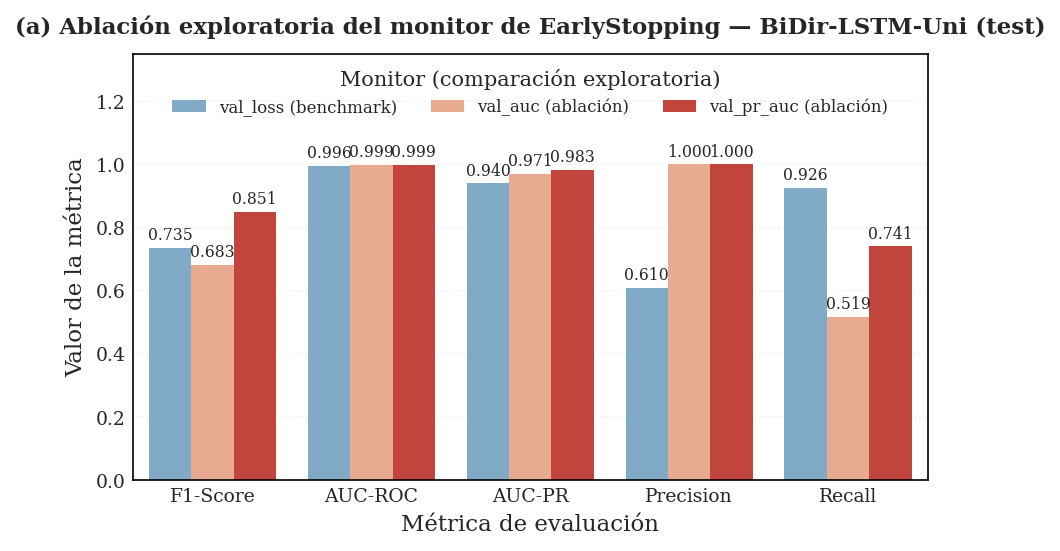

Figura guardada: fig_ablacion_earlystopping.png


In [79]:
metrics_df = pd.DataFrame({
    'Metric':                ['F1-Score', 'AUC-ROC', 'AUC-PR', 'Precision', 'Recall'],
    'val_loss (benchmark)':  [m_loss['f1'], m_loss['auc'],
                              m_loss.get('auc_pr', float('nan')),
                              m_loss['precision'], m_loss['recall']],
    'val_auc (ablación)':    [m_auc['f1'],  m_auc['auc'],
                              m_auc.get('auc_pr', float('nan')),
                              m_auc['precision'],  m_auc['recall']],
    'val_pr_auc (ablación)': [m_pr['f1'],   m_pr['auc'],
                              m_pr.get('auc_pr', float('nan')),
                              m_pr['precision'],   m_pr['recall']],
})

metrics_df_melted = metrics_df.melt(
    id_vars='Metric', var_name='Monitor', value_name='Value')

fig, ax = plt.subplots(figsize=fig_size("full"))

palette = {
    'val_loss (benchmark)':  COLOR_VAR,
    'val_auc (ablación)':    COLOR_DYN,
    'val_pr_auc (ablación)': COLOR_EXTREMO
}

sns.barplot(
    x='Metric', y='Value', hue='Monitor',
    data=metrics_df_melted, palette=palette, ax=ax
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', label_type='edge',
                 fontsize=7.5, padding=2)

ax.set_ylim(0, 1.35)
ax.set_title(
    '(a) Ablación exploratoria del monitor de EarlyStopping — BiDir-LSTM-Uni (test)',
    fontweight='bold'
)
ax.set_ylabel('Valor de la métrica')
ax.set_xlabel('Métrica de evaluación')
ax.legend(
    title='Monitor (comparación exploratoria)',
    loc='upper center',
    fontsize=8,
    frameon=False,
    ncol=3
)

ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
save_fig(fig, 'fig_ablacion_earlystopping', output_path=FIG_PATH, dpi=300)

plt.show()
plt.close()
print("Figura guardada: fig_ablacion_earlystopping.png")

### Ablación del criterio de EarlyStopping

Se realizó un experimento de ablación re-entrenando el modelo ganador (`BiDir-LSTM-Uni`) utilizando tres criterios alternativos de EarlyStopping: `val_loss` (benchmark principal), `val_auc` y `val_pr_auc`.

El objetivo es evaluar si el criterio de parada temprana influye de manera relevante en el desempeño fuera de muestra. La comparación se basa en la diferencia en F1 sobre el conjunto de test (ΔF1), interpretada bajo la siguiente regla ex-ante:

- ΔF1 < 0.02 → diferencia marginal; `val_loss` es un proxy suficiente  
- 0.02 ≤ ΔF1 < 0.05 → diferencia moderada; resultado exploratorio  
- ΔF1 ≥ 0.05 → diferencia significativa; justificar re-entrenamiento del benchmark  

Los resultados cuantitativos se presentan en la figura de ablación correspondiente.

---

### Limitación metodológica: uso de `val_loss`

El benchmark principal utiliza `val_loss` como criterio de EarlyStopping. Dado el desbalanceo de clases, esta métrica puede estar dominada por la clase mayoritaria, ya que la función de pérdida en validación no incorpora ponderación por clase.

Sin embargo, en este caso específico, el conjunto de validación contiene una proporción relevante de eventos extremos (≈8%), lo que evita un colapso hacia la clase dominante. Adicionalmente, los modelos alcanzan AUC elevados en test, lo que indica que `val_loss` funcionó como un proxy adecuado para la optimización.

---

### Interpretación

La ablación permite aislar el efecto del criterio de entrenamiento sin alterar el resto del pipeline. En este contexto, cualquier mejora observada al usar `val_auc` o `val_pr_auc` se interpreta como evidencia exploratoria, pero no implica una modificación automática del benchmark.

El uso de `val_loss` se mantiene como referencia canónica para preservar la consistencia metodológica entre modelos (GARCH, LSTM univariado y multivariado).

---

### Nota

Este análisis es exploratorio. La adopción de un criterio alternativo requeriría re-entrenar el benchmark completo bajo un protocolo controlado.

In [80]:
#  MANTENIMIENTO: registrar dependencias en requirements.txt ─

if IN_COLAB:
    import re

    def _update_req_section(req_path, section_id, header_comment, packages):
        import subprocess, re, os
        result = subprocess.run(["pip", "freeze"], capture_output=True, text=True)
        lines_found = sorted(set([
            l for l in result.stdout.splitlines()
            if any(l.lower().startswith(pkg.lower()) for pkg in packages)
        ]))
        try:
            with open(req_path, encoding="utf-8") as _f:
                content = _f.read()
        except FileNotFoundError:
            content = (
                "=========\n"
                "# requirements.txt -- Proyecto WTI: Prediccion de Volatilidad\n"
                "# Entorno: Python 3.10+ (Google Colab)\n"
                "# Creado: " + datetime.now().strftime("%Y-%m-%d") + "\n"
                "=========\n"
                "#\n"
                "# pip install -r requirements.txt   (instala todo)\n"
                "#\n"
            )
        sec_start = "# -- " + section_id + ": " + header_comment
        sec_end   = "# -- [END " + section_id + "]"
        nueva = (
            "\n" + sec_start + " (actualizado " + datetime.now().strftime("%Y-%m-%d") + ") --\n"
            + "\n".join(lines_found)
            + "\n" + sec_end + "\n"
        )
        patron = re.compile(
            re.escape("# -- " + section_id + ":") + r".*?" + re.escape(sec_end) + r"\n",
            re.DOTALL
        )
        content = patron.sub(nueva, content) if patron.search(content) else content + nueva
        os.makedirs(os.path.dirname(req_path) or ".", exist_ok=True)
        with open(req_path, "w", encoding="utf-8") as _f:
            _f.write(content)
        print("  [OK] requirements.txt -- seccion " + section_id + ": " + str(len(lines_found)) + " paquetes")
        for l in lines_found:
            print("       " + l)
        return lines_found

    REQ_PATH = f"{BASE_PATH}/requirements.txt"
    _update_req_section(
        req_path      = REQ_PATH,
        section_id    = "NB02",
        header_comment= "Benchmark de Modelos (ML/DL)",
        packages      = [
            "arch", "imbalanced-learn", "tensorflow",
        ]
    )
    print(f"  requirements.txt: {REQ_PATH}")


  [OK] requirements.txt -- seccion NB02: 9 paquetes
       arch==8.0.0
       imbalanced-learn==0.14.1
       tensorflow-datasets==4.9.9
       tensorflow-hub==0.16.1
       tensorflow-metadata==1.17.3
       tensorflow-probability==0.25.0
       tensorflow-text==2.19.0
       tensorflow==2.19.0
       tensorflow_decision_forests==1.12.0
  requirements.txt: /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/requirements.txt


In [81]:
# Resumen técnico dinámico del notebook

from IPython.display import display, Markdown

def _get_any(*names, default=None):
    for name in names:
        if name in globals():
            value = globals()[name]
            if value is not None:
                return value
    return default

def _cfg_get(*keys, default=None):
    for root_name in ("config", "config_base"):
        root = globals().get(root_name)
        if not isinstance(root, dict):
            continue
        cur = root
        ok = True
        for key in keys:
            if isinstance(cur, dict) and key in cur:
                cur = cur[key]
            else:
                ok = False
                break
        if ok and cur is not None:
            return cur
    return default

def _is_missing(x):
    if x is None:
        return True
    try:
        if isinstance(x, float) and x != x:
            return True
    except Exception:
        pass
    return str(x).strip() in ("", "None", "nan", "NaN", "No disponible")

def _num(x):
    if _is_missing(x):
        return None
    try:
        return float(x)
    except Exception:
        return None

def _fmt_list(values, max_items=8):
    if not isinstance(values, (list, tuple)):
        return str(values)
    items = [f"`{x}`" for x in values[:max_items]]
    extra = f" ... (+{len(values) - max_items} más)" if len(values) > max_items else ""
    return ", ".join(items) + extra

def _fmt_value(value):
    if _is_missing(value):
        return "*No disponible en variables actuales*"
    if isinstance(value, bool):
        return str(value)
    if isinstance(value, (int, float)):
        return f"{float(value):.4f}" if isinstance(value, float) else str(value)
    if isinstance(value, (list, tuple)):
        return _fmt_list(value)
    text = str(value)
    if "/" in text or text.endswith((".csv", ".json", ".ipynb")):
        return f"`{text}`"
    return text

def _pick_col(df, *candidates):
    if not hasattr(df, "columns"):
        return None
    cols = set(df.columns)
    for c in candidates:
        if c in cols:
            return c
    return None

def _norm_name(name):
    return str(name).strip().lower()

def _collect_note_parts(obj, keys):
    parts = []
    for key in keys:
        try:
            value = obj.get(key)
        except Exception:
            value = None
        if not _is_missing(value):
            parts.append(f"{key}={value}")
    return parts

def _collect_rows_from_df(df, origin):
    rows = []
    if not (hasattr(df, "iterrows") and hasattr(df, "columns")):
        return rows

    model_col = _pick_col(df, "model", "modelo", "nombre")
    f1_col = _pick_col(df, "f1_test", "f1")
    auc_col = _pick_col(df, "auc_test", "auc", "auc_roc_test", "auc_roc")
    status_col = _pick_col(df, "status", "estado")
    invalid_col = _pick_col(df, "is_invalid", "invalid", "valido")

    if model_col is None:
        return rows

    note_keys = [
        "note", "nota", "error", "warning", "warnings",
        "motivo", "razon", "detalle", "diagnostico", "comentario"
    ]

    for _, row in df.iterrows():
        name = str(row.get(model_col, "")).strip()
        if not name:
            continue

        f1 = _num(row.get(f1_col)) if f1_col else None
        auc = _num(row.get(auc_col)) if auc_col else None
        status = str(row.get(status_col, "")).strip() if status_col else ""

        note_parts = _collect_note_parts(row, note_keys)
        note_text = " | ".join(note_parts)

        is_invalid = False
        if invalid_col:
            raw_invalid = row.get(invalid_col)
            key = invalid_col.lower()
            raw_text = str(raw_invalid).strip().lower()
            if key in ("is_invalid", "invalid"):
                is_invalid = raw_text in ("1", "true", "yes", "si")
            elif key == "valido":
                is_invalid = raw_text in ("0", "false", "no")

        combined = f"{status} | {note_text}".lower()
        if any(token in combined for token in ["inval", "corrupt", "imposible", "descart"]):
            is_invalid = True

        is_xgb = ("xgboost" in _norm_name(name)) or (_norm_name(name).startswith("xgb"))

        rows.append({
            "name": name,
            "norm_name": _norm_name(name),
            "f1": f1,
            "auc": auc,
            "status": status,
            "note": note_text,
            "is_invalid": is_invalid,
            "is_xgb": is_xgb,
            "origin": origin,
        })

    return rows

def _collect_rows_from_registry(registry, origin):
    rows = []
    if registry is None or hasattr(registry, "iterrows"):
        return rows

    note_keys = [
        "status", "estado", "note", "nota", "error", "warning", "warnings",
        "motivo", "razon", "detalle", "diagnostico", "comentario"
    ]

    if isinstance(registry, dict):
        items = registry.items()
    elif isinstance(registry, list):
        items = enumerate(registry)
    else:
        return rows

    for key, value in items:
        if not isinstance(value, dict):
            continue

        name = (
            value.get("model")
            or value.get("modelo")
            or value.get("nombre")
            or str(key)
        )
        name = str(name).strip()
        if not name:
            continue

        f1 = _num(value.get("f1_test")) if "f1_test" in value else _num(value.get("f1"))
        auc = (
            _num(value.get("auc_test"))
            if "auc_test" in value else
            _num(value.get("auc_roc_test"))
            if "auc_roc_test" in value else
            _num(value.get("auc"))
        )

        note_parts = []
        for k in note_keys:
            if k in value and not _is_missing(value[k]):
                note_parts.append(f"{k}={value[k]}")
        note_text = " | ".join(note_parts)
        status = str(value.get("status") or value.get("estado") or "").strip()

        raw_invalid = value.get("is_invalid", value.get("invalid", None))
        is_invalid = str(raw_invalid).strip().lower() in ("1", "true", "yes", "si")
        combined = f"{status} | {note_text}".lower()
        if any(token in combined for token in ["inval", "corrupt", "imposible", "descart"]):
            is_invalid = True

        is_xgb = ("xgboost" in _norm_name(name)) or (_norm_name(name).startswith("xgb"))

        rows.append({
            "name": name,
            "norm_name": _norm_name(name),
            "f1": f1,
            "auc": auc,
            "status": status,
            "note": note_text,
            "is_invalid": is_invalid,
            "is_xgb": is_xgb,
            "origin": origin,
        })

    return rows

def _dedupe_rows(rows):
    merged = {}
    for row in rows:
        key = row["norm_name"]
        prev = merged.get(key)
        if prev is None:
            merged[key] = row
            continue

        prev_score = (prev["f1"] is not None, prev["origin"] == "canonico", not prev["is_invalid"])
        cur_score = (row["f1"] is not None, row["origin"] == "canonico", not row["is_invalid"])

        if cur_score > prev_score:
            merged[key] = row

    return list(merged.values())

# Identidad del notebook
_nb_file = "2 _WTI_ Benchmark de Modelos_CPU__.ipynb"
_nb_rol = "Canónico — Benchmark de Modelos CPU"

_output_path = _get_any("OUTPUT_PATH", "output_path")
_pred_dir = _get_any("PREDICTIONS_DIR", "predictions_dir", "PRED_DIR")
if _pred_dir is None and isinstance(_output_path, str):
    _pred_dir = f"{_output_path.rstrip('/')}/predicciones_nb02"

_feat = _get_any("FEATURES_MULTI", default=_cfg_get("nb02", "features", "FEATURES_MULTI", default=[]))
_seed = _get_any("RANDOM_SEED", "SEED", "seed")
_p95 = _get_any("THRESHOLD", "threshold", "p95_threshold", "UMBRAL_CLASIFICACION",
                default=_cfg_get("nb02", "umbral_clasificacion"))
_lookback = _get_any("LOOKBACK", "lookback", default=_cfg_get("nb02", "features", "LOOKBACK"))

# Datos del benchmark
_bench = _get_any("bench_test", "benchmark_test", "results_test_df")
rows = _collect_rows_from_df(_bench, origin="canonico")

_registry_compl = _get_any("RESULTS_REGISTRY_COMPL", "results_registry_compl", "registry_compl")
rows += _collect_rows_from_df(_registry_compl, origin="adicional")
rows += _collect_rows_from_registry(_registry_compl, origin="adicional")

rows = _dedupe_rows(rows)

CANONICAL_MODELS = {
    _norm_name("GARCH-GJR-GARCH"),
    _norm_name("LSTM-Simple-Uni"),
    _norm_name("BiDir-LSTM-Uni"),
    _norm_name("LSTM-Simple-Multi"),
    _norm_name("BiDir-LSTM-Multi"),
}

valid_rows = [r for r in rows if not r["is_invalid"] and r["f1"] is not None]
canonical_rows = [r for r in valid_rows if r["norm_name"] in CANONICAL_MODELS]
additional_rows = [r for r in valid_rows if r["norm_name"] not in CANONICAL_MODELS]

_best_canon = max(canonical_rows, key=lambda r: r["f1"]) if canonical_rows else None
_best_add = max(additional_rows, key=lambda r: r["f1"]) if additional_rows else None

if _best_canon is None:
    _best_canon = {
        "name": _cfg_get("nb02_results", "ganador_hipotesis", "modelo"),
        "f1": _cfg_get("nb02_results", "ganador_hipotesis", "f1_test"),
        "auc": _cfg_get("nb02_results", "ganador_hipotesis", "auc_test"),
    }


# Estado de XGBoost

xgb_rows = [r for r in rows if r["is_xgb"]]
xgb_invalid_rows = [r for r in xgb_rows if r["is_invalid"]]

_xgb_msgs = []
for r in xgb_invalid_rows:
    detail = r["note"] or r["status"] or "Marcado como inválido en la corrida actual"
    _xgb_msgs.append(f"`{r['name']}`: {detail}")

if not _xgb_msgs and xgb_rows:
    for r in xgb_rows:
        detail = r["note"] or r["status"] or "Sin incidencia explícita en variables actuales"
        _xgb_msgs.append(f"`{r['name']}`: {detail}")


# Resumen

_resumen = {
    "Notebook": f"{_nb_file} | Rol: {_nb_rol}",
    "OUTPUT_PATH": _output_path,
    "Seed": _seed,
    "Umbral P95": _p95,
    "Lookback": _lookback,
    "Train hasta": _get_any("TRAIN_END", "train_end_date"),
    "Validación": f"{_get_any('VAL_START', 'val_start_date')} → {_get_any('VAL_END', 'val_end_date')}",
    "Test desde": _get_any("TEST_START", "test_start_date"),
    "Features MULTI (n)": len(_feat) if isinstance(_feat, (list, tuple)) else None,
    "Ganador canónico": _best_canon["name"] if _best_canon else None,
    "F1 test ganador canónico": _best_canon["f1"] if _best_canon else None,
    "AUC test ganador canónico": _best_canon["auc"] if _best_canon else None,
    "Mejor adicional": _best_add["name"] if _best_add else None,
    "F1 test mejor adicional": _best_add["f1"] if _best_add else None,
    "AUC test mejor adicional": _best_add["auc"] if _best_add else None,
    "Directorio de predicciones": _pred_dir,
}

_lines = [
    "---",
    "### Resumen técnico dinámico",
    "",
    "> **Ganador canónico:** mejor modelo dentro del benchmark principal CPU.",
    "> **Mejor adicional:** mejor modelo válido fuera del bloque canónico.",
    "> **XGBoost:** se excluye del ranking si aparece marcado como inválido.",
    "",
]

for k, v in _resumen.items():
    _lines.append(f"- **{k}:** {_fmt_value(v)}")

_lines += ["", "**Estado de XGBoost:**"]

if _xgb_msgs:
    for msg in _xgb_msgs:
        _lines.append(f"- {msg}")
else:
    _lines.append("- No se encontraron registros de XGBoost en variables actuales.")

_lines += ["", "---"]

display(Markdown("\n".join(_lines)))

---
### Resumen técnico dinámico

> **Ganador canónico:** mejor modelo dentro del benchmark principal CPU.
> **Mejor adicional:** mejor modelo válido fuera del bloque canónico.
> **XGBoost:** se excluye del ranking si aparece marcado como inválido.

- **Notebook:** 2 _WTI_ Benchmark de Modelos_CPU__.ipynb | Rol: Canónico — Benchmark de Modelos CPU
- **OUTPUT_PATH:** `/content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB02_Benchmark`
- **Seed:** 42
- **Umbral P95:** 0.0430
- **Lookback:** 21
- **Train hasta:** 2018-12-31
- **Validación:** 2019-01-02 → 2020-12-31
- **Test desde:** 2021-01-02
- **Features MULTI (n):** 8
- **Ganador canónico:** LSTM-Simple-Uni
- **F1 test ganador canónico:** 0.7826
- **AUC test ganador canónico:** 0.9987
- **Mejor adicional:** BiDir-GRU-Uni
- **F1 test mejor adicional:** 0.9825
- **AUC test mejor adicional:** 0.9992
- **Directorio de predicciones:** `/content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB02_Benchmark/predicciones_nb02`

**Estado de XGBoost:**
- `XGBoost-Tabular`: Sin incidencia explícita en variables actuales

---

## Conclusión del benchmark CPU

La corrida CPU post-refactor muestra que el benchmark ya opera bajo un contrato temporal coherente y produce resultados metodológicamente defendibles.

Dentro del benchmark canónico H0–H3, `LSTM-Simple-Uni` se mantiene como el modelo de referencia. Entre los modelos complementarios no híbridos, `XGBoost-Tabular` mostró el mejor desempeño agregado y superó significativamente a la mayoría de arquitecturas en comparaciones basadas en scores. Frente a `LSTM-Simple-Uni`, sin embargo, esa superioridad no es concluyente al 5% en McNemar, por lo que debe interpretarse con cautela.

El baseline GARCH conserva valor como referencia econométrica: su score continuo sigue siendo informativo, pero su threshold operativo no generaliza bien fuera de muestra. GRU aparece como una alternativa competitiva, mientras que TCN presenta un colapso claro en test.

En conjunto, los resultados apoyan el uso de modelos secuenciales como referencia principal del benchmark y justifican la selección de `LSTM-Simple-Uni` como modelo canónico del estudio.